# ENTRENAMIENTO V21 (5 líneas truncadas): cada base es una lámina de un material, dominio [1,02; 1,16], enganches por error máximo punto a punto, ajuste por mínimos cuadrados ordinarios

**Cambios V20 → V21 (requiere entrenar)**

1. **Dominio λθ ∈ [1,02; 1,16].** Se deja afuera el pie extrapolado (1,00–1,02). En este dominio:
   - los 41 sujetos tienen P_pared > 0;
   - 26 de los 41 quedan dentro de y₁–y₂ (antes 20);
   - el generador acepta el 61–65 % de las curvas de Masson (antes 44 %).

2. **Cada base es la curva de UNA lámina de un material:** A_j(λ) = S_j·max(0, λ − k_j). El coeficiente c_j es el **número de láminas** (real: el espesor puede variar en forma continua).

3. **Enganches optimizados para el criterio de error punto a punto ≤ 3 % del rango** (`ERROR_MAX_PCT`, Celda G).
   - Se minimiza la media del peor 1 % del error máximo del MCO, más 0,25·NRMSE medio, con cond(A) < 25.
   - Se usa solo el espacio de trabajo de entrenamiento: curvas de Masson dentro de y₁–y₂ generadas con los 31 sujetos de entrenamiento, más los pacientes de entrenamiento dentro de la franja, más y₂.

| Diseño | Enganches k_j | Error punto a punto (espacio de trabajo) | 41 sujetos | Fabricable (espacio de trabajo / sujetos) |
|---|---|---|---|---|
| **5 líneas** (`DISENO = "lineas5"`) | 0,8322 / 1,0139 / 1,0939 / 1,1270 / 1,1472 | **100 % ≤ 3 %** (máx. 1,94 %) | 41/41 (máx. 1,64 %) | 99,96 % / 36 de 41 |
| 4 líneas (`"lineas4"`) | 0,9196 / 0,9979 / 1,1069 / 1,1414 | 99,5 % (máx. 3,66 %) | 40/41 | 93 % / 31 de 41 |
| 6 líneas (`"lineas6"`) | 0,8519 / 1,0221 / 1,0855 / 1,1192 / 1,1386 / 1,1531 | 100 % (máx. 1,38 %) | 41/41 | cond 23,8 (en el límite) |

   Con los enganches de V20 en [1,00; 1,16] el criterio se cumplía en el 98,2 % (máx. 4,23 %).

4. **Pendientes de las láminas: `C_LAM = 6`** (Celda G, elegible).
   - S_j = pendiente máxima que exige el espacio de trabajo en el material j / C_LAM, así que la curva más exigente usa exactamente C_LAM láminas de cada material.
   - **C_LAM no cambia el ajuste, el error ni la red**: solo la rigidez de cada lámina (más láminas ⇔ láminas más blandas).
   - Con C_LAM = 6: S = 6,35 / 26,07 / 27,94 / 56,18 / 90,99 kPa; rigidez de una lámina K = 15 / 92 / 114 / 244 / 410 N/m (E ≈ 0,15–4,1 MPa con 0,1 mm).
   - La Celda 4 informa el máximo de láminas que resulta en el espacio de trabajo generado.

5. **Familia pura:** láminas log-uniformes en [0,1; C_GEN_MAX_j]. Cubre láminas pocas y curvas chicas; V20 fallaba con amplitudes < 0,6. La prueba de la Celda 14b usa 0,25 / 0,5 / 1 / 2 / 4 láminas, todas dentro del rango de entrenamiento.

6. **Crosstalk:** la máscara de la pérdida son los materiales que el **generador** dejó en cero (familias pura y combinada). Viaja junto con la etiqueta (y_true = [c | máscara]). Con etiquetas MCO esos canales no valen exactamente 0, así que la máscara de V20 (|etiqueta| < 10⁻⁴) casi no actuaba.

7. **Sin escala u ni C_MAX.** Todo se informa en láminas. Las Celdas 1, 1b, 4, 10, 12 y 14 informan el criterio ≤ 3 % punto a punto.

**Se mantiene de V20:** mínimos cuadrados ordinarios sin cotas (etiquetas, referencia y pulido); fabricabilidad informada, no impuesta; y₁ = NT08 e y₂ = HT09 como límites del espacio de trabajo; familias y fracciones del dataset; 10 pacientes reservados para test; la red y la arquitectura.

**Archivos de datos requeridos** (en `DIR_MASSON`): `tabla2_masson_NT.csv`, `tabla4_masson_HT.csv` y, opcional, `masson2011_curvas_medias.csv`.

## Célula G — Configuración global (ejecutar SIEMPRE primero)

In [3]:
# ==============================================================================
# CÉLULA G: CONFIGURACIÓN GLOBAL ÚNICA (constantes, archivos, diseño del injerto y clase de curvas)
# ==============================================================================
"""
Única fuente de verdad del notebook. EJECUTAR SIEMPRE PRIMERO (también tras reiniciar el kernel).

Variable física: curva PRESIÓN–DIÁMETRO de la pared, P_pared(λθ) = Pi − Pa [kPa], con λθ el
estiramiento circunferencial en el radio medio r_m (λθ = r_m / R_ref, proporcional al diámetro;
R_ref = Θ0·R_m/π ≈ 3,4 mm es el radio con λθ = 1, con R_m y Θ0 del sector abierto de Masson).
P_pared = ∫ (σθθ − σrr)/r dr sobre el espesor: es lo que el injerto debe igualar (compliance) y NO
depende de la presión perivascular Pa (Masson et al. 2011; equilibrio radial).

V21 — CADA BASE ES LA CURVA DE UNA LÁMINA DE UN MATERIAL (línea truncada exacta):
      A_j(λ) = S_j · max(0, λ − k_j)
  k_j = enganche del material j (optimizado para el error máximo punto a punto, Célula 2);
  S_j = pendiente de UNA lámina [kPa]: se fija para que la curva más exigente del ESPACIO DE TRABAJO
        (curvas de Masson dentro de y1–y2, pacientes dentro de la franja e y2) use exactamente C_LAM láminas.
  La capa j no aporta presión hasta que sus fibras se tensan (λ = k_j) y desde ahí aporta presión
  proporcional al estiramiento adicional. Toda combinación con c ≥ 0 es una línea quebrada creciente
  y convexa. Otras leyes de capa (p. ej. matriz elastomérica, fibras con reclutamiento gradual) quedan
  para una etapa posterior (función capa_tela / capa_matriz).
λ se mide respecto del radio de reposo de la ARTERIA. Si el injerto se fabrica con radio de reposo
s·R_ref (s <= primer enganche), ninguna capa necesita pretensado.
Coeficiente c_j = NÚMERO DE LÁMINAS del material j (real: el espesor puede variar en forma continua).
Ajuste: MÍNIMOS CUADRADOS ORDINARIOS (MCO), c = A⁺y, sin cotas. La fabricabilidad (c_j ≥ 0) se informa.
Criterio de calidad: error punto a punto ≤ ERROR_MAX_PCT (% del rango de la curva) en todo el dominio.
C_LAM NO cambia el error: solo fija la rigidez de cada lámina (más láminas ⇔ láminas más blandas).
"""
import numpy as np

# --- Diseño del injerto ------------------------------------------------------------------------
#   "lineas": 5 capas de fibras idealizadas como líneas truncadas exactas (diseño de V17)
#   "matriz", "fibras": diseños de V16 (se conservan para comparar; usan otras leyes de capa)
DISENO = "lineas5"
VERSION = {"lineas5": "v21_5", "lineas4": "v21_4", "lineas6": "v21_6"}.get(DISENO, f"v21_{DISENO}")
SEED = 42

# Nudos (estiramientos de enganche) optimizados sobre los 31 sujetos de entrenamiento (Nelder–Mead,
# objetivo = NRMSE medio + 0,3·NRMSE máx.; ver OPTIMIZAR_NUDOS en la Célula 2).
#   lineas: [0,8632; 1,0247; 1,0892; 1,1224; 1,1443] → piso medio ≈ 0,43 %, máx. ≈ 0,56 %, cond ≈ 19
#           (4 líneas: piso 0,76 %; 6 líneas: 0,27 % pero cond ≈ 28 > umbral)
#   matriz: s = 0,90 + telas en [1,0256; 1,086; 1,1207; 1,1437] → piso medio ≈ 0,50 %, cond ≈ 19
#   fibras: telas en [0,8922; 1,026; 1,0871; 1,1213; 1,1437]    → piso medio ≈ 0,48 %, cond ≈ 19
#           (la primera tela se engancha ANTES del dominio medido: hace de "matriz" lineal)
# V21 (dominio [1,02; 1,16]): enganches que minimizan el error MÁXIMO punto a punto del MCO (media del peor 1 %
# + 0,25·NRMSE medio, cond < 25) sobre el espacio de trabajo de ENTRENAMIENTO (curvas de Masson dentro de y1–y2
# generadas con los 31 sujetos de entrenamiento + pacientes de entrenamiento dentro de la franja + y2).
# pend_max = pendiente máxima [kPa] que exige el espacio de trabajo en cada material (13 500 curvas): S_j = pend_max_j / C_LAM.
#   lineas5: error máx. punto a punto 1,94 % (100 % ≤ 3 %), 41 sujetos máx. 1,64 %, NRMSE medio 0,44 %, fabricable 99,96 %, cond 18,5
#   lineas4: error máx. 3,66 % (99,5 % ≤ 3 %), NT11 3,0 %, fabricable 93 %, cond 18,1
#   lineas6: error máx. 1,38 %, cond 23,8 (en el límite del umbral)
CONFIG_DISENO = {
    "lineas5": dict(s_matriz=None, nudos=[0.8322, 1.0139, 1.0939, 1.1270, 1.1472], ley="lineal",
                    pend_max=[38.1, 156.4, 167.6, 337.1, 545.9]),
    "lineas4": dict(s_matriz=None, nudos=[0.9196, 0.9979, 1.1069, 1.1414], ley="lineal", pend_max=None),
    "lineas6": dict(s_matriz=None, nudos=[0.8519, 1.0221, 1.0855, 1.1192, 1.1386, 1.1531], ley="lineal", pend_max=None),
    # Diseños anteriores (dominio [1,00; 1,16] de V19/V20), para comparar
    "lineas5_v20": dict(s_matriz=None, nudos=[0.8645, 1.0126, 1.0850, 1.1203, 1.1434], ley="lineal", pend_max=None),
    # V17 (dominio [1,02; 1,16])
    "lineas": dict(s_matriz=None, nudos=[0.8632, 1.0247, 1.0892, 1.1224, 1.1443], ley="lineal"),
    "matriz": dict(s_matriz=0.90, nudos=[1.0256, 1.086, 1.1207, 1.1437], ley="laplace"),
    "fibras": dict(s_matriz=None, nudos=[0.8922, 1.026, 1.0871, 1.1213, 1.1437], ley="laplace"),
}
S_MATRIZ = CONFIG_DISENO[DISENO]["s_matriz"]          # reposo de la matriz (en λ de la arteria)
NUDOS_DISENO = list(CONFIG_DISENO[DISENO]["nudos"])
LEY_TELA = CONFIG_DISENO[DISENO]["ley"]            # "lineal": max(0, λ−k) | "laplace": max(0, λ−k)/λ (V16)
OPTIMIZAR_NUDOS = False        # True: re-optimiza nudos (y s) en la Célula 2 (~1–3 min)
# Radio de reposo del injerto en unidades de R_ref: debe ser <= primer enganche para no pretensar
S_REPOSO_INJERTO = min([NUDOS_DISENO[0]] + ([S_MATRIZ] if S_MATRIZ else []))

# --- Espacio de trabajo: curvas límite y1 (mínima) e y2 (máxima) --------------------------------
# y1 = curva de NT08 (Subject #8, Fig. 5a de Masson et al. 2011, la más baja)
# y2 = curva de HT09 (curva superior de la Fig. 7a)
# En su tramo medido son las curvas de Masson; fuera de él, la extrapolación del mismo modelo constitutivo.
# Se usan (a) para definir el espacio de trabajo: las curvas SINTÉTICAS con la ley de Masson deben
# cumplir y1(λ) <= y(λ) <= y2(λ) en todo el dominio, y (b) como área gris en las figuras.
# No se acotan: las bases puras, las combinaciones, la familia exponencial ni los pacientes reales.
# V21: el espacio de trabajo fija además la pendiente de cada lámina (C_LAM, Célula 2).
SUJETO_Y1, SUJETO_Y2 = "NT08", "HT09"
USAR_ESPACIO_Y1Y2 = True

# --- Geometría de la pared para P_pared ---------------------------------------------------------
H_PARED_MM = 0.6               # espesor in vivo (íntima-media) supuesto para la integral transmural
N_RADIAL = 60                  # puntos de cuadratura en el espesor

# --- Láminas y criterio de error (V21) ------------------------------------------------------------
C_LAM = 6.0                   # ← MÁXIMO DE LÁMINAS POR MATERIAL en el espacio de trabajo (elegilo acá: 6, 8, 10, ...)
ERROR_MAX_PCT = 3.0           # criterio: error punto a punto ≤ 3 % del rango de la curva en todo el dominio
# Ajuste por mínimos cuadrados ORDINARIOS: sin cotas. COTA_INF/COTA_SUP = ±∞ en todo el notebook.
COTA_INF, COTA_SUP = -np.inf, np.inf
COEF_MIN = 0.0                # fabricabilidad (solo se INFORMA, no se impone): no hay cantidades negativas de material

# --- Dominio y malla (rango de λθ medido in vivo en Masson et al. 2011) ------------------------
X_MIN_DOMINIO = 1.02          # V21: dominio [1,02; 1,16] (ver c00)
X_MAX_DOMINIO = 1.16
N_PUNTOS_MALLA = 999
X_MESH_999 = np.linspace(X_MIN_DOMINIO, X_MAX_DOMINIO, N_PUNTOS_MALLA)   # nombre histórico de la malla

TIPO_BASES = DISENO
UMBRAL_COND = 25.0
UMBRAL_R2 = 0.95

# --- Etiquetas de los gráficos -------------------------------------------------------------------
ETQ_X = r"$\lambda_\theta$ ($\propto$ diámetro)"
ETQ_Y = r"$P_{pared} = P_i - P_a$ [kPa]"

# --- Datos de Masson et al. (2011) -----------------------------------------------------------------
ARCHIVO_TABLA2 = "tabla2_masson_NT.csv"        # 16 normotensos (Tabla 2)
ARCHIVO_TABLA4 = "tabla4_masson_HT.csv"        # 25 hipertensos tratados (Tabla 4)
ARCHIVO_MEDIAS_DIGIT = "masson2011_curvas_medias.csv"

FRAC_SUJETOS_TEST = 0.25      # sujetos reservados: no participan del generador ni del diseño de las bases

# --- Archivos de salida ------------------------------------------------------------------------------
ARCHIVO_BASES = f"funciones_base_{VERSION}.xlsx"
ARCHIVO_MODELO = f"modelo_rn_curva_j_{VERSION}.keras"
ARCHIVO_SCALERS = f"scalers_curva_j_{VERSION}.pkl"

TENSION_MIN_KPA = 0.0         # las curvas con ruido se recortan a P >= 0
TOL_FORMA_REL = 0.01          # tolerancia relativa para monotonía / convexidad (curvas sin ruido)
X_INICIO_CONVEXIDAD = 1.05    # P_pared puede ser levemente cóncava al pie (λ < 1,05): convexidad desde aquí
N_NUDOS_CLASE = 40            # telas de la base fina usada por el control de clase
NUDO_MIN_CLASE = 0.85         # primer enganche de la base fina (antes del dominio)
TOL_CLASE_NRMSE = 2.0         # [%] distancia máxima (RMSE / rango) a la clase realizable para aceptar


# --- Capas del injerto -----------------------------------------------------------------------------
def capa_tela(x, k):
    """P de una capa de fibras que se engancha en λ = k, sin normalizar.
    V17 (LEY_TELA = "lineal"): línea truncada exacta max(0, λ − k).
    V16 (LEY_TELA = "laplace"): max(0, λ − k)/λ (tensión de membrana lineal + ley de Laplace)."""
    x = np.asarray(x, dtype=float)
    r = np.maximum(0.0, x - k)
    return r if LEY_TELA == "lineal" else r / x


def capa_matriz(x, s):
    """P de una matriz neo-Hookeana delgada con reposo en λ = s (incompresible, λz fijo), sin normalizar."""
    x = np.asarray(x, dtype=float)
    return np.maximum(0.0, 1.0 - (x / s) ** -4)


# --- Clase de curvas del método: curvas presión–diámetro realizables con telas -----------------------
def diagnostico_forma(y, x=None, tol_rel=TOL_FORMA_REL):
    """(monótona, convexa desde X_INICIO_CONVEXIDAD) de una curva, con tolerancia relativa a su pendiente máxima."""
    x = X_MESH_999 if x is None else np.asarray(x, dtype=float)
    p = np.diff(y) / np.diff(x)
    escala = max(float(np.abs(p).max()), 1e-9)
    m = x[1:-1] >= X_INICIO_CONVEXIDAD
    convexa = bool(np.diff(p)[m].min() >= -tol_rel * escala) if m.any() else True
    return bool(p.min() >= -tol_rel * escala), convexa


_CACHE_CLASE = {}


def _base_clase(x):
    clave = (len(x), float(x[0]), float(x[-1]))
    if clave not in _CACHE_CLASE:
        nudos = np.linspace(NUDO_MIN_CLASE, x[-1], N_NUDOS_CLASE + 2)[:-1]
        cols = [capa_tela(x, k) for k in nudos]
        if S_MATRIZ is not None:
            cols.append(capa_matriz(x, S_MATRIZ))
        A_f = np.column_stack(cols)
        _CACHE_CLASE[clave] = A_f / A_f.max(axis=0)
    return _CACHE_CLASE[clave]


def distancia_a_clase_J(y, x=None):
    """Distancia (RMSE / rango, en %) de y a la clase de curvas REALIZABLES: combinaciones no negativas
    de N_NUDOS_CLASE telas con enganche en [NUDO_MIN_CLASE, λ_max] (+ la matriz si el diseño la tiene).
    Son curvas positivas y crecientes, de la misma familia física que las bases del método."""
    from scipy.optimize import nnls
    x = X_MESH_999 if x is None else np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    paso = max(1, len(x) // 250)                    # submuestreo: misma distancia, ~4× más rápido
    A_f = _base_clase(x)[::paso]
    c, _ = nnls(A_f, y[::paso])
    rango = max(float(y.max() - y.min()), 1e-12)
    return float(np.sqrt(np.mean((y[::paso] - A_f @ c) ** 2)) / rango * 100.0)


def es_curva_J(y, x=None, tol=TOL_CLASE_NRMSE):
    """Control de clase a la entrada: la curva está a menos de tol % de una curva realizable con telas."""
    return distancia_a_clase_J(y, x) <= tol


def minorante_convexa_monotona(x, y):
    """Mayor minorante convexa de y, forzada a ser no decreciente (se conserva de V13 para diagnósticos)."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    idx = []
    for i in range(len(x)):
        while len(idx) >= 2:
            i1, i2 = idx[-2], idx[-1]
            if (y[i2] - y[i1]) * (x[i] - x[i1]) >= (y[i] - y[i1]) * (x[i2] - x[i1]):
                idx.pop()
            else:
                break
        idx.append(i)
    h = np.interp(x, x[idx], y[idx])
    return np.maximum(h, h[0])


print("✅ Configuración global cargada.")
print(f"   • Versión {VERSION} | variable: P_pared = Pi − Pa [kPa] vs. λθ (∝ diámetro) | "
      f"λθ ∈ [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}] ({N_PUNTOS_MALLA} pts) | espesor h = {H_PARED_MM} mm")
_txt_mat = f"matriz elastomérica (reposo s = {S_MATRIZ:g}) + " if S_MATRIZ else ""
print(f"   • Diseño '{DISENO}': {_txt_mat}{len(NUDOS_DISENO)} capas de fibras, enganche en λ = {NUDOS_DISENO}")
print(f"   • Cada base = UNA lámina de un material: A_j(λ) = S_j·max(0, λ−k_j) | C_LAM = {C_LAM:g} láminas máx. por material "
      f"en el espacio de trabajo")
print(f"   • Ajuste: mínimos cuadrados ORDINARIOS (sin cotas) | criterio: error punto a punto ≤ {ERROR_MAX_PCT:g} % | "
      f"espacio de trabajo: y1 = {SUJETO_Y1}, y2 = {SUJETO_Y2}")
print(f"   • Radio de reposo del injerto <= {S_REPOSO_INJERTO:.4f}·R_ref → ninguna capa necesita pretensado")
print(f"   • Control de clase: distancia a curvas realizables <= {TOL_CLASE_NRMSE}% ({N_NUDOS_CLASE} telas finas)")
print(f"   • Datos: {ARCHIVO_TABLA2} | {ARCHIVO_TABLA4} | sujetos reservados para test: {FRAC_SUJETOS_TEST:.0%}")
print(f"   • Modelo: {ARCHIVO_MODELO} | Scalers: {ARCHIVO_SCALERS}")

✅ Configuración global cargada.
   • Versión v21_5 | variable: P_pared = Pi − Pa [kPa] vs. λθ (∝ diámetro) | λθ ∈ [1.02, 1.16] (999 pts) | espesor h = 0.6 mm
   • Diseño 'lineas5': 5 capas de fibras, enganche en λ = [0.8322, 1.0139, 1.0939, 1.127, 1.1472]
   • Cada base = UNA lámina de un material: A_j(λ) = S_j·max(0, λ−k_j) | C_LAM = 6 láminas máx. por material en el espacio de trabajo
   • Ajuste: mínimos cuadrados ORDINARIOS (sin cotas) | criterio: error punto a punto ≤ 3 % | espacio de trabajo: y1 = NT08, y2 = HT09
   • Radio de reposo del injerto <= 0.8322·R_ref → ninguna capa necesita pretensado
   • Control de clase: distancia a curvas realizables <= 2.0% (40 telas finas)
   • Datos: tabla2_masson_NT.csv | tabla4_masson_HT.csv | sujetos reservados para test: 25%
   • Modelo: modelo_rn_curva_j_v21_5.keras | Scalers: scalers_curva_j_v21_5.pkl


## Célula M — Modelo de Masson et al. (2011), curva presión–diámetro P_pared(λθ) y población de 41 sujetos

In [4]:
# ==============================================================================
# CÉLULA M: MODELO DE MASSON ET AL. (2011), CURVA PRESIÓN–DIÁMETRO Y POBLACIÓN DE 41 SUJETOS
# ==============================================================================
"""
Desde V16, la curva objetivo es P_pared(λθ) = Pi − Pa = ∫_{ri}^{rm} (σθθ − σrr)/r dr  [kPa]
(equilibrio radial integrado sobre el espesor; λθ en r_m, proporcional al diámetro).
  • Cinemática de Masson (Ec. 1–3): r(R) con ángulo de apertura Θ0, λz fijo, incompresible:
        R² = R_m² − (π λz/Θ0)(r_m² − r²),   λθ(r) = π r / (Θ0 R).
  • La integral NO depende de Pa: la curva presión–diámetro es independiente de la condición de borde
    perivascular, a diferencia de σθθ(r_m) = [σθθ − σrr]_{r_m} − Pa.
  • Espesor in vivo supuesto H_PARED_MM (Célula G); cuadratura trapezoidal con N_RADIAL puntos.
Se conserva sigma_masson (σθθ en r_m) para validar la reconstrucción contra las medias publicadas.

Reconstrucción de σθθ(λθ) en el radio medial r_m para cada sujeto de las Tablas 2 (16 NT) y 4 (25 HT)
de Masson et al. (2011), Biomech Model Mechanobiol 10:867–882, con su modelo (Ec. 4, 6–8):
  elastina neo-Hookeana + 4 familias de colágeno (axial, circunferencial, ±α) + tono activo.

Supuestos:
  • Incompresibilidad λr = 1/(λθ λz), con λz = λ (Tabla) fijo en el ciclo.
  • En r_m la condición de borde es σrr = −Pa (Ec. 10), por lo que
        σθθ(r_m) = σθθ[σrr = 0] − Pa,   Pa = a·exp(b·rm/rm(td)) ≈ a·e^b   (rm/rm(td) ≈ 1).
    Sin restar Pa la reconstrucción sobrestima las medias publicadas en ~3–4 kPa; restándola, el
    error contra las medias digitalizadas cae a ~1 % (validación al final de la celda).
Fuera del tramo medido de cada sujeto la curva es una extrapolación del modelo constitutivo.
"""
import os
import numpy as np
import pandas as pd

COLS_PARAM = ["Rm_mm", "Theta0_deg", "lambda_ax", "c_kPa", "c1_kPa", "c2", "c1circ_kPa", "c2circ", "alpha_deg",
              "Tm_kPa", "lambda0", "lambda_m", "a_kPa", "b"]


def cargar_tabla_masson(ruta, grupo):
    if not os.path.exists(ruta):
        raise FileNotFoundError(f"No se encontró '{ruta}'. Ubicá el CSV de la tabla de Masson en DIR_MASSON.")
    df = pd.read_csv(ruta)
    faltan = [c for c in ["subject", "age"] + COLS_PARAM if c not in df.columns]
    if faltan:
        raise ValueError(f"'{ruta}' no tiene las columnas {faltan}.")
    df = df.copy()
    df["grupo"] = grupo
    df["id"] = [f"{grupo}{int(s):02d}" for s in df["subject"]]
    return df


def sigma_masson(lt, p, restar_Pa=True):
    """σθθ(λθ) [kPa] en r_m para un sujeto (p: fila o dict con COLS_PARAM)."""
    lt = np.asarray(lt, dtype=float)
    lz = p["lambda_ax"]
    al = np.deg2rad(p["alpha_deg"])
    lr = 1.0 / (lt * lz)
    lam_diag = np.sqrt(lt ** 2 * np.sin(al) ** 2 + lz ** 2 * np.cos(al) ** 2)
    familias = [(lz * np.ones_like(lt), p["c1_kPa"], p["c2"], 0.0),            # axial
                (lt, p["c1circ_kPa"], p["c2circ"], np.pi / 2),                  # circunferencial
                (lam_diag, p["c1_kPa"], p["c2"], al),                           # diagonal +α
                (lam_diag, p["c1_kPa"], p["c2"], -al)]                          # diagonal −α
    suma = np.zeros_like(lt)
    for lam_k, c1k, c2k, ang in familias:
        E = lam_k ** 2 - 1.0
        suma += c1k * E * np.exp(c2k * E ** 2) * np.sin(ang) ** 2
    activo = p["Tm_kPa"] * lt * (1.0 - ((p["lambda_m"] - lt) / (p["lambda_m"] - p["lambda0"])) ** 2)
    sigma = -p["c_kPa"] * lr ** 2 + p["c_kPa"] * lt ** 2 + lt ** 2 * suma + activo
    if restar_Pa:
        sigma = sigma - p["a_kPa"] * np.exp(p["b"])
    return sigma


def curva_objetivo(lt_m, p, h=None, n_r=None):
    """P_pared(λθ en r_m) [kPa] para un sujeto o un juego de parámetros p (vectorizada en λθ)."""
    h = H_PARED_MM if h is None else h
    n_r = N_RADIAL if n_r is None else n_r
    lt_m = np.asarray(lt_m, dtype=float)
    Th, lz, Rm = np.deg2rad(p["Theta0_deg"]), p["lambda_ax"], p["Rm_mm"]
    rm = lt_m * Th * Rm / np.pi
    t = np.linspace(0.0, 1.0, n_r)
    rr = (rm - h)[:, None] + h * t[None, :]
    R = np.sqrt(np.maximum(Rm ** 2 - (np.pi * lz / Th) * (rm[:, None] ** 2 - rr ** 2), 1e-12))
    lt = np.pi * rr / (Th * R)
    D = sigma_masson(lt, p, restar_Pa=False)               # σθθ − σrr (sin Pa)
    return np.trapezoid(D / rr, rr, axis=1) if hasattr(np, "trapezoid") else np.trapz(D / rr, rr, axis=1)


POB = pd.concat([cargar_tabla_masson(ARCHIVO_TABLA2, "NT"),
                 cargar_tabla_masson(ARCHIVO_TABLA4, "HT")], ignore_index=True)
POB_SIGMA_TT = np.array([sigma_masson(X_MESH_999, r) for _, r in POB.iterrows()])   # σθθ(r_m), validación
POB_Y = np.array([curva_objetivo(X_MESH_999, r) for _, r in POB.iterrows()])          # P_pared: curva objetivo

# --- Sujetos reservados para test (estratificado por grupo; no entran al generador ni a las bases) ---
_rng_pob = np.random.default_rng(SEED)
POB["test"] = False
for g in ("NT", "HT"):
    idx_g = POB.index[POB["grupo"] == g].to_numpy()
    n_t = int(round(FRAC_SUJETOS_TEST * len(idx_g)))
    POB.loc[_rng_pob.choice(idx_g, size=n_t, replace=False), "test"] = True
MASK_POB_TRAIN = ~POB["test"].to_numpy()
MASK_POB_TEST = POB["test"].to_numpy()

# --- Banda poblacional (diagnóstico; ya no se usa para generar curvas) ---------------------
# V19: curvas límite del espacio de trabajo y1 (NT08) e y2 (HT09), en P_pared
Y1_LIMITE = POB_Y[POB["id"].to_numpy() == SUJETO_Y1][0]
Y2_LIMITE = POB_Y[POB["id"].to_numpy() == SUJETO_Y2][0]
BANDA_INF = Y1_LIMITE if USAR_ESPACIO_Y1Y2 else POB_Y.min(axis=0)
BANDA_SUP = Y2_LIMITE if USAR_ESPACIO_Y1Y2 else POB_Y.max(axis=0)
ETQ_BANDA = (f"Curvas límite y1 ({SUJETO_Y1}) – y2 ({SUJETO_Y2})" if USAR_ESPACIO_Y1Y2 else "Banda de los 41 sujetos")


def dentro_espacio(Y, tol=1e-9):
    """True si la(s) curva(s) cumplen y1 <= y <= y2 en todo el dominio."""
    Y = np.atleast_2d(Y)
    return np.all((Y >= BANDA_INF - tol) & (Y <= BANDA_SUP + tol), axis=1)


def envolvente_inferior(x):
    return np.interp(x, X_MESH_999, BANDA_INF)


def envolvente_superior(x):
    return np.interp(x, X_MESH_999, BANDA_SUP)


# --- Grupos de las curvas medias publicadas (Figs. 5a y 7a) --------------------------------
GRUPOS_MEDIAS = {
    "Mean Young": (POB["grupo"] == "NT") & (POB["age"] <= 42),    # 7 NT de 21–42 años (Fig. 5a)
    "Mean Old": (POB["grupo"] == "NT") & (POB["age"] >= 53),      # 9 NT de 53–64 años (Fig. 5a)
    "Mean NT": (POB["grupo"] == "NT") & (POB["age"] >= 39),       # 11 NT de 39–64 años (Fig. 7a)
    "Mean HT": (POB["grupo"] == "HT"),                            # 25 HT (Fig. 7a)
}
MEDIAS_RECONSTRUIDAS = {k: POB_Y[m.to_numpy()].mean(axis=0) for k, m in GRUPOS_MEDIAS.items()}

# --- Chequeos de forma ----------------------------------------------------------------------
formas = np.array([diagnostico_forma(s) for s in POB_Y])
print(f"✅ Población cargada: {len(POB)} sujetos ({(POB.grupo == 'NT').sum()} NT, {(POB.grupo == 'HT').sum()} HT) | "
      f"reservados para test: {MASK_POB_TEST.sum()} ({', '.join(POB.loc[MASK_POB_TEST, 'id'])})")
print(f"   • P_pared en λ = {X_MIN_DOMINIO}: [{POB_Y[:, 0].min():.1f}, {POB_Y[:, 0].max():.1f}] kPa | "
      f"en λ = {X_MAX_DOMINIO}: [{POB_Y[:, -1].min():.1f}, {POB_Y[:, -1].max():.1f}] kPa")
print(f"   • Monótonas: {formas[:, 0].mean():.0%} | convexas: {formas[:, 1].mean():.0%} | "
      f"positivas en todo el dominio: {(POB_Y.min(axis=1) > 0).mean():.0%}")

_P_mmHg = POB_Y / 0.133322
print(f"   • Equivalente en mmHg: [{_P_mmHg[:, 0].min():.0f}, {_P_mmHg[:, 0].max():.0f}] → "
      f"[{_P_mmHg[:, -1].min():.0f}, {_P_mmHg[:, -1].max():.0f}] mmHg (Pi − Pa)")
print(f"   • Convexidad evaluada desde λ = {X_INICIO_CONVEXIDAD} (al pie la P_pared puede ser levemente cóncava)")
_dist = np.array([distancia_a_clase_J(y) for y in POB_Y])
print(f"   • Distancia a la clase realizable con telas: mediana {np.median(_dist):.2f}% | máx. {_dist.max():.2f}% "
      f"(tolerancia {TOL_CLASE_NRMSE}%)")

_dent = dentro_espacio(POB_Y)
print(f"   • Espacio de trabajo: y1 = {SUJETO_Y1}, y2 = {SUJETO_Y2} | sujetos dentro en todo el dominio: {_dent.sum()}/{len(POB)}")
for _i in np.where(~_dent)[0]:
    _m = (POB_Y[_i] < BANDA_INF - 1e-9) | (POB_Y[_i] > BANDA_SUP + 1e-9)
    print(f"       {POB['id'].iloc[_i]}: fuera en λ ∈ [{X_MESH_999[_m].min():.3f}, {X_MESH_999[_m].max():.3f}] "
          f"(bajo y1 {max(0, (BANDA_INF - POB_Y[_i]).max()):.2f} kPa | sobre y2 {max(0, (POB_Y[_i] - BANDA_SUP).max()):.2f} kPa)")

# --- Validación contra las medias digitalizadas de Masson (si el archivo está disponible) -----
if os.path.exists(ARCHIVO_MEDIAS_DIGIT):
    dig = pd.read_csv(ARCHIVO_MEDIAS_DIGIT)
    print("\n🔬 Validación de la reconstrucción (sobre σθθ en r_m, la variable publicada): media de las curvas reconstruidas vs. curva media digitalizada del paper")
    print(f"{'Curva':<11} {'n':>3} {'rango λ':>15} | {'RMSE sin Pa':>11} {'RMSE con Pa':>11} {'relativo':>9}")
    filas_val = []
    for nombre, m in GRUPOS_MEDIAS.items():
        d = dig[dig["curva"] == nombre]
        if d.empty:
            continue
        L, S = d["lambda_theta"].to_numpy(float), d["sigma_theta_kPa"].to_numpy(float)
        sub = POB[m.to_numpy()]
        sin_pa = np.mean([sigma_masson(L, r, restar_Pa=False) for _, r in sub.iterrows()], axis=0)
        con_pa = np.mean([sigma_masson(L, r) for _, r in sub.iterrows()], axis=0)
        r0, r1 = np.sqrt(np.mean((sin_pa - S) ** 2)), np.sqrt(np.mean((con_pa - S) ** 2))
        filas_val.append(dict(curva=nombre, n=int(m.sum()), RMSE_sin_Pa=r0, RMSE_con_Pa=r1, rel_pct=r1 / S.mean() * 100))
        print(f"{nombre:<11} {int(m.sum()):>3} {L.min():7.3f}–{L.max():.3f} | {r0:9.2f} kPa {r1:9.2f} kPa {r1 / S.mean():8.1%}")
    VALIDACION_MASSON = pd.DataFrame(filas_val)
    VALIDACION_MASSON.to_csv(f"validacion_reconstruccion_masson_{VERSION}.csv", index=False)
else:
    VALIDACION_MASSON = None
    print(f"\nℹ️ No se encontró '{ARCHIVO_MEDIAS_DIGIT}': se omite la validación contra las medias digitalizadas.")

pd.DataFrame(POB_Y.T, index=pd.Index(np.round(X_MESH_999, 6), name="lambda_theta"),
             columns=POB["id"]).to_csv(f"curvas_presion_poblacion_{VERSION}.csv")

✅ Población cargada: 41 sujetos (16 NT, 25 HT) | reservados para test: 10 (NT02, NT08, NT10, NT11, HT03, HT05, HT13, HT14, HT19, HT24)
   • P_pared en λ = 1.02: [0.2, 7.3] kPa | en λ = 1.16: [10.2, 57.7] kPa
   • Monótonas: 100% | convexas: 100% | positivas en todo el dominio: 100%
   • Equivalente en mmHg: [1, 55] → [76, 433] mmHg (Pi − Pa)
   • Convexidad evaluada desde λ = 1.05 (al pie la P_pared puede ser levemente cóncava)
   • Distancia a la clase realizable con telas: mediana 0.06% | máx. 0.08% (tolerancia 2.0%)
   • Espacio de trabajo: y1 = NT08, y2 = HT09 | sujetos dentro en todo el dominio: 26/41
       NT01: fuera en λ ∈ [1.020, 1.034] (bajo y1 0.48 kPa | sobre y2 0.00 kPa)
       NT10: fuera en λ ∈ [1.141, 1.160] (bajo y1 0.00 kPa | sobre y2 3.89 kPa)
       NT12: fuera en λ ∈ [1.020, 1.022] (bajo y1 0.04 kPa | sobre y2 0.00 kPa)
       NT15: fuera en λ ∈ [1.020, 1.037] (bajo y1 0.61 kPa | sobre y2 0.00 kPa)
       NT16: fuera en λ ∈ [1.020, 1.064] (bajo y1 1.97 kPa | sobre

## Célula 2 — Bases = una lámina de cada material (líneas truncadas); pendientes fijadas por C_LAM

In [5]:
# ==============================================================================
# CÉLULA 2: BASES = UNA LÁMINA DE CADA MATERIAL (LÍNEAS TRUNCADAS), PENDIENTES FIJADAS POR C_LAM
# ==============================================================================
"""
ÚNICA célula que escribe ARCHIVO_BASES. Cada columna es la curva P(λθ) de UNA lámina del material j:

      A_j(λ) = S_j · max(0, λ − k_j)        (cero hasta que las fibras se tensan en k_j; lineal después)

METODOLOGÍA DE SELECCIÓN DE LAS BASES (V21), ajuste por MÍNIMOS CUADRADOS ORDINARIOS (MCO, c = A⁺y):
  1) Enganches k_j (CONFIG_DISENO): minimizan el error MÁXIMO punto a punto del MCO sobre el espacio de trabajo
     de entrenamiento, con cond(A) < UMBRAL_COND. Criterio: error ≤ ERROR_MAX_PCT del rango en todo el dominio.
  2) Pendiente de una lámina: S_j = pend_max_j / C_LAM, donde pend_max_j es la pendiente que exige la curva más
     exigente del espacio de trabajo en el material j (curvas de Masson dentro de y1–y2, pacientes dentro de la
     franja, y2). Así esa curva usa exactamente C_LAM láminas de cada material.
  3) c_j = número de láminas (real). C_LAM NO cambia el ajuste ni el error: solo la rigidez de cada lámina.
Fabricable ⇔ c_j ≥ 0 en todas las capas. Se informa; no se impone (no hay cotas).
La Célula 4 informa el máximo de láminas que resulta en el espacio de trabajo generado (debe dar ≈ C_LAM).
"""
import numpy as np
import pandas as pd
from scipy.linalg import svd
from scipy.optimize import minimize


def matriz_bases_normalizada(x, nudos, s_matriz=None):
    cols = ([capa_matriz(x, s_matriz)] if s_matriz is not None else []) + [capa_tela(x, k) for k in nudos]
    A = np.column_stack(cols)
    return A / A.max(axis=0)


def nombres_bases(nudos, s_matriz=None):
    return (([f"matriz (reposo λ={s_matriz:.3f})"] if s_matriz is not None else [])
            + [f"material {j+1} (λ_eng={k:.4f})" for j, k in enumerate(nudos)])


def mco(A, y):
    """Mínimos cuadrados ordinarios: c = A⁺y (sin cotas)."""
    return np.linalg.lstsq(A, y, rcond=None)[0]


def errores_mco(A, Y):
    """(error máximo punto a punto, NRMSE) del MCO, en % del rango de cada curva."""
    Y = np.atleast_2d(Y)
    R = Y - (A @ np.linalg.lstsq(A, Y.T, rcond=None)[0]).T
    rg = np.ptp(Y, axis=1)
    return np.abs(R).max(axis=1) / rg * 100.0, np.sqrt(np.mean(R ** 2, axis=1)) / rg * 100.0


def optimizar_nudos(nudos0, Y, x):
    """Nelder–Mead sobre los enganches: media del peor 10 % del error punto a punto del MCO + 0,25·NRMSE medio,
    con cond(A) < UMBRAL_COND. (Los enganches de CONFIG_DISENO se optimizaron igual, pero sobre 2500 curvas del
    espacio de trabajo de entrenamiento; aquí solo se dispone de los sujetos.)"""
    xs, Ys = x[::2], Y[:, ::2]

    def obj(p):
        k = np.sort(p)
        if np.any(np.diff(k) < 0.004) or k[-1] > X_MAX_DOMINIO - 0.004 or k[0] < 0.6:
            return 1e3
        A = matriz_bases_normalizada(xs, k)
        s = svd(A, compute_uv=False)
        eM, eN = errores_mco(A, Ys)
        peor = np.sort(eM)[-max(1, len(eM) // 10):].mean()
        return peor + 0.25 * eN.mean() + 2.0 * max(0.0, s[0] / s[-1] - (UMBRAL_COND - 1))

    r = minimize(obj, list(nudos0), method="Nelder-Mead", options=dict(maxiter=3000, xatol=1e-5, fatol=1e-5))
    return list(np.sort(r.x))


PEND_MAX = CONFIG_DISENO[DISENO].get("pend_max")
if OPTIMIZAR_NUDOS:
    print("⏳ Optimizando enganches sobre los sujetos de entrenamiento (error máximo punto a punto)...")
    NUDOS_DISENO = optimizar_nudos(NUDOS_DISENO, POB_Y[MASK_POB_TRAIN], X_MESH_999)
    S_REPOSO_INJERTO = NUDOS_DISENO[0]
    PEND_MAX = None
    _CACHE_CLASE.clear()
    print(f"   enganches = {np.round(NUDOS_DISENO, 4).tolist()}")

NUDOS = np.array(NUDOS_DISENO, dtype=float)
NOMBRES_BASES = nombres_bases(NUDOS, S_MATRIZ)
G_LINEAS = np.column_stack([np.maximum(0.0, X_MESH_999 - k) for k in NUDOS])     # líneas sin escalar

# --- Pendiente máxima que exige el espacio de trabajo en cada material ----------------------------
_dentro = dentro_espacio(POB_Y) & MASK_POB_TRAIN
if PEND_MAX is None:
    _Pc = np.linalg.lstsq(G_LINEAS, np.vstack([POB_Y[_dentro], Y2_LIMITE]).T, rcond=None)[0]
    PEND_MAX = _Pc.max(axis=1)
    print("⚠️ Sin pendientes del espacio de trabajo para estos enganches: se estiman con y2 y los pacientes de entrenamiento "
          "dentro de la franja (la Célula 4 informa el máximo real de láminas).")
PEND_MAX = np.asarray(PEND_MAX, dtype=float)

# --- Pendiente de UNA lámina y matriz de bases ------------------------------------------------------
S_BASES = PEND_MAX / C_LAM                                  # [kPa por unidad de λ] por lámina
A_opt = G_LINEAS * S_BASES                                  # A_j = S_j·max(0, λ − k_j)
PINV_A = np.linalg.pinv(A_opt)
R_REF_MED_MM = float(np.median(np.deg2rad(POB["Theta0_deg"]) * POB["Rm_mm"] / np.pi))
K_LAMINA = S_BASES * R_REF_MED_MM * NUDOS ** 2              # rigidez de membrana de una lámina [N/m] (ley de Laplace)
ESPESOR_LAMINA_REF_MM = 0.10

C_Y1, C_Y2 = PINV_A @ Y1_LIMITE, PINV_A @ Y2_LIMITE
_C_POB_TRAIN = (PINV_A @ POB_Y[MASK_POB_TRAIN].T).T
C_GEN_MAX = np.maximum(C_LAM, _C_POB_TRAIN.max(axis=0))     # rango de láminas de las familias pura y combinada

PARAMS_BASES = dict(tipo=TIPO_BASES, knots=[float(k) for k in NUDOS], escalas=[float(v) for v in S_BASES],
                    n_telas=len(NUDOS), s_matriz=S_MATRIZ, nombres=NOMBRES_BASES, c_lam=float(C_LAM),
                    pend_max=[float(v) for v in PEND_MAX])

cond_geom = svd(A_opt / A_opt.max(axis=0), compute_uv=False)
cond_geom = cond_geom[0] / cond_geom[-1]
if cond_geom >= UMBRAL_COND:
    raise ValueError(f"cond(A) = {cond_geom:.2f} >= {UMBRAL_COND}: enganches demasiado próximos.")

eM_lim, eN_lim = errores_mco(A_opt, np.vstack([Y1_LIMITE, Y2_LIMITE]))
print("\n" + "=" * 112)
print(f"📊 BASES {VERSION.upper()}: {A_opt.shape[1]} materiales — cada base = UNA lámina, A_j(λ) = S_j·max(0, λ − k_j) | "
      f"C_LAM = {C_LAM:g}")
print("=" * 112)
print(f"{'material':>8} | {'enganche k_j':>12} | {'S_j [kPa]':>10} | {'K lámina [N/m]':>14} | "
      f"{'E eq. t=' + format(ESPESOR_LAMINA_REF_MM, 'g') + ' mm [MPa]':>20} | {'láminas y1':>10} | {'láminas y2':>10}")
print("-" * 112)
for j in range(len(NUDOS)):
    print(f"{j+1:>8} | {NUDOS[j]:>12.4f} | {S_BASES[j]:>10.3f} | {K_LAMINA[j]:>14.1f} | "
          f"{K_LAMINA[j] / ESPESOR_LAMINA_REF_MM * 1e-3:>20.3f} | {C_Y1[j]:>10.3f} | {C_Y2[j]:>10.3f}")
print("-" * 112)
print(f" • La curva más exigente del espacio de trabajo usa C_LAM = {C_LAM:g} láminas de cada material "
      f"(pendiente máxima por material: {np.round(PEND_MAX, 1)} kPa).")
print(f" • K lámina = S_j·R_ref·k_j² con R_ref = Θ0·R_m/π = {R_REF_MED_MM:.2f} mm (mediana poblacional); "
      f"E eq. = K / t. Más láminas (C_LAM mayor) ⇔ láminas más blandas; el error NO cambia.")
print(f" • Curvas límite (MCO): y1 error máx. {eM_lim[0]:.2f}% / NRMSE {eN_lim[0]:.3f}% | "
      f"y2 error máx. {eM_lim[1]:.2f}% / NRMSE {eN_lim[1]:.3f}% (criterio ≤ {ERROR_MAX_PCT:g}%)")
print(f" • cond(A) con columnas de máximo 1 = {cond_geom:.2f} (umbral {UMBRAL_COND})")
print(f" • Rango de láminas de las familias pura y combinada (Célula 4): [0, {np.round(C_GEN_MAX, 2)}]")
print("=" * 112)

pd.DataFrame(np.column_stack([X_MESH_999, A_opt])).to_excel(ARCHIVO_BASES, header=False, index=False)
print(f"💾 Archivo guardado con éxito en '{ARCHIVO_BASES}'.")


📊 BASES V21_5: 5 materiales — cada base = UNA lámina, A_j(λ) = S_j·max(0, λ − k_j) | C_LAM = 6
material | enganche k_j |  S_j [kPa] | K lámina [N/m] | E eq. t=0.1 mm [MPa] | láminas y1 | láminas y2
----------------------------------------------------------------------------------------------------------------
       1 |       0.8322 |      6.350 |           15.0 |                0.150 |      2.094 |      5.370
       2 |       1.0139 |     26.067 |           91.7 |                0.917 |      0.823 |      3.351
       3 |       1.0939 |     27.933 |          114.4 |                1.144 |      0.537 |      4.784
       4 |       1.1270 |     56.183 |          244.1 |                2.441 |      0.573 |      4.195
       5 |       1.1472 |     90.983 |          409.6 |                4.096 |      0.512 |      3.685
----------------------------------------------------------------------------------------------------------------
 • La curva más exigente del espacio de trabajo usa C_LAM = 

## Célula 1 — Verificación de las bases sobre los 41 sujetos reales (MCO, criterio de error punto a punto)

In [6]:
# ==============================================================================
# CÉLULA 1: VERIFICACIÓN DE LAS BASES SOBRE LOS 41 SUJETOS REALES (piso de error, MCO, criterio punto a punto)
# ==============================================================================
"""
Lee las bases desde el Excel y ajusta cada curva real por MÍNIMOS CUADRADOS ORDINARIOS (MCO, sin cotas): c = A⁺y.
Es el piso de error de la base sobre curvas reales: la red no puede mejorarlo.
Para cada sujeto se informan:
  • el error punto a punto máximo (MaxAE_rel, % del rango) frente al criterio ERROR_MAX_PCT, y el NRMSE;
  • las láminas de cada material (c_j) y si el injerto es fabricable (c_j ≥ 0 en todos los materiales);
    si no lo es, cuánto empeoraría el ajuste al imponer c ≥ 0 (NNLS), solo como diagnóstico: el método NO usa cotas.
Se reporta por separado para entrenamiento y test, y para los sujetos dentro / fuera del espacio de trabajo y1–y2.
"""
import os
import numpy as np
import pandas as pd
from scipy.linalg import svd
from scipy.optimize import nnls

if not os.path.exists(ARCHIVO_BASES):
    raise FileNotFoundError(f"No se encuentra '{ARCHIVO_BASES}'. Ejecutá antes la Célula 2.")

arr = pd.read_excel(ARCHIVO_BASES, header=None).to_numpy(float)
x, A = arr[:, 0], arr[:, 1:]
n_bases = A.shape[1]
print(f"📊 Malla leída: {len(x)} puntos en [{x[0]:.3f}, {x[-1]:.3f}] con {n_bases} bases.")
_s = svd(A / A.max(axis=0), compute_uv=False)
cond_A = _s[0] / _s[-1]
print(f"   • cond(A) (columnas de máximo 1) = {cond_A:.2f} (umbral {UMBRAL_COND}) → "
      f"{'OK' if cond_A < UMBRAL_COND else 'FUERA DE UMBRAL'}\n")


def _r2(b, b_hat):
    return 1 - np.sum((b - b_hat) ** 2) / np.sum((b - b.mean()) ** 2)


_en_espacio = dentro_espacio(POB_Y)
filas = []
for (_, r), b, dentro in zip(POB.iterrows(), POB_Y, _en_espacio):
    c_mco = np.linalg.lstsq(A, b, rcond=None)[0]
    b_mco = A @ c_mco
    rango = b.max() - b.min()
    fab = bool(np.all(c_mco >= COEF_MIN - 1e-9))
    c_nn = c_mco if fab else nnls(A, b)[0]
    maxae = np.max(np.abs(b - b_mco)) / rango * 100
    filas.append(dict(id=r["id"], grupo=r["grupo"], test=bool(r["test"]), en_espacio=bool(dentro),
                      R2_real=_r2(b, b_mco),
                      NRMSE_pct=np.sqrt(np.mean((b - b_mco) ** 2)) / rango * 100,
                      MaxAE_rel_pct=maxae, cumple_criterio=bool(maxae <= ERROR_MAX_PCT),
                      lambda_error_max=float(x[np.argmax(np.abs(b - b_mco))]),
                      fabricable=fab, c_min=float(c_mco.min()), laminas_totales=float(c_mco.sum()),
                      NRMSE_si_c_mayor_0_pct=np.sqrt(np.mean((b - A @ c_nn) ** 2)) / rango * 100,
                      **{f"c{j+1}": v for j, v in enumerate(c_mco)}))
DF_PISO = pd.DataFrame(filas)

print(f"{'Subconjunto':<22} {'n':>3} | {'R² mín.':>8} {'NRMSE medio':>12} {'NRMSE máx.':>11} | "
      f"{'err. punto a punto máx.':>23} {'cumplen ≤' + format(ERROR_MAX_PCT, 'g') + '%':>13} | {'fabricables':>11}")
print("-" * 118)
for etiqueta, m in [("Todos", np.ones(len(DF_PISO), bool)),
                    ("Entrenamiento", ~DF_PISO["test"].to_numpy()), ("Test (reservados)", DF_PISO["test"].to_numpy()),
                    ("Dentro de y1–y2", DF_PISO["en_espacio"].to_numpy()), ("Fuera de y1–y2", ~DF_PISO["en_espacio"].to_numpy()),
                    ("NT", (DF_PISO["grupo"] == "NT").to_numpy()), ("HT", (DF_PISO["grupo"] == "HT").to_numpy())]:
    d = DF_PISO[m]
    if len(d) == 0:
        continue
    print(f"{etiqueta:<22} {len(d):>3} | {d['R2_real'].min():8.5f} {d['NRMSE_pct'].mean():11.3f}% {d['NRMSE_pct'].max():10.3f}% | "
          f"{d['MaxAE_rel_pct'].max():22.2f}% {int(d['cumple_criterio'].sum()):>7d} de {len(d):<3} | "
          f"{int(d['fabricable'].sum()):>5d} de {len(d):<3}")

no_cumple = DF_PISO[~DF_PISO["cumple_criterio"]]
print(f"\n🎯 Criterio error punto a punto ≤ {ERROR_MAX_PCT:g}%: lo cumplen {len(DF_PISO) - len(no_cumple)} de {len(DF_PISO)} sujetos "
      f"(peor: {DF_PISO.loc[DF_PISO['MaxAE_rel_pct'].idxmax(), 'id']}, {DF_PISO['MaxAE_rel_pct'].max():.2f}% en "
      f"λ = {DF_PISO.loc[DF_PISO['MaxAE_rel_pct'].idxmax(), 'lambda_error_max']:.3f}).")
for _, f in no_cumple.iterrows():
    print(f"   • {f['id']}: {f['MaxAE_rel_pct']:.2f}% en λ = {f['lambda_error_max']:.3f}")

no_fab = DF_PISO[~DF_PISO["fabricable"]]
print(f"\n🧮 MCO (sin cotas): injerto fabricable (c ≥ 0) en {len(DF_PISO) - len(no_fab)} de {len(DF_PISO)} sujetos.")
for _, f in no_fab.iterrows():
    j = int(np.argmin([f[f"c{k+1}"] for k in range(n_bases)]))
    print(f"   • {f['id']}: c{j+1} = {f['c_min']:+.3f} láminas | imponer c ≥ 0 subiría el NRMSE de {f['NRMSE_pct']:.3f}% a "
          f"{f['NRMSE_si_c_mayor_0_pct']:.3f}% | {'dentro' if f['en_espacio'] else 'fuera'} de y1–y2")
if len(no_fab):
    print(f"   (P_pared con el pie cóncavo cerca de λ = {X_MIN_DOMINIO}: una suma de láminas con c ≥ 0 no puede ser cóncava)")

coef = DF_PISO[[f"c{j+1}" for j in range(n_bases)]].to_numpy()
print(f"\n📈 R² mínimo: {DF_PISO['R2_real'].min():.5f} (umbral {UMBRAL_R2})")
print(f"   Láminas por material (41 sujetos): mín. {np.round(coef.min(axis=0), 2)} | máx. {np.round(coef.max(axis=0), 2)} "
      f"(C_LAM = {C_LAM:g} es el máximo del espacio de trabajo)")
print(f"   Láminas totales por injerto: mediana {DF_PISO['laminas_totales'].median():.1f} | máx. {DF_PISO['laminas_totales'].max():.1f}")

# Piso de error de las bases sobre los sujetos reales: referencia para las figuras de la Célula 14
PISO_NRMSE_MAX = float(DF_PISO["NRMSE_pct"].max())
PISO_MAXAE_REL_MAX = float(DF_PISO["MaxAE_rel_pct"].max())
print(f"   Piso de referencia (peor sujeto real): NRMSE {PISO_NRMSE_MAX:.3f}% | error punto a punto {PISO_MAXAE_REL_MAX:.2f}%")

ARCHIVO_VERIF = f"verificacion_bases_sujetos_{VERSION}.csv"
DF_PISO.to_csv(ARCHIVO_VERIF, index=False)
print(f"💾 Archivo '{ARCHIVO_VERIF}' guardado.")

📊 Malla leída: 999 puntos en [1.020, 1.160] con 5 bases.
   • cond(A) (columnas de máximo 1) = 18.51 (umbral 25.0) → OK

Subconjunto              n |  R² mín.  NRMSE medio  NRMSE máx. | err. punto a punto máx.   cumplen ≤3% | fabricables
----------------------------------------------------------------------------------------------------------------------
Todos                   41 |  0.99935       0.467%      0.642% |                   1.63%      41 de 41  |    36 de 41 
Entrenamiento           31 |  0.99939       0.458%      0.621% |                   1.57%      31 de 31  |    26 de 31 
Test (reservados)       10 |  0.99935       0.495%      0.642% |                   1.63%      10 de 10  |    10 de 10 
Dentro de y1–y2         26 |  0.99935       0.431%      0.642% |                   1.63%      26 de 26  |    26 de 26 
Fuera de y1–y2          15 |  0.99939       0.530%      0.621% |                   1.57%      15 de 15  |    10 de 15 
NT                      16 |  0.99935       0.43

## Célula 1b — Láminas de las curvas límite y error punto a punto de los 41 sujetos

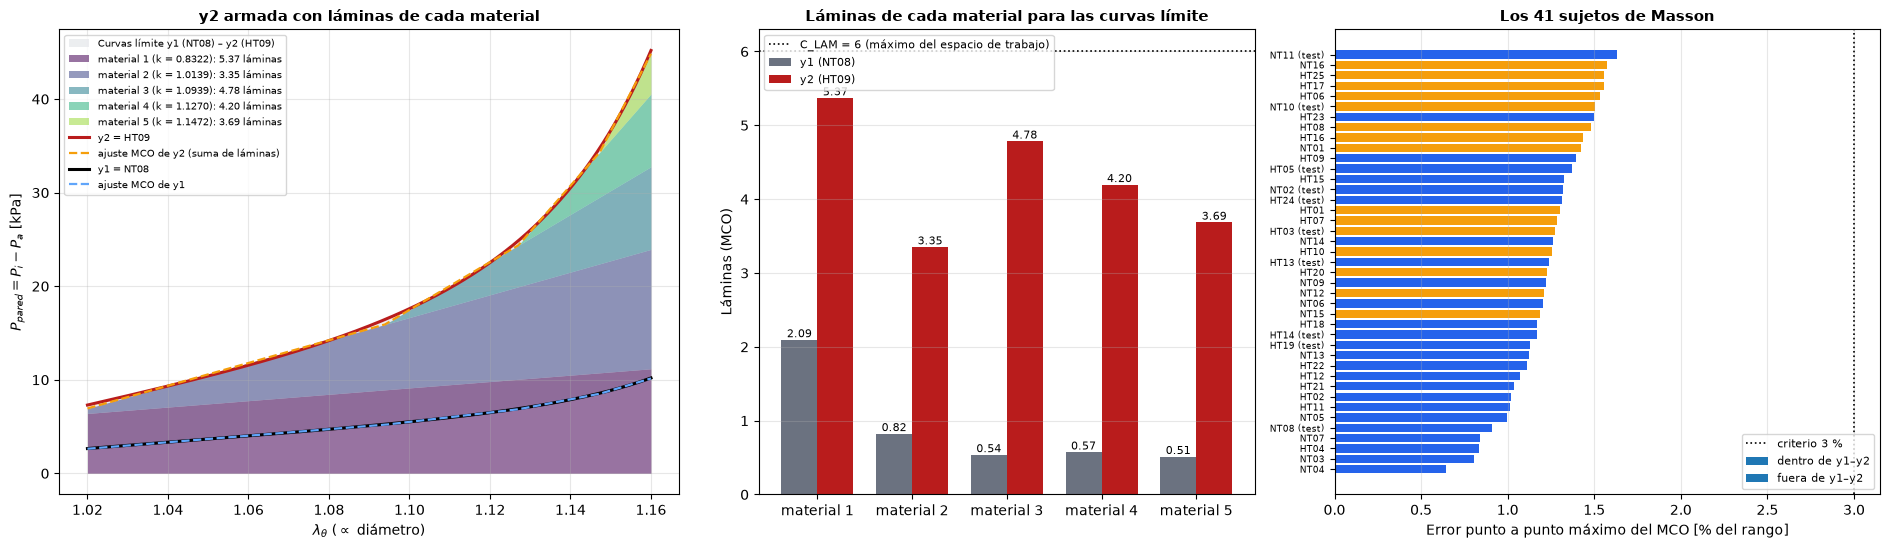

✅ Láminas MCO: y1 = [2.094 0.823 0.537 0.573 0.512] | y2 = [5.37  3.351 4.784 4.195 3.685] (C_LAM = 6)
   Sujetos con error punto a punto ≤ 3%: 41 de 41 | dentro de y1–y2 en todo el dominio: 26 de 41


In [7]:
# ==============================================================================
# CÉLULA 1b: LÁMINAS DE LAS CURVAS LÍMITE Y ERROR PUNTO A PUNTO DE LOS 41 SUJETOS (figura de verificación)
# ==============================================================================
"""
Izquierda: y2 (HT09) armada con sus láminas (aporte de cada material) y y1 (NT08) con su ajuste MCO.
Centro: láminas MCO de cada material para y1 e y2; la línea punteada es C_LAM (máximo del espacio de trabajo).
Derecha: error punto a punto máximo del MCO en los 41 sujetos, ordenado, frente al criterio ERROR_MAX_PCT.
"""
import numpy as np
import matplotlib.pyplot as plt

_N = A_opt.shape[1]
_col = plt.cm.viridis(np.linspace(0.0, 0.85, _N))
fig, ax = plt.subplots(1, 3, figsize=(19, 5.6), gridspec_kw=dict(width_ratios=[1.25, 1, 1.1]))

ax[0].fill_between(X_MESH_999, BANDA_INF, BANDA_SUP, color="#e5e7eb", alpha=0.7, lw=0, label=ETQ_BANDA)
_acum = np.zeros_like(X_MESH_999)
for j in range(_N):
    _nuevo = _acum + C_Y2[j] * A_opt[:, j]
    ax[0].fill_between(X_MESH_999, _acum, _nuevo, color=_col[j], alpha=0.55, lw=0,
                       label=f"material {j+1} (k = {NUDOS[j]:.4f}): {C_Y2[j]:.2f} láminas")
    _acum = _nuevo
ax[0].plot(X_MESH_999, Y2_LIMITE, "-", color="#b91c1c", lw=2.2, label=f"y2 = {SUJETO_Y2}")
ax[0].plot(X_MESH_999, A_opt @ C_Y2, "--", color="#f59e0b", lw=1.6, label="ajuste MCO de y2 (suma de láminas)")
ax[0].plot(X_MESH_999, Y1_LIMITE, "k-", lw=2.2, label=f"y1 = {SUJETO_Y1}")
ax[0].plot(X_MESH_999, A_opt @ C_Y1, "--", color="#60a5fa", lw=1.6, label="ajuste MCO de y1")
ax[0].set_xlabel(ETQ_X, fontsize=10)
ax[0].set_ylabel(ETQ_Y, fontsize=10)
ax[0].set_title("y2 armada con láminas de cada material", fontsize=11, fontweight="bold")
ax[0].legend(fontsize=7.5, loc="upper left")
ax[0].grid(True, alpha=0.3)

_i = np.arange(1, _N + 1)
_w = 0.38
ax[1].bar(_i - _w / 2, C_Y1, _w, color="#6b7280", label=f"y1 ({SUJETO_Y1})")
ax[1].bar(_i + _w / 2, C_Y2, _w, color="#b91c1c", label=f"y2 ({SUJETO_Y2})")
for j in range(_N):
    ax[1].text(_i[j] - _w / 2, C_Y1[j], f"{C_Y1[j]:.2f}", ha="center", va="bottom", fontsize=8)
    ax[1].text(_i[j] + _w / 2, C_Y2[j], f"{C_Y2[j]:.2f}", ha="center", va="bottom", fontsize=8)
ax[1].axhline(C_LAM, color="k", ls=":", lw=1.2, label=f"C_LAM = {C_LAM:g} (máximo del espacio de trabajo)")
ax[1].set_xticks(_i)
ax[1].set_xticklabels([f"material {j}" for j in _i])
ax[1].set_ylabel("Láminas (MCO)", fontsize=10)
ax[1].set_title("Láminas de cada material para las curvas límite", fontsize=11, fontweight="bold")
ax[1].legend(fontsize=8, loc="upper left")
ax[1].grid(True, axis="y", alpha=0.3)

_d = DF_PISO.sort_values("MaxAE_rel_pct").reset_index(drop=True)
_c = np.where(_d["en_espacio"], "#2563eb", "#f59e0b")
ax[2].barh(np.arange(len(_d)), _d["MaxAE_rel_pct"], color=_c)
ax[2].set_yticks(np.arange(len(_d)))
ax[2].set_yticklabels([f"{i}{' (test)' if t else ''}" for i, t in zip(_d["id"], _d["test"])], fontsize=6.5)
ax[2].axvline(ERROR_MAX_PCT, color="k", ls=":", lw=1.2, label=f"criterio {ERROR_MAX_PCT:g} %")
ax[2].barh([], [], color="#2563eb", label="dentro de y1–y2")
ax[2].barh([], [], color="#f59e0b", label="fuera de y1–y2")
ax[2].set_xlabel("Error punto a punto máximo del MCO [% del rango]", fontsize=10)
ax[2].set_title("Los 41 sujetos de Masson", fontsize=11, fontweight="bold")
ax[2].legend(fontsize=8, loc="lower right")
ax[2].grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(f"laminas_curvas_limite_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ Láminas MCO: y1 = {np.round(C_Y1, 3)} | y2 = {np.round(C_Y2, 3)} (C_LAM = {C_LAM:g})")
print(f"   Sujetos con error punto a punto ≤ {ERROR_MAX_PCT:g}%: {int(DF_PISO['cumple_criterio'].sum())} de {len(DF_PISO)} | "
      f"dentro de y1–y2 en todo el dominio: {int(DF_PISO['en_espacio'].sum())} de {len(DF_PISO)}")

## Célula 3 — Librerías, entorno TensorFlow, transformación logarítmica y métricas

In [8]:
# ==============================================================================
# CÉLULA 3: LIBRERÍAS, ENTORNO TENSORFLOW, TRANSFORMACIÓN LOGARÍTMICA Y MÉTRICAS ÚNICAS
# ==============================================================================
import os
# Variables de entorno ANTES de importar TensorFlow (si no, no tienen efecto)
os.environ['PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION'] = 'python'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import pickle
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import lsq_linear
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import tensorflow as tf

warnings.filterwarnings('ignore')

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f"Aviso GPU: {e}")
else:
    print("ℹ️ Sin GPU visible para TensorFlow: el entrenamiento corre en CPU (no cambia los resultados).")

np.random.seed(SEED)
tf.random.set_seed(SEED)
RNG = np.random.default_rng(SEED)

# ------------------------------------------------------------------------------
# TRANSFORMACIÓN LOGARÍTMICA DE LAS ENTRADAS: X = log(y + OFFSET_LOG)
# ------------------------------------------------------------------------------
# OFFSET_LOG = max(0, −mínimo de y1 y de los pacientes) + 5 kPa. Con P_pared > 0 en toda la población vale 5:
# no evita logaritmos de negativos, sino que suaviza la compresión del log en el pie de la curva.
_y_min_possible = float(min(envolvente_inferior(X_MESH_999).min(), POB_Y.min()))   # V19: algunos pacientes < 0 cerca de 1,00
OFFSET_LOG = float(max(0.0, -_y_min_possible) + 5.0)
EPSILON_LOG = 1e-6


def safe_log_transform(y_data, offset=None):
    """Transformación logarítmica blindada contra NaNs e Infs."""
    if offset is None:
        offset = OFFSET_LOG
    y_safe = np.maximum(np.asarray(y_data) + offset, EPSILON_LOG)
    return np.nan_to_num(np.log(y_safe), nan=0.0, posinf=15.0, neginf=-15.0)


# ------------------------------------------------------------------------------
# ÓPTIMO DE MÍNIMOS CUADRADOS Y MÉTRICAS (ÚNICA DEFINICIÓN PARA TODO EL NOTEBOOK)
# ------------------------------------------------------------------------------
METODO_LSQ = "bvls"   # mismo óptimo que 'trf' (diferencias < 1e-8) y ~10× más rápido con pocas variables


def optimo_mc(A, y):
    """Óptimo de mínimos cuadrados de referencia (etiquetas y comparación con la red).
    V20: COTA_INF = −∞, COTA_SUP = +∞ ⇒ mínimos cuadrados ORDINARIOS, c = A⁺y (sin cotas)."""
    if np.isinf(COTA_INF) and np.isinf(COTA_SUP):
        return np.linalg.lstsq(A, y, rcond=None)[0]
    return np.clip(lsq_linear(A, y, bounds=(COTA_INF, COTA_SUP), method=METODO_LSQ).x, COTA_INF, COTA_SUP)


def pulir(A, y, c0, tol_c=1e-6, tol_kkt=1e-7):
    """Pulido de una predicción de la red hasta el óptimo exacto de mínimos cuadrados (V15).
    V20 (MCO, sin cotas): no hay coeficientes en cotas, así que el pulido es un paso de mínimos cuadrados
    sobre todas las capas, c = A⁺y, y KKT se reduce a las ecuaciones normales Aᵀ(Ac − y) = 0.

    1) Proyecta c0 sobre la caja. 2) Toma como conjunto activo los coeficientes que quedaron en una cota
    y resuelve mínimos cuadrados SIN restricciones solo en los libres (sistema de ≤ N_BASES incógnitas).
    3) Verifica KKT (cotas inferiores con gradiente ≥ 0, superiores con gradiente ≤ 0, libres dentro de la
    caja). Si se cumple, el resultado ES el óptimo acotado y la red identificó bien el conjunto activo.
    Si no, recurre a bvls completo.
    Devuelve (c, red_acerto_conjunto_activo)."""
    c = np.clip(np.asarray(c0, dtype=float), COTA_INF, COTA_SUP)
    inf = c <= COTA_INF + tol_c
    sup = c >= COTA_SUP - tol_c
    c[inf], c[sup] = COTA_INF, COTA_SUP
    libre = ~(inf | sup)
    if libre.any():
        r = y - A[:, ~libre] @ c[~libre]
        c[libre] = np.linalg.lstsq(A[:, libre], r, rcond=None)[0]
    g = A.T @ (A @ c - y)
    escala_g = max(float(np.abs(A.T @ y).max()), 1e-12)
    ok = (np.all(c[libre] >= COTA_INF - tol_c) and np.all(c[libre] <= COTA_SUP + tol_c)
          and np.all(g[inf] >= -tol_kkt * escala_g) and np.all(g[sup] <= tol_kkt * escala_g))
    if ok:
        return np.clip(c, COTA_INF, COTA_SUP), True
    return optimo_mc(A, y), False


def metricas_curva(y_real, y_aprox):
    """Métricas de UNA curva. NRMSE y MaxAE_rel en % del rango de la propia curva."""
    y_real = np.asarray(y_real, dtype=float)
    err = y_real - np.asarray(y_aprox, dtype=float)
    rango = float(y_real.max() - y_real.min())
    ss_tot = float(np.sum((y_real - y_real.mean()) ** 2))
    rmse = float(np.sqrt(np.mean(err ** 2)))
    maxae = float(np.max(np.abs(err)))
    return {"R2": 1.0 - float(np.sum(err ** 2)) / ss_tot if ss_tot > 0 else np.nan,
            "RMSE": rmse, "MAE": float(np.mean(np.abs(err))), "MaxAE": maxae,
            "NRMSE": rmse / rango * 100.0 if rango > 0 else np.nan,
            "MaxAE_rel": maxae / rango * 100.0 if rango > 0 else np.nan}


def metricas_lote(Y_real, Y_aprox):
    """Mismas métricas que metricas_curva, vectorizadas por filas (una curva por fila)."""
    Y_real = np.asarray(Y_real, dtype=float)
    err = Y_real - np.asarray(Y_aprox, dtype=float)
    rango = Y_real.max(axis=1) - Y_real.min(axis=1)
    ss_tot = np.sum((Y_real - Y_real.mean(axis=1, keepdims=True)) ** 2, axis=1)
    rmse = np.sqrt(np.mean(err ** 2, axis=1))
    maxae = np.max(np.abs(err), axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        return {"R2": np.where(ss_tot > 0, 1.0 - np.sum(err ** 2, axis=1) / ss_tot, np.nan),
                "RMSE": rmse, "MAE": np.mean(np.abs(err), axis=1), "MaxAE": maxae,
                "NRMSE": np.where(rango > 0, rmse / rango * 100.0, np.nan),
                "MaxAE_rel": np.where(rango > 0, maxae / rango * 100.0, np.nan)}


print("✅ Entorno inicializado.")
print(f" Malla unificada: {N_PUNTOS_MALLA} puntos en x ∈ [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}]")
print(f"🛡️ OFFSET_LOG = {OFFSET_LOG:.4f} (mínimo de y1 y de los pacientes: {_y_min_possible:.4f} kPa)")
print(" Óptimo de referencia: mínimos cuadrados ORDINARIOS, c = A⁺y (sin cotas) | pulido de la red: un paso de MCO "
      "(ecuaciones normales, función pulir)" if np.isinf(COTA_INF) and np.isinf(COTA_SUP) else
      f" Óptimo acotado: lsq_linear (método '{METODO_LSQ}') | pulido de la red: conjunto activo + KKT (función pulir)")
print(" Métricas: NRMSE = RMSE / rango de la propia curva (%); MaxAE_rel = error máximo / rango (%).")

ℹ️ Sin GPU visible para TensorFlow: el entrenamiento corre en CPU (no cambia los resultados).
✅ Entorno inicializado.
 Malla unificada: 999 puntos en x ∈ [1.02, 1.16]
🛡️ OFFSET_LOG = 5.0000 (mínimo de y1 y de los pacientes: 0.1657 kPa)
 Óptimo de referencia: mínimos cuadrados ORDINARIOS, c = A⁺y (sin cotas) | pulido de la red: un paso de MCO (ecuaciones normales, función pulir)
 Métricas: NRMSE = RMSE / rango de la propia curva (%); MaxAE_rel = error máximo / rango (%).


## Célula 4 — Dataset sintético V21, etiquetas MCO en láminas (curvas fisiológicas dentro de y1–y2) (curvas presión–diámetro: constitutivas, amplias y exponenciales)

In [9]:
# ==============================================================================
# CÉLULA 4: DATASET SINTÉTICO — CURVAS PRESIÓN–DIÁMETRO (GENERADOR CONSTITUTIVO AMPLIADO + COBERTURA DE COEFICIENTES)
# ==============================================================================
"""
Regla de oro: la etiqueta c es SIEMPRE el óptimo de MÍNIMOS CUADRADOS ORDINARIOS (MCO, c = A⁺y, sin cotas)
de la MISMA curva que ve la red, ruido incluido. Las etiquetas son NÚMEROS DE LÁMINAS (reales) de cada material.

Familias (vector 'familia'):
  Desde V16, todas las curvas son P_pared(λθ) = Pi − Pa (Célula M, curva_objetivo); las bases son capas del injerto.
  0) pura                : un solo material, láminas log-uniformes en [C_MIN_PURA_LAM, C_GEN_MAX_j] + ruido
                           (V21: cubre también láminas pocas y curvas chicas; V20 fallaba con amplitudes < 0,6)
  1) combinada           : 2..N materiales, láminas ~ U(0, C_GEN_MAX_j), reescaladas si superan Y_TECHO_KPA.
                           (C_GEN_MAX_j = máx. entre C_LAM y las láminas de los sujetos de entrenamiento)
  2) constitutiva        : P_pared del modelo de Masson (incluye R_m y Θ0 en la mezcla) con parámetros = mezcla convexa (Dirichlet) de 2–3
                           sujetos de ENTRENAMIENTO + perturbación chica + factor de amplitud ~[0,85; 1,2].
  3) constitutiva_amplia : 2–4 sujetos, perturbación mayor, mezcla EXTRAPOLADA desde el centro poblacional
                           (factor γ ~ U(1; 1,35)) y factor de amplitud ~[0,65; 1,5]: cubre arterias más
                           blandas y más rígidas que las de entrenamiento (V14 fallaba en NT08 y en los extremos).
  4) exponencial         : OTRA ley, P = C + μ·E + k1·E·exp(k2·E²) con E = λ² − 1 (tipo
                           Holzapfel–Gasser–Ogden 1D), ajustada a los sujetos de entrenamiento y mezclada
                           (media geométrica Dirichlet + perturbación + amplitud). Aporta diversidad de FORMA:
                           V14 generalizaba mal a una ley distinta (Fung, Célula 12b), que sigue sin verse.
Las familias 0 y 1 cubren el espacio de coeficientes; 2, 3 y 4 son el dominio objetivo (curvas J
fisiológicas). Se aceptan solo curvas P > 0, monótonas, convexas desde X_INICIO_CONVEXIDAD y con
P_max <= SIGMA_MAX_KPA (nombre histórico: techo de la variable objetivo). Los sujetos reservados para test NO se usan en el generador.
Y_limpio guarda cada curva SIN ruido (para medir el error contra la curva verdadera).
"""
import os
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

# --- Parámetros del dataset ---------------------------------------------------
N_SAMPLES = 30000
FRAC_PURAS = 0.20
FRAC_COMBINADAS = 0.20
FRAC_PACIENTES = 0.05          # V19: los 31 pacientes de entrenamiento (curvas reales) replicados con ruido
FRAC_CONSTITUTIVA = 0.20
FRAC_UNIFORME = 0.10           # V19: ley de Masson con parámetros uniformes independientes en [mín, máx]
FRAC_EXPONENCIAL = 0.10        # V19: menos curvas de la ley exponencial (antes 15 %)
FRAC_CONST_AMPLIA = 1.0 - FRAC_PURAS - FRAC_COMBINADAS - FRAC_PACIENTES - FRAC_CONSTITUTIVA - FRAC_UNIFORME - FRAC_EXPONENCIAL
MAX_INTENTOS_UNIFORME = 20000
C_MIN_PURA_LAM = 0.10                              # mínimo de láminas de la familia pura (absoluto)
FACTOR_TECHO = 1.5                                 # techo de amplitud relativo al máximo poblacional
Y_TECHO_KPA = FACTOR_TECHO * float(POB_Y.max())
SIGMA_MAX_KPA = Y_TECHO_KPA
RUIDO_REL_PURAS = 0.005
RUIDO_REL_CONSTITUTIVA = 0.01
# Perturbación de los parámetros mezclados: multiplicativa (log-normal) en módulos y Pa; aditiva
# (en desvíos estándar poblacionales) en exponentes, ángulo y estiramientos.
PARAM_MULT = ["Rm_mm", "c_kPa", "c1_kPa", "c1circ_kPa", "Tm_kPa", "a_kPa"]
PARAM_ADIT = ["Theta0_deg", "lambda_ax", "c2", "c2circ", "alpha_deg", "lambda0", "lambda_m", "b"]
# amp: factor de amplitud log-uniforme; gamma: extrapolación de la mezcla desde el centro poblacional
PERTURB = {"constitutiva": dict(k=(2, 3), sd_mult=0.10, sd_adit=0.15, amp=(0.85, 1.20), gamma=(1.0, 1.0)),
           "constitutiva_amplia": dict(k=(2, 4), sd_mult=0.20, sd_adit=0.30, amp=(0.65, 1.50), gamma=(1.0, 1.35))}
PERTURB_EXP = dict(k=(2, 3), sd_log=0.15, amp=(0.70, 1.40))
MAX_INTENTOS = 200
SEED_DATASET = 2026
FAMILIAS = {0: "pura", 1: "combinada", 2: "constitutiva", 3: "constitutiva_amplia", 4: "exponencial",
            5: "constitutiva_uniforme", 6: "pacientes"}
FAMILIAS_OBJETIVO = (2, 3, 4, 5, 6)     # familias fisiológicas (dominio objetivo del método)
FAMILIAS_ACOTADAS = (2, 3, 5)           # sintéticas con la ley de Masson: deben cumplir y1 <= y <= y2

rng_ds = np.random.default_rng(SEED_DATASET)
print(f"⚙️ Generando dataset {VERSION.upper()}: {N_SAMPLES} curvas "
      f"({FRAC_PURAS:.0%} puras / {FRAC_COMBINADAS:.0%} combinadas / {FRAC_PACIENTES:.0%} pacientes reales / "
      f"{FRAC_CONSTITUTIVA:.0%} constitutivas / {FRAC_CONST_AMPLIA:.0%} constitutivas amplias / "
      f"{FRAC_UNIFORME:.0%} constitutivas uniformes / {FRAC_EXPONENCIAL:.0%} exponenciales)...")

# --- 1. Carga de la matriz de bases ----------------------------------------------
if not os.path.exists(ARCHIVO_BASES):
    raise FileNotFoundError(f"No se encontró '{ARCHIVO_BASES}'. Ejecutá la Célula 2.")
df_base = pd.read_excel(ARCHIVO_BASES, header=None)
x_base_file = df_base.iloc[:, 0].values.astype(np.float64)
A_base_full = df_base.iloc[:, 1:].values.astype(np.float64)
n_bases = A_base_full.shape[1]
if len(x_base_file) != N_PUNTOS_MALLA or not np.allclose(x_base_file, X_MESH_999):
    raise ValueError("La malla del archivo de bases no coincide con X_MESH_999: ejecutá la Célula 2.")
A_base = A_base_full.copy()
print(f"📂 Bases cargadas: {n_bases} bases en {N_PUNTOS_MALLA} puntos.")

n_puras = int(round(FRAC_PURAS * N_SAMPLES))
n_comb = int(round(FRAC_COMBINADAS * N_SAMPLES))
n_const = int(round(FRAC_CONSTITUTIVA * N_SAMPLES))
n_exp = int(round(FRAC_EXPONENCIAL * N_SAMPLES))
n_pac = int(round(FRAC_PACIENTES * N_SAMPLES))
n_unif = int(round(FRAC_UNIFORME * N_SAMPLES))
n_amplia = N_SAMPLES - n_puras - n_comb - n_const - n_exp - n_pac - n_unif

Y_raw = np.zeros((N_SAMPLES, N_PUNTOS_MALLA), dtype=np.float64)
Y_limpio = np.zeros((N_SAMPLES, N_PUNTOS_MALLA), dtype=np.float64)
C_targets = np.zeros((N_SAMPLES, n_bases), dtype=np.float64)
C_generador = np.full((N_SAMPLES, n_bases), np.nan)
familia = np.zeros(N_SAMPLES, dtype=np.int8)
pos = 0
DIAG_GEN = {}


def _guardar(Y, C, fam_id, Y0, C_gen=None):
    global pos
    n = len(Y)
    Y_raw[pos:pos + n], C_targets[pos:pos + n], familia[pos:pos + n] = Y, C, fam_id
    Y_limpio[pos:pos + n] = Y0
    if C_gen is not None:
        C_generador[pos:pos + n] = C_gen
    pos += n


def _etiquetar(Y):
    return np.array([optimo_mc(A_base, y) for y in Y])


def _ruido(Y, rel):
    return np.maximum(Y + rng_ds.normal(0.0, rel, size=Y.shape) * np.abs(Y), TENSION_MIN_KPA)


# --- A) PURAS --------------------------------------------------------------------
BASES_PURAS = np.arange(n_bases)                     # sin base constante: todas las capas
base_idx = rng_ds.permutation(BASES_PURAS[np.arange(n_puras) % len(BASES_PURAS)])
C_p = np.zeros((n_puras, n_bases))
C_p[np.arange(n_puras), base_idx] = np.exp(rng_ds.uniform(np.log(C_MIN_PURA_LAM), np.log(C_GEN_MAX[base_idx])))
Y_p = _ruido(C_p @ A_base.T, RUIDO_REL_PURAS)
_guardar(Y_p, _etiquetar(Y_p), 0, C_p @ A_base.T, C_p)

# --- B) COMBINADAS ----------------------------------------------------------------
C_c = np.zeros((n_comb, n_bases))
for i in range(n_comb):
    k = rng_ds.integers(2, n_bases + 1)
    act = rng_ds.choice(n_bases, size=k, replace=False)
    C_c[i, act] = rng_ds.uniform(0.0, 1.0, size=k) * C_GEN_MAX[act]
y_max_c = (C_c @ A_base.T).max(axis=1, keepdims=True)
C_c = C_c * np.minimum(1.0, Y_TECHO_KPA / np.maximum(y_max_c, 1e-9))
Y_c = _ruido(C_c @ A_base.T, RUIDO_REL_PURAS)
_guardar(Y_c, _etiquetar(Y_c), 1, C_c @ A_base.T, C_c)

# --- C) y D) CONSTITUTIVAS ---------------------------------------------------------
POB_TRAIN = POB[MASK_POB_TRAIN].reset_index(drop=True)
TH_TRAIN = POB_TRAIN[COLS_PARAM].to_numpy(float)
SD_PARAM = POB[COLS_PARAM].to_numpy(float).std(axis=0)
i_mult = [COLS_PARAM.index(c) for c in PARAM_MULT]
i_adit = [COLS_PARAM.index(c) for c in PARAM_ADIT]
i_l0, i_lm = COLS_PARAM.index("lambda0"), COLS_PARAM.index("lambda_m")
i_alpha, i_lz = COLS_PARAM.index("alpha_deg"), COLS_PARAM.index("lambda_ax")
i_c2s = [COLS_PARAM.index("c2"), COLS_PARAM.index("c2circ")]
i_th0 = COLS_PARAM.index("Theta0_deg")


def _a_espacio(th):          # módulos y Pa en escala log; el resto lineal
    z = np.array(th, dtype=float)
    z[..., i_mult] = np.log(np.maximum(z[..., i_mult], 1e-9))
    return z


def _de_espacio(z):
    th = np.array(z, dtype=float)
    th[..., i_mult] = np.exp(th[..., i_mult])
    return th


Z_TRAIN = _a_espacio(TH_TRAIN)
Z_CENTRO = Z_TRAIN.mean(axis=0)


def sortear_parametros(cfg):
    k = rng_ds.integers(cfg["k"][0], cfg["k"][1] + 1)
    idx = rng_ds.choice(len(TH_TRAIN), size=k, replace=False)
    z = rng_ds.dirichlet(np.ones(k)) @ Z_TRAIN[idx]
    gamma = rng_ds.uniform(*cfg["gamma"])                    # γ > 1: se aleja del centro (extrapola)
    z = Z_CENTRO + gamma * (z - Z_CENTRO)
    z[i_mult] += rng_ds.normal(0.0, cfg["sd_mult"], size=len(i_mult))
    z[i_adit] += rng_ds.normal(0.0, cfg["sd_adit"], size=len(i_adit)) * SD_PARAM[i_adit]
    th = _de_espacio(z)
    th[i_alpha] = np.clip(th[i_alpha], 5.0, 85.0)
    th[i_lz] = max(th[i_lz], 1.0)
    th[i_c2s] = np.maximum(th[i_c2s], 0.5)
    th[i_th0] = np.clip(th[i_th0], 60.0, 300.0)
    return th


def _amplitud(cfg):
    lo, hi = cfg["amp"]
    return float(np.exp(rng_ds.uniform(np.log(lo), np.log(hi))))


def _curva_valida(y, acotar=True):
    """Curva fisiológica válida: positiva, monótona y convexa; si acotar, además DENTRO de y1 <= y <= y2
    (se aplica solo a las curvas sintéticas con la ley de Masson)."""
    ok = y.min() > 0 and y.max() <= SIGMA_MAX_KPA and all(diagnostico_forma(y))
    return ok and (not (acotar and USAR_ESPACIO_Y1Y2) or bool(dentro_espacio(y)[0]))


def generar_constitutivas(n, nombre):
    cfg = PERTURB[nombre]
    Y = np.zeros((n, N_PUNTOS_MALLA))
    rechazos = 0
    for i in range(n):
        for _ in range(MAX_INTENTOS):
            th = sortear_parametros(cfg)
            if th[i_lm] <= th[i_l0] + 0.2:
                rechazos += 1
                continue
            y0 = _amplitud(cfg) * curva_objetivo(X_MESH_999, dict(zip(COLS_PARAM, th)))
            if not np.all(np.isfinite(y0)) or not _curva_valida(y0):
                rechazos += 1
                continue
            break
        else:
            raise RuntimeError(f"{nombre}: {MAX_INTENTOS} sorteos sin una curva válida.")
        Y[i] = y0
    DIAG_GEN[nombre] = dict(aceptacion=n / (n + rechazos), Y_limpia=Y.copy())
    Yr = _ruido(Y, RUIDO_REL_CONSTITUTIVA)
    return Yr, _etiquetar(Yr), Y


def _guardar_familia(salida, fam_id):
    Yr, C, Y0 = salida
    _guardar(Yr, C, fam_id, Y0)


_guardar_familia(generar_constitutivas(n_const, "constitutiva"), 2)
_guardar_familia(generar_constitutivas(n_amplia, "constitutiva_amplia"), 3)


# --- E) EXPONENCIAL: otra ley constitutiva (tipo HGO 1D) ---------------------------------
def ley_exponencial(x, C, mu, k1, k2):
    E = x ** 2 - 1.0
    return C + mu * E + k1 * E * np.exp(k2 * E ** 2)


P_EXP = []
for y in POB_Y[MASK_POB_TRAIN]:
    p, _ = curve_fit(ley_exponencial, X_MESH_999, y, p0=(max(y[0] - 5.0, 1.0), 50.0, 20.0, 10.0),
                     bounds=([0.0, 0.0, 1e-3, 1e-3], [1e3, 2e3, 2e3, 200.0]), maxfev=40000)
    P_EXP.append(np.maximum(p, 1e-3))
P_EXP = np.array(P_EXP)
R2_EXP = [1 - np.sum((y - ley_exponencial(X_MESH_999, *p)) ** 2) / np.sum((y - y.mean()) ** 2)
          for y, p in zip(POB_Y[MASK_POB_TRAIN], P_EXP)]


def generar_exponenciales(n):
    cfg = PERTURB_EXP
    Y = np.zeros((n, N_PUNTOS_MALLA))
    rechazos = 0
    for i in range(n):
        for _ in range(MAX_INTENTOS):
            k = rng_ds.integers(cfg["k"][0], cfg["k"][1] + 1)
            idx = rng_ds.choice(len(P_EXP), size=k, replace=False)
            logp = rng_ds.dirichlet(np.ones(k)) @ np.log(P_EXP[idx]) + rng_ds.normal(0.0, cfg["sd_log"], size=4)
            y0 = _amplitud(cfg) * ley_exponencial(X_MESH_999, *np.exp(logp))
            if not np.all(np.isfinite(y0)) or not _curva_valida(y0, acotar=False):   # no es la ley de Masson
                rechazos += 1
                continue
            break
        else:
            raise RuntimeError(f"exponencial: {MAX_INTENTOS} sorteos sin una curva válida.")
        Y[i] = y0
    DIAG_GEN["exponencial"] = dict(aceptacion=n / (n + rechazos), Y_limpia=Y.copy())
    Yr = _ruido(Y, RUIDO_REL_CONSTITUTIVA)
    return Yr, _etiquetar(Yr), Y


_guardar_familia(generar_exponenciales(n_exp), 4)


# --- F) LEY DE MASSON CON PARÁMETROS UNIFORMES INDEPENDIENTES -------------------------------
TH_MIN, TH_MAX = TH_TRAIN.min(axis=0), TH_TRAIN.max(axis=0)


def generar_uniformes(n):
    """Cada parámetro de Masson sorteado al azar, independiente, en [mín, máx] de los sujetos de entrenamiento
    (módulos y Pa en escala log). Solo se aceptan curvas válidas DENTRO de y1–y2."""
    Y = np.zeros((n, N_PUNTOS_MALLA))
    rechazos = 0
    z_lo, z_hi = _a_espacio(TH_MIN), _a_espacio(TH_MAX)
    for i in range(n):
        for _ in range(MAX_INTENTOS_UNIFORME):
            th = _de_espacio(rng_ds.uniform(z_lo, z_hi))
            if th[i_lm] <= th[i_l0] + 0.2:
                rechazos += 1
                continue
            y0 = curva_objetivo(X_MESH_999, dict(zip(COLS_PARAM, th)))
            if not np.all(np.isfinite(y0)) or not _curva_valida(y0):
                rechazos += 1
                continue
            break
        else:
            raise RuntimeError(f"constitutiva_uniforme: {MAX_INTENTOS_UNIFORME} sorteos sin una curva válida.")
        Y[i] = y0
    DIAG_GEN["constitutiva_uniforme"] = dict(aceptacion=n / (n + rechazos), Y_limpia=Y.copy())
    Yr = _ruido(Y, RUIDO_REL_CONSTITUTIVA)
    return Yr, _etiquetar(Yr), Y


_guardar_familia(generar_uniformes(n_unif), 5)


# --- G) PACIENTES REALES DE ENTRENAMIENTO (31), REPLICADOS CON RUIDO ---------------------------
# Las curvas reales entran tal cual (no se acotan por y1–y2 ni se recortan en 0: algunos pacientes tienen
# P_pared levemente negativa cerca de λ = 1,00, en el tramo extrapolado del modelo).
Y_PAC = POB_Y[MASK_POB_TRAIN]
_rep = np.resize(np.arange(len(Y_PAC)), n_pac)
Y0_pac = Y_PAC[_rep]
Yr_pac = Y0_pac + rng_ds.normal(0.0, RUIDO_REL_CONSTITUTIVA, size=Y0_pac.shape) * np.abs(Y0_pac)
_guardar(Yr_pac, _etiquetar(Yr_pac), 6, Y0_pac)
DIAG_GEN["pacientes"] = dict(aceptacion=1.0, Y_limpia=Y0_pac.copy())
assert pos == N_SAMPLES

X_curvas = Y_raw
Y_coef = C_targets

# --- 2. Transformación logarítmica de las entradas -----------------------------
X_log = safe_log_transform(Y_raw, offset=OFFSET_LOG)

# --- 3. Chequeos e informes ----------------------------------------------------
assert np.isfinite(X_log).all() and np.isfinite(C_targets).all(), "NaN/Inf en el dataset"

print(f"\n✅ Dataset {VERSION.upper()} generado: X_log {X_log.shape} | C_targets {C_targets.shape}")
for f, nombre in FAMILIAS.items():
    m = familia == f
    fuera = np.mean((Y_raw[m] < BANDA_INF - 1e-9) | (Y_raw[m] > BANDA_SUP + 1e-9))
    extra = f" | aceptación del generador {DIAG_GEN[nombre]['aceptacion']:.1%}" if nombre in DIAG_GEN else ""
    print(f"   • {nombre:<20}: {m.sum():>6} curvas | puntos fuera de [y1, y2]: {fuera:6.1%}{extra}")

print(f"\n📐 Ley exponencial ajustada a {len(P_EXP)} sujetos de entrenamiento: R² mín. {min(R2_EXP):.4f} | "
      f"mediana {np.median(R2_EXP):.4f}")
print("\n📏 Láminas MCO por material (p5/p50/p95) — todas las familias | fisiológicas:")
m_c = np.isin(familia, FAMILIAS_OBJETIVO)
for j in range(n_bases):
    p5, p50, p95 = np.percentile(C_targets[:, j], [5, 50, 95])
    q5, q50, q95 = np.percentile(C_targets[m_c, j], [5, 50, 95])
    print(f"   material {j+1}: {p5:6.2f} / {p50:6.2f} / {p95:6.2f}  |  {q5:6.2f} / {q50:6.2f} / {q95:6.2f}")

# Espacio de trabajo = curvas de Masson dentro de y1–y2 (familias 2, 3 y 5), SIN ruido
m_esp = np.isin(familia, FAMILIAS_ACOTADAS)
_C_esp = (np.linalg.pinv(A_base) @ Y_limpio[m_esp].T).T
print(f"\n🧵 Espacio de trabajo ({m_esp.sum()} curvas de Masson dentro de y1–y2, sin ruido): máximo de láminas por material "
      f"{np.round(_C_esp.max(axis=0), 2)} (objetivo C_LAM = {C_LAM:g}; p99,9: {np.round(np.percentile(_C_esp, 99.9, axis=0), 2)})")

print(f"\n🎯 Criterio error punto a punto ≤ {ERROR_MAX_PCT:g}% del MCO sobre la curva SIN ruido, y fabricabilidad (c ≥ 0), por familia:")
_P_A = np.linalg.pinv(A_base)
for f, nombre in FAMILIAS.items():
    m = familia == f
    Y0 = Y_limpio[m]
    R0 = Y0 - (A_base @ (_P_A @ Y0.T)).T
    e0 = np.abs(R0).max(axis=1) / np.maximum(np.ptp(Y0, axis=1), 1e-12) * 100
    fab = np.all(C_targets[m] >= COEF_MIN - 1e-9, axis=1)
    print(f"   • {nombre:<20}: cumplen {np.mean(e0 <= ERROR_MAX_PCT):7.2%} (máx. {e0.max():5.2f}%) | "
          f"fabricables {fab.mean():6.1%} (c mín. {C_targets[m].min():+.3f})")

print("\n🔍 Consistencia entrada↔etiqueta (re-resolviendo el MCO sobre 200 curvas por familia; esperado ≈ 0):")
for f, nombre in FAMILIAS.items():
    idx = rng_ds.choice(np.where(familia == f)[0], size=min(200, int((familia == f).sum())), replace=False)
    dif = np.array([np.abs(optimo_mc(A_base, Y_raw[i]) - C_targets[i]).max() for i in idx])
    print(f"   • {nombre:<20}: |Δc| máx. medio = {dif.mean():.2e} | peor = {dif.max():.2e}")

# Independencia del test real: distancia relativa (RMSE / P_max) de cada sujeto a la curva sintética más cercana
Y_const_limpia = np.vstack([DIAG_GEN[n]["Y_limpia"] for n in ("constitutiva", "constitutiva_amplia", "exponencial",
                                                                "constitutiva_uniforme")])   # sin pacientes
def _dist_min(y, Ys):
    return float(np.min(np.sqrt(np.mean((Ys - y) ** 2, axis=1))) / y.max())
d_test = np.array([_dist_min(y, Y_const_limpia) for y in POB_Y[MASK_POB_TEST]])
d_train = np.array([_dist_min(y, Y_const_limpia) for y in POB_Y[MASK_POB_TRAIN]])
print(f"\n🧭 Distancia relativa de cada sujeto real a la curva sintética más cercana (mediana [mín, máx]):")
print(f"   • sujetos de entrenamiento: {np.median(d_train):.2%} [{d_train.min():.2%}, {d_train.max():.2%}]")
print(f"   • sujetos de test         : {np.median(d_test):.2%} [{d_test.min():.2%}, {d_test.max():.2%}]")
_ids_test = POB.loc[MASK_POB_TEST, "id"].to_numpy()
print(f"   • sujeto de test más alejado: {_ids_test[int(np.argmax(d_test))]} ({d_test.max():.2%})")
_amp = Y_limpio[np.isin(familia, FAMILIAS_OBJETIVO)].max(axis=1)
print(f"   • P máx. de las curvas fisiológicas sintéticas: p1 {np.percentile(_amp, 1):.0f} | p50 {np.median(_amp):.0f} | "
      f"p99 {np.percentile(_amp, 99):.0f} kPa (sujetos reales: {POB_Y.max(axis=1).min():.0f}–{POB_Y.max():.0f} kPa)")

⚙️ Generando dataset V21_5: 30000 curvas (20% puras / 20% combinadas / 5% pacientes reales / 20% constitutivas / 15% constitutivas amplias / 10% constitutivas uniformes / 10% exponenciales)...
📂 Bases cargadas: 5 bases en 999 puntos.

✅ Dataset V21_5 generado: X_log (30000, 999) | C_targets (30000, 5)
   • pura                :   6000 curvas | puntos fuera de [y1, y2]:  92.9%
   • combinada           :   6000 curvas | puntos fuera de [y1, y2]:  39.0%
   • constitutiva        :   6000 curvas | puntos fuera de [y1, y2]:   0.0% | aceptación del generador 64.9%
   • constitutiva_amplia :   4500 curvas | puntos fuera de [y1, y2]:   0.0% | aceptación del generador 47.8%
   • exponencial         :   3000 curvas | puntos fuera de [y1, y2]:  16.5% | aceptación del generador 99.6%
   • constitutiva_uniforme:   3000 curvas | puntos fuera de [y1, y2]:   0.0% | aceptación del generador 60.7%
   • pacientes           :   1500 curvas | puntos fuera de [y1, y2]:  10.0% | aceptación del generador 100.0

## Célula 5 — Partición train/val/test y normalización sin fuga

In [10]:
# ==============================================================================
# CÉLULA 5: PARTICIÓN TRAIN / VAL / TEST Y NORMALIZACIÓN (SIN FUGA DE INFORMACIÓN)
# ==============================================================================
"""
Los escaladores se ajustan SOLO con train. La validación (early stopping y
checkpoint) es distinta del test, que queda intacto para la evaluación final.
La partición es estratificada por familia de curva.
"""
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

idx_all = np.arange(len(X_log))
idx_trval, idx_test = train_test_split(
    idx_all, test_size=0.20, random_state=SEED, stratify=familia)
idx_train, idx_val = train_test_split(
    idx_trval, test_size=0.125, random_state=SEED, stratify=familia[idx_trval])   # 0.125·0.8 = 10 %

sx = StandardScaler().fit(X_log[idx_train])      # entradas
sy = StandardScaler().fit(Y_coef[idx_train])     # salidas (coeficientes)

X_train, X_val, X_test = (sx.transform(X_log[i]) for i in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = (sy.transform(Y_coef[i]) for i in (idx_train, idx_val, idx_test))
fam_train, fam_val, fam_test = familia[idx_train], familia[idx_val], familia[idx_test]

# V21: máscara de crosstalk = materiales que el GENERADOR dejó en cero (familias pura y combinada). Con etiquetas MCO
# esos canales no valen exactamente 0 (el ruido les da ±0,05), así que la máscara no puede salir de la etiqueta.
MASCARA_CERO = (np.isin(familia, (0, 1))[:, None] & (np.nan_to_num(C_generador, nan=1.0) == 0.0)).astype(np.float32)
m_train, m_val, m_test = MASCARA_CERO[idx_train], MASCARA_CERO[idx_val], MASCARA_CERO[idx_test]

print("✅ Datos normalizados y divididos (escaladores ajustados solo con train):")
print(f"   • Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")
print(f"   • X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"   • sy.mean_  : {np.round(sy.mean_, 4)}")
print(f"   • sy.scale_ : {np.round(sy.scale_, 4)}")
print(f"   • Canales con crosstalk penalizado (material inactivo en el generador): {MASCARA_CERO.mean():.1%} de los coeficientes")

✅ Datos normalizados y divididos (escaladores ajustados solo con train):
   • Train: 21000 | Val: 3000 | Test: 6000
   • X_train shape: (21000, 999) | y_train shape: (21000, 5)
   • sy.mean_  : [2.1724 1.9498 2.1399 2.0268 1.8514]
   • sy.scale_ : [1.6504 1.5147 1.9218 1.851  1.7282]
   • Canales con crosstalk penalizado (material inactivo en el generador): 22.1% de los coeficientes


## Célula 6 — Pérdida compuesta y arquitectura (LayerNormalization)

In [11]:
# ==============================================================================
# CÉLULA 6: PÉRDIDA COMPUESTA Y ARQUITECTURA (LAYER NORMALIZATION)
# ==============================================================================
"""
Pérdida = PESO_COEF · MSE(coeficientes estandarizados)
        + PESO_REC  · MSE(reconstrucción A·c relativa al y_max de cada curva)   [unidades físicas]
        + PESO_CROSSTALK · media(c_pred² en los materiales INACTIVOS del generador)  [láminas]
La reconstrucción y el crosstalk se calculan DESPUÉS de desestandarizar (unidades físicas).
V21: la máscara de crosstalk viaja junto con la etiqueta (y_true = [c estandarizado | máscara], 2·N columnas),
porque con etiquetas MCO los materiales inactivos no valen exactamente 0. Las métricas 'mae' y 'mse' se calculan
solo sobre las N primeras columnas.
V20 (MCO, sin cotas): las etiquetas pueden ser levemente negativas y NO se proyectan sobre c >= 0
(PROYECTAR_NO_NEGATIVOS = False); la reconstrucción usa A·c tal cual. La salida es lineal y en
inferencia no se recorta (Célula 8b informa cuántos coeficientes serían no fabricables, c < 0).
"""
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, LayerNormalization
from tensorflow.keras.regularizers import l2

# --- 1. PARÁMETROS (derivados de los datos, sin respaldos por globals()) -----------
L2_REGULARIZATION = 1e-5
PESO_COEF, PESO_REC, PESO_CROSSTALK = 1.0, 5.0, 20.0
UMBRAL_CERO_CROSSTALK = 1e-4
CAPAS_OCULTAS = (256, 128, 64)
LEARNING_RATE_INICIAL = 1e-3
PROYECTAR_NO_NEGATIVOS = bool(np.isfinite(COTA_INF))   # V20: False (MCO sin cotas)

N_BASES = y_train.shape[1]
N_PUNTOS = X_train.shape[1]
assert A_base.shape == (N_PUNTOS, N_BASES), \
    f"A_base {A_base.shape} no coincide con (N_PUNTOS, N_BASES) = ({N_PUNTOS}, {N_BASES})"

# A en forma (N_BASES, N_PUNTOS) para: coef (batch, N_BASES) @ A -> curva (batch, N_PUNTOS)
A_mat_np = A_base.T.astype(np.float32)
mean_arr = np.asarray(sy.mean_, dtype=np.float32)
scale_arr = np.asarray(sy.scale_, dtype=np.float32)


# --- 2. PÉRDIDA (constantes estáticas de TF) --------------------------------------------
def crear_loss_reconstruccion(A_np, mean_np, scale_np,
                              peso_coef=PESO_COEF, peso_rec=PESO_REC, peso_crosstalk=PESO_CROSSTALK):
    A_tf = tf.constant(A_np, dtype=tf.float32)
    mean_tf = tf.constant(mean_np, dtype=tf.float32)
    scale_tf = tf.constant(scale_np, dtype=tf.float32)

    n_out = len(mean_np)

    def loss(y_true_aug, y_pred):
        y_true = y_true_aug[:, :n_out]
        mascara_ceros = y_true_aug[:, n_out:]
        # A. Pérdida paramétrica en espacio estandarizado
        loss_coef = tf.reduce_mean(tf.square(y_true - y_pred))

        # B. Desestandarización a unidades físicas
        coef_true = y_true * scale_tf + mean_tf
        coef_pred = y_pred * scale_tf + mean_tf

        # C. No negatividad en unidades físicas (c_i >= 0) solo si el método tiene cotas (V20: MCO, no)
        coef_pred_pos = tf.maximum(coef_pred, 0.0) if PROYECTAR_NO_NEGATIVOS else coef_pred
        coef_true_pos = tf.maximum(coef_true, 0.0) if PROYECTAR_NO_NEGATIVOS else coef_true

        # D. Reconstrucción física
        b_true = tf.matmul(coef_true_pos, A_tf)
        b_pred = tf.matmul(coef_pred_pos, A_tf)

        # E. Error de reconstrucción relativo a la amplitud de cada curva
        y_max_safe = tf.maximum(tf.reduce_max(b_true, axis=1, keepdims=True), 1.0)
        loss_rec = tf.reduce_mean(tf.square((b_true - b_pred) / (y_max_safe + 1e-6)))

        # F. Crosstalk: materiales que el generador dejó en cero (familias pura y combinada)
        loss_cross = tf.reduce_mean(tf.square(coef_pred_pos) * mascara_ceros)

        return peso_coef * loss_coef + peso_rec * loss_rec + peso_crosstalk * loss_cross

    return loss


loss_pinn = crear_loss_reconstruccion(A_mat_np, mean_arr, scale_arr)


# --- 3. ARQUITECTURA ----------------------------------------------------------------------
def construir_modelo(input_shape, num_outputs):
    capas = [Input(shape=(input_shape,))]
    for n in CAPAS_OCULTAS:
        capas += [Dense(n, activation='relu', kernel_regularizer=l2(L2_REGULARIZATION)), LayerNormalization()]
    capas.append(Dense(num_outputs, activation='linear'))
    return Sequential(capas)


model = construir_modelo(input_shape=N_PUNTOS, num_outputs=N_BASES)
optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE_INICIAL, clipnorm=1.0)
def mae(y_true_aug, y_pred):
    """MAE de los coeficientes estandarizados (ignora las columnas de la máscara)."""
    return tf.reduce_mean(tf.abs(y_true_aug[:, :N_BASES] - y_pred))


def mse(y_true_aug, y_pred):
    """MSE de los coeficientes estandarizados (ignora las columnas de la máscara)."""
    return tf.reduce_mean(tf.square(y_true_aug[:, :N_BASES] - y_pred))


model.compile(optimizer=optimizer, loss=loss_pinn, metrics=[mae, mse])


# --- 4. RESUMEN EN TEXTO PLANO (copiable al artículo) --------------------------------------
def imprimir_resumen_modelo(m):
    print(f"{'Capa':<24} {'Tipo':<20} {'Activación':<11} {'Salida':<14} {'Parámetros':>11}")
    print("-" * 84)
    for capa in m.layers:
        act = getattr(capa, "activation", None)
        act = act.__name__ if act is not None else "—"
        print(f"{capa.name:<24} {capa.__class__.__name__:<20} {act:<11} "
              f"{str(capa.output.shape):<14} {capa.count_params():>11,d}")
    print("-" * 84)
    print(f"{'Total de parámetros':<71} {m.count_params():>11,d}")


print("✅ Pérdida compuesta y modelo construidos:")
print(f"   • Arquitectura: {N_PUNTOS} → {' → '.join(map(str, CAPAS_OCULTAS))} → {N_BASES} "
      f"(ReLU + LayerNormalization; salida lineal)")
print(f"   • Pesos de la pérdida: coef = {PESO_COEF} | reconstrucción = {PESO_REC} | crosstalk = {PESO_CROSSTALK} "
      f"(máscara: materiales inactivos del generador)")
print(f"   • L2 = {L2_REGULARIZATION:g} | Adam lr0 = {LEARNING_RATE_INICIAL:g}, clipnorm = 1.0\n")
imprimir_resumen_modelo(model)

✅ Pérdida compuesta y modelo construidos:
   • Arquitectura: 999 → 256 → 128 → 64 → 5 (ReLU + LayerNormalization; salida lineal)
   • Pesos de la pérdida: coef = 1.0 | reconstrucción = 5.0 | crosstalk = 20.0 (máscara: materiales inactivos del generador)
   • L2 = 1e-05 | Adam lr0 = 0.001, clipnorm = 1.0

Capa                     Tipo                 Activación  Salida          Parámetros
------------------------------------------------------------------------------------
dense                    Dense                relu        (None, 256)        256,000
layer_normalization      LayerNormalization   —           (None, 256)            512
dense_1                  Dense                relu        (None, 128)         32,896
layer_normalization_1    LayerNormalization   —           (None, 128)            256
dense_2                  Dense                relu        (None, 64)           8,256
layer_normalization_2    LayerNormalization   —           (None, 64)             128
dense_3       

## Célula 7 — Diagnóstico de integridad

In [12]:
# ==============================================================================
# CÉLULA 7: DIAGNÓSTICO DE INTEGRIDAD DE DATOS (EJECUTAR ANTES DE MODEL.FIT)
# ==============================================================================
import numpy as np

print("🔍 VERIFICACIÓN DE INTEGRIDAD DE TENSORES:")
for nombre, arr in [("X_train", X_train), ("y_train", y_train),
                    ("X_val", X_val), ("y_val", y_val),
                    ("X_test", X_test), ("y_test", y_test)]:
    print(f" • {nombre:<8} {str(arr.shape):<14} NaNs: {np.isnan(arr).sum()} | Infs: {np.isinf(arr).sum()}")

print(f" • Scaler X → medias con NaN: {np.isnan(sx.mean_).sum()} | Scaler Y → medias con NaN: {np.isnan(sy.mean_).sum()}")

c_all = sy.inverse_transform(np.vstack([y_train, y_val, y_test]))
print(f" • Etiquetas MCO (láminas de cada material): min = {c_all.min():.4f} | max = {c_all.max():.4f} | "
      f"curvas con algún c < 0 (no fabricables): {np.mean(c_all.min(axis=1) < COEF_MIN - 1e-9):.2%}")
assert np.isfinite(c_all).all(), "Etiquetas no finitas"
print(" ✅ Integridad OK.")

🔍 VERIFICACIÓN DE INTEGRIDAD DE TENSORES:
 • X_train  (21000, 999)   NaNs: 0 | Infs: 0
 • y_train  (21000, 5)     NaNs: 0 | Infs: 0
 • X_val    (3000, 999)    NaNs: 0 | Infs: 0
 • y_val    (3000, 5)      NaNs: 0 | Infs: 0
 • X_test   (6000, 999)    NaNs: 0 | Infs: 0
 • y_test   (6000, 5)      NaNs: 0 | Infs: 0
 • Scaler X → medias con NaN: 0 | Scaler Y → medias con NaN: 0
 • Etiquetas MCO (láminas de cada material): min = -0.4964 | max = 13.8069 | curvas con algún c < 0 (no fabricables): 32.19%
 ✅ Integridad OK.


## Célula 8 — Entrenamiento (o carga del modelo guardado) y guardado de modelo + escaladores

🚀 Entrenamiento V21_5 para N = 5 bases (999 pts) | validación ≠ test...
Epoch 1/2000
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 1.7570 - mae: 0.5436 - mse: 0.7156 - val_loss: 1.0779 - val_mae: 0.4341 - val_mse: 0.4468 - learning_rate: 0.0010
Epoch 2/2000
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.7947 - mae: 0.4267 - mse: 0.4481 - val_loss: 0.9278 - val_mae: 0.3981 - val_mse: 0.3808 - learning_rate: 0.0010
Epoch 3/2000
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.6117 - mae: 0.3825 - mse: 0.3751 - val_loss: 0.6642 - val_mae: 0.3084 - val_mse: 0.2696 - learning_rate: 0.0010
Epoch 4/2000
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4647 - mae: 0.3247 - mse: 0.2902 - val_loss: 0.4501 - val_mae: 0.2730 - val_mse: 0.2259 - learning_rate: 0.0010
Epoch 5/2000
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.3453 - mae: 0.2606 - mse: 0.2042 - val_loss: 0.3509 - val_mae: 0.2271 - val_mse: 0.1664 - learning_rate: 0.0010
Epoch 6/2000
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 7m

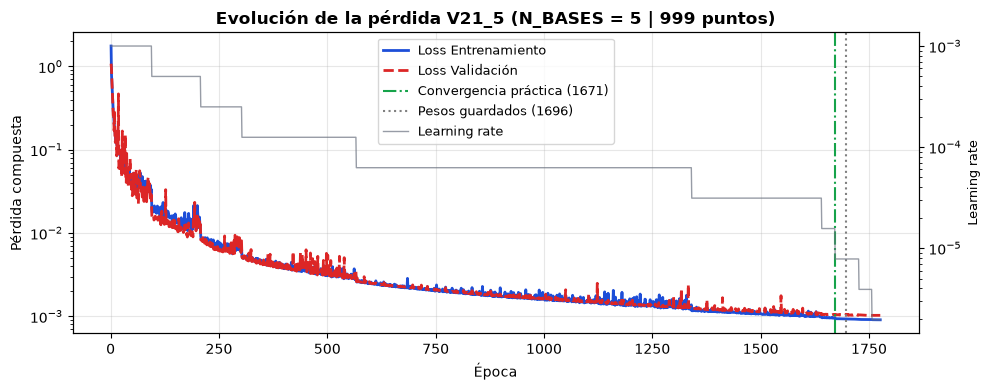

In [13]:
# ==============================================================================
# CÉLULA 8: ENTRENAMIENTO (O CARGA DEL MODELO GUARDADO) Y GUARDADO DE MODELO + ESCALADORES
# ==============================================================================
"""
ENTRENAR = True  → entrena, guarda modelo, escaladores e historial.
ENTRENAR = False → carga el modelo y el historial guardados (no reentrena). Sirve para volver a
                   correr la evaluación (Células 8b en adelante) con el modelo ya entrenado.
                   Requiere haber ejecutado antes las Células G a 7 (mismo dataset y escaladores).

Época de los pesos guardados: con restore_best_weights y min_delta, Keras restaura la última época
cuya val_loss mejoró en más de MIN_DELTA_VAL (no necesariamente el mínimo absoluto). Se reconstruye
desde el historial con la misma regla que EarlyStopping (verificada contra Keras).
"""
import os
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, TerminateOnNaN
from tensorflow.keras.models import load_model

ENTRENAR = True             # False = cargar el modelo guardado y saltear el entrenamiento

PATIENCE_EARLY_STOP = 80
PATIENCE_LR = 30            # V14: la meseta con lr ≈ 3e-5 (épocas 230–600) fue la etapa más productiva
MIN_DELTA_VAL = 1e-5        # mejora mínima de val_loss que cuenta (V12 seguía "mejorando" en el 5.º decimal)
EPOCHS = 2000               # tope; V14 cortó en 1000 todavía bajando (~15 % en las últimas 280 épocas)
BATCH_SIZE = 64
TOL_CONVERGENCIA = 0.01     # época de convergencia práctica: val_loss dentro del 1 % del mejor valor
ARCHIVO_HISTORIAL = f"historial_entrenamiento_{VERSION}.csv"


def epoca_restaurada(val_loss, min_delta, epochs_tope):
    """Época (1-based) cuyos pesos deja EarlyStopping(restore_best_weights=True, min_delta)."""
    if len(val_loss) >= epochs_tope:          # no hubo corte anticipado: quedan los pesos de la última época
        return len(val_loss)
    mejor, ep = np.inf, len(val_loss)
    for i, v in enumerate(val_loss):
        if v + min_delta < mejor:
            mejor, ep = v, i + 1
    return ep


if ENTRENAR:
    callbacks = [
        TerminateOnNaN(),
        EarlyStopping(monitor='val_loss', patience=PATIENCE_EARLY_STOP, min_delta=MIN_DELTA_VAL,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=PATIENCE_LR, min_delta=MIN_DELTA_VAL,
                          min_lr=1e-6, verbose=1),
        ModelCheckpoint(filepath=ARCHIVO_MODELO, monitor='val_loss', save_best_only=True, verbose=0),
    ]
    print(f"🚀 Entrenamiento {VERSION.upper()} para N = {N_BASES} bases ({N_PUNTOS} pts) | validación ≠ test...")
    t_start = time.time()
    history = model.fit(
        X_train, np.hstack([y_train, m_train]),                       # etiqueta + máscara de crosstalk (Célula 6)
        validation_data=(X_val, np.hstack([y_val, m_val])),     # el test NO participa en el entrenamiento ni en la selección
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1,
    )
    t_elapsed = time.time() - t_start
    hist = pd.DataFrame(history.history)
    hist.index = np.arange(1, len(hist) + 1)
    hist.index.name = "epoca"

    # --- Guardado coherente con la Célula 14 ---------------------------------------------
    model.save(ARCHIVO_MODELO)               # pesos restaurados por EarlyStopping
    with open(ARCHIVO_SCALERS, "wb") as f:
        pickle.dump({
            "scaler_x": sx,
            "scaler_y": sy,
            "offset_log": OFFSET_LOG,
            "c_lam": C_LAM, "escalas_bases": list(PARAMS_BASES["escalas"]), "nudos": list(PARAMS_BASES["knots"]),
            "metodo": "MCO",
            "n_bases": N_BASES,
            "x_mesh": X_MESH_999,
            "version": VERSION,
        }, f)
    hist.to_csv(ARCHIVO_HISTORIAL)
    print(f"\n✅ Entrenamiento completado en {t_elapsed/60:.2f} min ({len(hist)} épocas ejecutadas).")
    print(f"💾 Modelo → '{ARCHIVO_MODELO}' | Escaladores + OFFSET_LOG → '{ARCHIVO_SCALERS}' | "
          f"Historial → '{ARCHIVO_HISTORIAL}'")
else:
    for f in (ARCHIVO_MODELO, ARCHIVO_SCALERS, ARCHIVO_HISTORIAL):
        if not os.path.exists(f):
            raise FileNotFoundError(f"No se encontró '{f}': ejecutá la Célula 8 con ENTRENAR = True.")
    model = load_model(ARCHIVO_MODELO, compile=False)
    with open(ARCHIVO_SCALERS, "rb") as f:
        _meta = pickle.load(f)
    # Los escaladores de la Célula 5 deben coincidir con los guardados (mismo dataset).
    _ok = (np.allclose(_meta["scaler_x"].mean_, sx.mean_) and np.allclose(_meta["scaler_x"].scale_, sx.scale_)
           and np.allclose(_meta["scaler_y"].mean_, sy.mean_, atol=1e-6) and np.allclose(_meta["scaler_y"].scale_, sy.scale_, atol=1e-6))
    if not _ok:
        raise ValueError("Los escaladores de la Célula 5 no coinciden con los guardados: el dataset cambió. "
                         "Reentrená con ENTRENAR = True.")
    hist = pd.read_csv(ARCHIVO_HISTORIAL, index_col="epoca")
    print(f"📦 Modelo cargado desde '{ARCHIVO_MODELO}' (sin reentrenar) | escaladores verificados | "
          f"historial: {len(hist)} épocas.")

val_hist = hist['val_loss'].to_numpy()
argmin_ep = int(np.argmin(val_hist)) + 1
best_ep = epoca_restaurada(val_hist, MIN_DELTA_VAL, EPOCHS)
ep_conv = int(np.argmax(val_hist <= val_hist.min() * (1.0 + TOL_CONVERGENCIA))) + 1
lr_col = next((c for c in ("learning_rate", "lr") if c in hist.columns), None)

print(f"   • Época de los pesos guardados: {best_ep} | val_loss: {val_hist[best_ep - 1]:.6f} | "
      f"loss de entrenamiento: {hist['loss'].iloc[best_ep - 1]:.6f}")
print(f"   • Mínimo absoluto de val_loss: {val_hist.min():.6f} en la época {argmin_ep} "
      f"(diferencia {val_hist[best_ep - 1] - val_hist.min():.2e}; min_delta = {MIN_DELTA_VAL:g})")
print(f"   • Convergencia práctica (val_loss a ≤ {TOL_CONVERGENCIA:.0%} del mejor): época {ep_conv}")
_ventana = min(200, len(val_hist) // 4)
if len(val_hist) >= EPOCHS and _ventana > 10:
    _baja = 1.0 - val_hist[-1] / val_hist[-_ventana]
    print(f"   ⚠️ Se alcanzó el tope de {EPOCHS} épocas sin corte anticipado: val_loss bajó {_baja:.1%} en las "
          f"últimas {_ventana} épocas ({'todavía mejorando' if _baja > 0.02 else 'prácticamente convergido'}).")
print(f"   • MAE de validación en la época guardada (espacio estandarizado): {hist['val_mae'].iloc[best_ep - 1]:.6f}")
if lr_col:
    print(f"   • Learning rate final: {hist[lr_col].iloc[-1]:.2e}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hist.index, hist['loss'], label='Loss Entrenamiento', color='#1d4ed8', linewidth=2)
ax.plot(hist.index, val_hist, label='Loss Validación', color='#dc2626', linewidth=2, linestyle='--')
ax.axvline(ep_conv, color='#16a34a', linestyle='-.', label=f'Convergencia práctica ({ep_conv})')
ax.axvline(best_ep, color='gray', linestyle=':', label=f'Pesos guardados ({best_ep})')
ax.set_title(f'Evolución de la pérdida {VERSION.upper()} (N_BASES = {N_BASES} | {N_PUNTOS} puntos)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Época', fontsize=10)
ax.set_ylabel('Pérdida compuesta', fontsize=10)
ax.set_yscale('log')
ax.grid(True, alpha=0.3)
if lr_col:
    ax_lr = ax.twinx()
    ax_lr.plot(hist.index, hist[lr_col], color='#6b7280', linewidth=1, alpha=0.7, label='Learning rate')
    ax_lr.set_yscale('log')
    ax_lr.set_ylabel('Learning rate', fontsize=9)
    l1, n1 = ax.get_legend_handles_labels()
    l2, n2 = ax_lr.get_legend_handles_labels()
    ax.legend(l1 + l2, n1 + n2, fontsize=9)
else:
    ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f"evolucion_perdida_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Célula 8b — Evaluación base en test (la reutilizan 9, 12 y 13)

In [14]:
# ==============================================================================
# CÉLULA 8b: EVALUACIÓN BASE SOBRE EL CONJUNTO DE TEST (la usan las Células 9, 12 y 13)
# ==============================================================================
"""
Un único lugar para la inferencia sobre test:
  • coef_crudo : salida de la red desestandarizada (sin proyectar).
  • coef_rn    : = coef_crudo (V20, MCO sin cotas: no se proyecta; se informa si algún c < 0).
  • coef_lsq   : óptimo MCO de la curva de ENTRADA (techo alcanzable con las bases).
  • coef_opt   : etiqueta (= coef_lsq: la etiqueta es el MCO de la curva de entrada).
  • coef_pul   : red + pulido. En MCO el pulido es c = A⁺y (ecuaciones normales): siempre el óptimo exacto.
  • b_limpio   : curva SIN ruido (la verdadera); permite medir el error contra la curva verdadera.
"""
import time
import numpy as np

N_CRONO_LSQ = 300   # curvas para cronometrar el MCO


def evaluar_test():
    y_pred_norm = model.predict(X_test, batch_size=1024, verbose=0)
    coef_crudo = sy.inverse_transform(y_pred_norm)
    coef_rn = np.clip(coef_crudo, COTA_INF, COTA_SUP)    # V20: sin cotas (no recorta)
    coef_opt = sy.inverse_transform(y_test)
    b_in = Y_raw[idx_test]
    coef_lsq = coef_opt.copy()
    return {
        "coef_crudo": coef_crudo,
        "coef_rn": coef_rn,                              # (n_test, N_BASES) predicho y proyectado
        "coef_opt": coef_opt,                            # (n_test, N_BASES) etiqueta
        "coef_lsq": coef_lsq,                            # (n_test, N_BASES) óptimo de la entrada
        "b_rn": coef_rn @ A_base.T,                      # curva reconstruida por la red
        "b_opt": coef_opt @ A_base.T,                    # curva reconstruida con la etiqueta
        "b_lsq": coef_lsq @ A_base.T,                    # mejor reconstrucción posible de la entrada
        "b_in": b_in,                                    # curva REAL de entrada a la red
        "b_limpio": Y_limpio[idx_test],                  # curva verdadera, sin ruido
        "fam": fam_test,
        "idx": idx_test,
    }


EVAL = evaluar_test()
n_test = EVAL["coef_rn"].shape[0]
_pul = [pulir(A_base, y, c) for y, c in zip(EVAL["b_in"], EVAL["coef_crudo"])]
EVAL["coef_pul"] = np.array([p[0] for p in _pul])
EVAL["pul_exacto"] = np.array([p[1] for p in _pul])
EVAL["b_pul"] = EVAL["coef_pul"] @ A_base.T
neg = EVAL["coef_crudo"] < COEF_MIN
neg_opt = EVAL["coef_opt"] < COEF_MIN
print(f"✅ Evaluación base lista: {n_test} curvas de test, {EVAL['coef_rn'].shape[1]} coeficientes.")
print(f"   • Coeficientes negativos (capa no fabricable): red {neg.mean():.2%} de los coeficientes "
      f"({neg.any(axis=1).mean():.2%} de las curvas, mínimo {EVAL['coef_crudo'].min():.4f}) | "
      f"MCO {neg_opt.any(axis=1).mean():.2%} de las curvas (mínimo {EVAL['coef_opt'].min():.4f})")

print(f"   • Pulido (MCO: ecuaciones normales): resultado = óptimo exacto en "
      f"{EVAL['pul_exacto'].mean():.2%} de las curvas | |c_pul − c_opt| máx. = "
      f"{np.abs(EVAL['coef_pul'] - EVAL['coef_opt']).max():.1e}")
for f, nombre in FAMILIAS.items():
    m = EVAL["fam"] == f
    print(f"       {nombre:<20}: pulido exacto {EVAL['pul_exacto'][m].mean():7.2%}")

# --- Cronometraje justo: red en lote vs. MCO curva a curva ---------------------------------------
Y_crono = Y_raw[idx_test]
t0 = time.perf_counter()
_ = np.clip(sy.inverse_transform(model.predict(sx.transform(safe_log_transform(Y_crono)),
                                               batch_size=1024, verbose=0)), COTA_INF, COTA_SUP)
t_rn = (time.perf_counter() - t0) / len(Y_crono)
t0 = time.perf_counter()
for y in Y_crono[:N_CRONO_LSQ]:
    optimo_mc(A_base, y)
t_lsq = (time.perf_counter() - t0) / N_CRONO_LSQ
TIEMPOS = {"rn_ms_por_curva": t_rn * 1e3, "lsq_ms_por_curva": t_lsq * 1e3}
print(f"   • Tiempo por curva (incluye log + escalado): red en lote {t_rn*1e3:.4f} ms | "
      f"MCO (lstsq) {t_lsq*1e3:.3f} ms → factor {t_lsq / t_rn:.1f}×")
print("     (referencia de velocidad, no aporte central: un solver exacto vectorizado para tan pocas variables sería competitivo)")

✅ Evaluación base lista: 6000 curvas de test, 5 coeficientes.
   • Coeficientes negativos (capa no fabricable): red 10.94% de los coeficientes (30.10% de las curvas, mínimo -0.4314) | MCO 32.40% de las curvas (mínimo -0.4914)
   • Pulido (MCO: ecuaciones normales): resultado = óptimo exacto en 100.00% de las curvas | |c_pul − c_opt| máx. = 1.8e-15
       pura                : pulido exacto 100.00%
       combinada           : pulido exacto 100.00%
       constitutiva        : pulido exacto 100.00%
       constitutiva_amplia : pulido exacto 100.00%
       exponencial         : pulido exacto 100.00%
       constitutiva_uniforme: pulido exacto 100.00%
       pacientes           : pulido exacto 100.00%
   • Tiempo por curva (incluye log + escalado): red en lote 0.0557 ms | MCO (lstsq) 0.055 ms → factor 1.0×
     (referencia de velocidad, no aporte central: un solver exacto vectorizado para tan pocas variables sería competitivo)


## Célula 9 — Reconstrucción física en test (una muestra por familia)

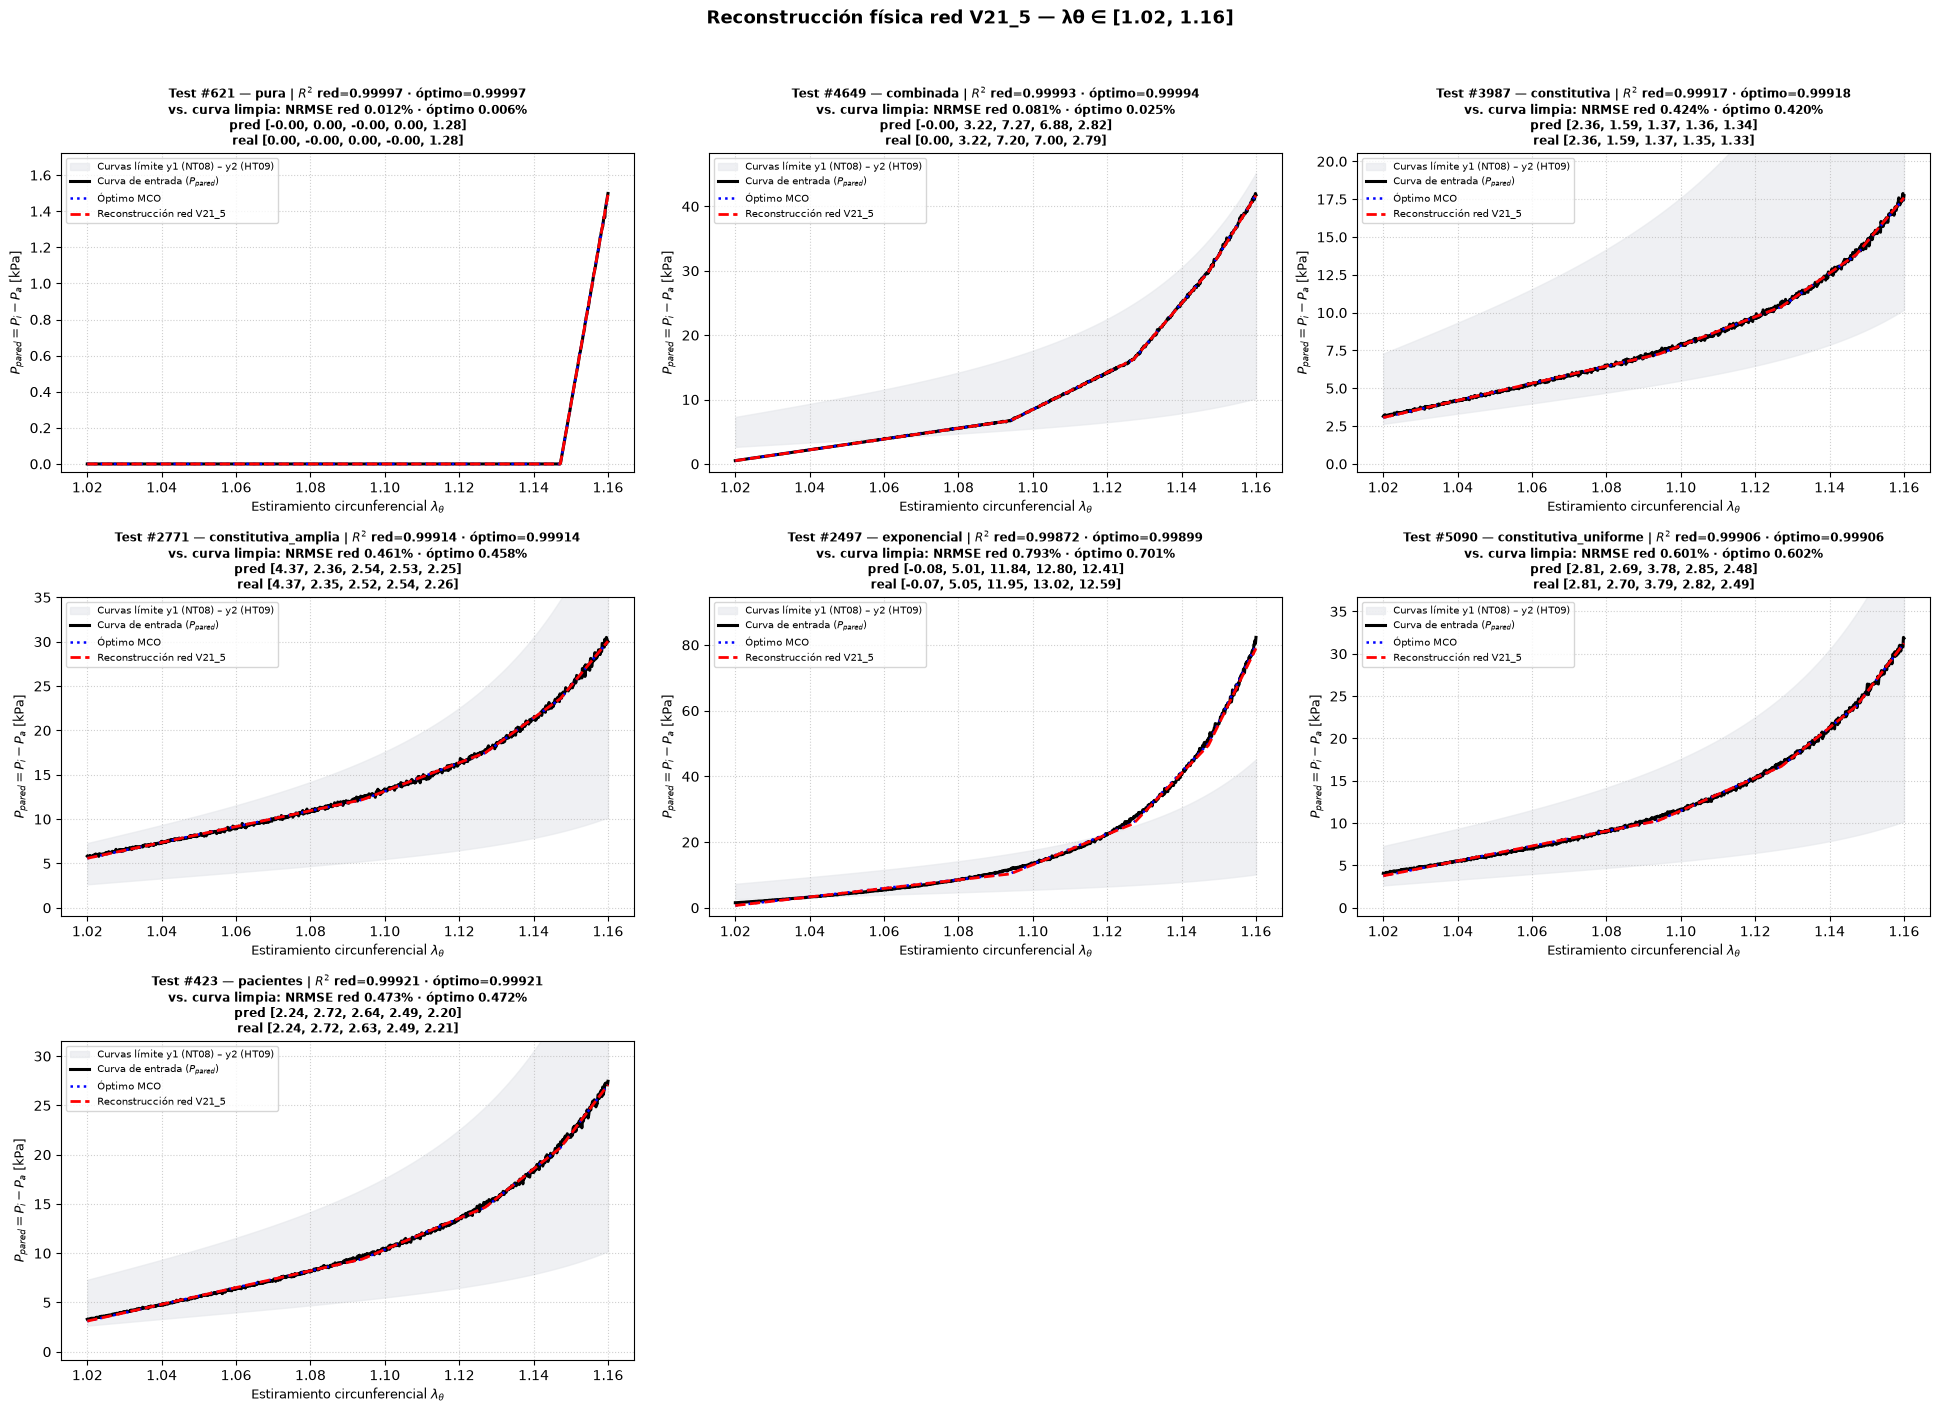

📏 NRMSE medio contra la curva LIMPIA (verdadera) vs. contra la entrada con ruido, por familia:
   • pura                : vs. limpia — red 0.204% | óptimo 0.028%   (vs. entrada con ruido — red 0.435%)
   • combinada           : vs. limpia — red 0.283% | óptimo 0.023%   (vs. entrada con ruido — red 0.411%)
   • constitutiva        : vs. limpia — red 0.450% | óptimo 0.440%   (vs. entrada con ruido — red 0.749%)
   • constitutiva_amplia : vs. limpia — red 0.456% | óptimo 0.436%   (vs. entrada con ruido — red 0.761%)
   • exponencial         : vs. limpia — red 0.536% | óptimo 0.501%   (vs. entrada con ruido — red 0.767%)
   • constitutiva_uniforme: vs. limpia — red 0.466% | óptimo 0.443%   (vs. entrada con ruido — red 0.789%)
   • pacientes           : vs. limpia — red 0.474% | óptimo 0.465%   (vs. entrada con ruido — red 0.751%)

=== INFERENCIA EN LAS CURVAS MEDIAS RECONSTRUIDAS (grupos de las Figs. 5a y 7a) ===
✅ Mean Young : láminas red = [3.253 1.839 1.416 1.409 1.282] | MCO = [3.258 1

In [15]:
# ==============================================================================
# CÉLULA 9: RECONSTRUCCIÓN FÍSICA EN TEST (UNA MUESTRA ALEATORIA POR FAMILIA)
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt

x_mesh = X_MESH_999
rng_plot = np.random.default_rng(SEED)
idx_muestras = [int(rng_plot.choice(np.where(EVAL["fam"] == f)[0])) for f in sorted(FAMILIAS)]

n_cols = 3
n_rows = int(np.ceil(len(idx_muestras) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.5 * n_cols, 4.6 * n_rows), squeeze=False)
for ax in axes.flatten()[len(idx_muestras):]:
    ax.axis("off")
for ax, s in zip(axes.flatten(), idx_muestras):
    b_in, b_rn, b_lsq, b_0 = EVAL["b_in"][s], EVAL["b_rn"][s], EVAL["b_lsq"][s], EVAL["b_limpio"][s]
    c_pred, c_true = EVAL["coef_rn"][s], EVAL["coef_opt"][s]
    m_rn, m_lsq = metricas_curva(b_in, b_rn), metricas_curva(b_in, b_lsq)
    m0_rn, m0_lsq = metricas_curva(b_0, b_rn), metricas_curva(b_0, b_lsq)

    ax.fill_between(x_mesh, BANDA_INF, BANDA_SUP, color="#e5e7eb", alpha=0.6, label=ETQ_BANDA)
    ax.plot(x_mesh, b_in, 'k-', lw=2.2, label='Curva de entrada ($P_{pared}$)')
    ax.plot(x_mesh, b_lsq, 'b:', lw=1.8, label='Óptimo MCO')
    ax.plot(x_mesh, b_rn, 'r--', lw=2.0, label=f'Reconstrucción red {VERSION.upper()}')
    ax.set_ylim(bottom=-0.03 * max(b_in.max(), 1.0), top=1.15 * max(b_in.max(), 1.0))

    coef_str = ", ".join(f"{c_pred[i]:.2f}" for i in range(N_BASES))
    true_str = ", ".join(f"{c_true[i]:.2f}" for i in range(N_BASES))
    ax.set_title(f"Test #{s} — {FAMILIAS[int(EVAL['fam'][s])]} | $R^2$ red={m_rn['R2']:.5f} · óptimo={m_lsq['R2']:.5f}\n"
                 f"vs. curva limpia: NRMSE red {m0_rn['NRMSE']:.3f}% · óptimo {m0_lsq['NRMSE']:.3f}%\n"
                 f"pred [{coef_str}]\nreal [{true_str}]", fontsize=8.5, fontweight='bold')
    ax.set_xlabel(r"Estiramiento circunferencial $\lambda_\theta$", fontsize=9)
    ax.set_ylabel(ETQ_Y, fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left', fontsize=7)

plt.suptitle(f"Reconstrucción física red {VERSION.upper()} — λθ ∈ [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}]",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f"reconstruccion_curvas_test_{VERSION}.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# --- Error contra la curva verdadera (sin ruido): el R² contra la entrada ruidosa tiene un techo ---------
print("📏 NRMSE medio contra la curva LIMPIA (verdadera) vs. contra la entrada con ruido, por familia:")
M0_rn = metricas_lote(EVAL["b_limpio"], EVAL["b_rn"]); M0_lsq = metricas_lote(EVAL["b_limpio"], EVAL["b_lsq"])
Mi_rn = metricas_lote(EVAL["b_in"], EVAL["b_rn"])
for f, nombre in FAMILIAS.items():
    m = EVAL["fam"] == f
    print(f"   • {nombre:<20}: vs. limpia — red {np.nanmean(M0_rn['NRMSE'][m]):.3f}% | óptimo {np.nanmean(M0_lsq['NRMSE'][m]):.3f}%"
          f"   (vs. entrada con ruido — red {np.nanmean(Mi_rn['NRMSE'][m]):.3f}%)")

# --- Inferencia sobre las 4 curvas medias reconstruidas (la comparación completa está en la Célula 10) ---
print("\n=== INFERENCIA EN LAS CURVAS MEDIAS RECONSTRUIDAS (grupos de las Figs. 5a y 7a) ===")
for nombre, y_m in MEDIAS_RECONSTRUIDAS.items():
    Xn = sx.transform(safe_log_transform(y_m).reshape(1, -1))
    c_crudo = sy.inverse_transform(model.predict(Xn, verbose=0))[0].astype(np.float64)
    c_opt_m = optimo_mc(A_base, y_m)
    print(f"✅ {nombre:<11}: láminas red = {np.round(c_crudo, 3)} | MCO = {np.round(c_opt_m, 3)} | "
          f"total MCO = {c_opt_m.sum():.2f}")

## Célula 10 — Validación con curvas reales: 41 sujetos y 4 curvas medias (red vs. óptimo MCO)

In [16]:
# ==============================================================================
# CÉLULA 10: VALIDACIÓN CON CURVAS REALES — 41 SUJETOS Y 4 CURVAS MEDIAS (RED vs. ÓPTIMO MCO)
# ==============================================================================
"""
Curvas reales = P_pared(λθ) reconstruidas con los parámetros publicados de cada sujeto (Célula M), sin
ruido. Los sujetos marcados como test no participaron del generador ni del diseño de las bases:
son la validación independiente. Las 4 curvas medias (grupos de las Figs. 5a y 7a) promedian
sujetos de entrenamiento y de test.

Para cada curva:
  • Óptimo: mínimos cuadrados ORDINARIOS (MCO, c = A⁺y, sin cotas), la misma referencia de las etiquetas.
  • Certificado de optimalidad con g = Aᵀ(A c* − y): sin cotas, KKT se reduce a las ecuaciones normales g ≈ 0
    (estacionariedad relativa). Se informa además si el injerto es fabricable (c ≥ 0).
  • Control de clase (es_curva_J) antes de la red.
"""
import time
import numpy as np
import pandas as pd

N_REP_TIEMPO = 50
TOL_ACTIVA = 1e-6


def _mediana_tiempo(fn, n=N_REP_TIEMPO):
    ts = []
    for _ in range(n):
        t0 = time.perf_counter()
        fn()
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts))


def verificacion_kkt(A, y, c, active_mask):
    g = A.T @ (A @ c - y)
    inf = c <= COTA_INF + TOL_ACTIVA
    sup = c >= COTA_SUP - TOL_ACTIVA
    libre = ~(inf | sup)
    mu, nu = np.where(inf, g, 0.0), np.where(sup, -g, 0.0)
    escala = max(float(np.linalg.norm(A.T @ y)), 1e-12)
    return {"mu_inf": mu, "nu_sup": nu, "activas_inf": np.where(inf)[0] + 1, "activas_sup": np.where(sup)[0] + 1,
            "estacionariedad_rel": (float(np.max(np.abs(g[libre]))) if libre.any() else 0.0) / escala,
            "signos_ok": bool(np.all(mu >= -1e-8 * escala) and np.all(nu >= -1e-8 * escala)),
            "coincide_active_mask": bool(np.array_equal(inf, active_mask == -1) and np.array_equal(sup, active_mask == 1))}


def evaluar_curva_real(y, nombre):
    c_star = optimo_mc(A_base, y)
    Xn = sx.transform(safe_log_transform(y).reshape(1, -1))
    c_crudo = sy.inverse_transform(model(Xn, training=False).numpy()).flatten().astype(np.float64)
    c_rn = np.clip(c_crudo, COTA_INF, COTA_SUP)
    c_pul, pul_exacto = pulir(A_base, y, c_crudo)
    b_rn, b_opt = A_base @ c_rn, A_base @ c_star
    m_rn, m_opt = metricas_curva(y, b_rn), metricas_curva(y, b_opt)
    return {"nombre": nombre, "y": y, "coef_pred": c_rn, "coef_crudo": c_crudo, "coef_opt": c_star,
            "coef_pul": c_pul, "pul_exacto": pul_exacto,
            "b_rn": b_rn, "b_opt": b_opt, "m_rn": m_rn, "m_opt": m_opt, "en_clase": es_curva_J(y),
            "fabricable": bool(np.all(c_star >= COEF_MIN - 1e-9)),
            "kkt": verificacion_kkt(A_base, y, c_star, np.zeros(len(c_star), dtype=int))}


# --- 1. Los 41 sujetos -------------------------------------------------------------------------
RES_SUJETOS = [evaluar_curva_real(y, r["id"]) for (_, r), y in zip(POB.iterrows(), POB_Y)]
filas = []
for (_, r), e in zip(POB.iterrows(), RES_SUJETOS):
    filas.append(dict(id=r["id"], grupo=r["grupo"], test=bool(r["test"]), en_clase=e["en_clase"],
                      R2_red=e["m_rn"]["R2"], R2_opt=e["m_opt"]["R2"],
                      NRMSE_red=e["m_rn"]["NRMSE"], NRMSE_opt=e["m_opt"]["NRMSE"],
                      MaxAE_rel_red=e["m_rn"]["MaxAE_rel"], MaxAE_rel_opt=e["m_opt"]["MaxAE_rel"],
                      dc_max=float(np.max(np.abs(e["coef_pred"] - e["coef_opt"]))),
                      pul_exacto=e["pul_exacto"], dc_pul=float(np.max(np.abs(e["coef_pul"] - e["coef_opt"]))),
                      kkt_estac=e["kkt"]["estacionariedad_rel"], kkt_signos=e["kkt"]["signos_ok"],
                      kkt_mask=e["kkt"]["coincide_active_mask"], fabricable=e["fabricable"],
                      c_min_opt=float(e["coef_opt"].min()), c_min_red=float(e["coef_crudo"].min()),
                      cumple_red=bool(e["m_rn"]["MaxAE_rel"] <= ERROR_MAX_PCT), cumple_opt=bool(e["m_opt"]["MaxAE_rel"] <= ERROR_MAX_PCT),
                      **{f"c{j+1}_opt": v for j, v in enumerate(e["coef_opt"])}))
DF_SUJETOS = pd.DataFrame(filas)
DF_SUJETOS["exceso_NRMSE_pct"] = (DF_SUJETOS["NRMSE_red"] / DF_SUJETOS["NRMSE_opt"] - 1.0) * 100
DF_SUJETOS.to_csv(f"validacion_sujetos_reales_{VERSION}.csv", index=False)

print("=" * 112)
print(f"🫀 VALIDACIÓN CON LOS {len(POB)} SUJETOS REALES (P_pared reconstruida, sin ruido)")
print("=" * 112)
print(f"{'Subconjunto':<20} {'n':>3} | {'R² ópt.':>8} {'R² red':>8} {'mín. red':>9} | {'NRMSE ópt.':>10} {'NRMSE red':>10} "
      f"{'Exceso':>8} | {'err. pto. red máx.':>18} | {'cumplen (red/ópt.)':>18} | {'máx |Δc|':>8}")
print("-" * 112)
for etiqueta, m in [("Test (reservados)", DF_SUJETOS["test"]), ("Entrenamiento", ~DF_SUJETOS["test"]),
                    ("NT", DF_SUJETOS["grupo"] == "NT"), ("HT", DF_SUJETOS["grupo"] == "HT"),
                    ("Todos", DF_SUJETOS["grupo"].notna())]:
    d = DF_SUJETOS[m.to_numpy()]
    exc = (d["NRMSE_red"].mean() / d["NRMSE_opt"].mean() - 1) * 100
    print(f"{etiqueta:<20} {len(d):>3} | {d['R2_opt'].mean():8.5f} {d['R2_red'].mean():8.5f} {d['R2_red'].min():9.5f} | "
          f"{d['NRMSE_opt'].mean():9.3f}% {d['NRMSE_red'].mean():9.3f}% {exc:+7.1f}% | {d['MaxAE_rel_red'].max():17.2f}% | "
          f"{int(d['cumple_red'].sum()):>7d} / {int(d['cumple_opt'].sum()):<3d} de {len(d):<3} | {d['dc_max'].max():8.4f}")
print("-" * 112)
print(f"Ecuaciones normales en los {len(DF_SUJETOS)} óptimos MCO: estacionariedad relativa máx. "
      f"{DF_SUJETOS['kkt_estac'].max():.1e} | injerto fabricable (c ≥ 0): {int(DF_SUJETOS['fabricable'].sum())} de "
      f"{len(DF_SUJETOS)} (MCO) | red con algún c < 0: {int((DF_SUJETOS['c_min_red'] < COEF_MIN).sum())}")
print(f"Criterio error punto a punto ≤ {ERROR_MAX_PCT:g}%: red {int(DF_SUJETOS['cumple_red'].sum())} de {len(DF_SUJETOS)} | "
      f"MCO {int(DF_SUJETOS['cumple_opt'].sum())} de {len(DF_SUJETOS)}")
print(f"Control de clase (es_curva_J): {DF_SUJETOS['en_clase'].mean():.0%} de los sujetos reales aceptados.")
print(f"Red + pulido (MCO): óptimo exacto en {DF_SUJETOS['pul_exacto'].mean():.0%} de los sujetos | "
      f"máx |c_pul − c_opt| = {DF_SUJETOS['dc_pul'].max():.1e} (≈ 0 ⇒ red + pulido = óptimo exacto)")
peor = DF_SUJETOS.loc[DF_SUJETOS["R2_red"].idxmin()]
print(f"Peor sujeto: {peor['id']} ({'test' if peor['test'] else 'entrenamiento'}) — R² red {peor['R2_red']:.5f} "
      f"vs. óptimo {peor['R2_opt']:.5f}")
if "NT08" in set(DF_SUJETOS["id"]):
    _n8 = DF_SUJETOS.set_index("id").loc["NT08"]
    print(f"NT08 (arteria más blanda de la población): R² red {_n8['R2_red']:.5f} vs. óptimo {_n8['R2_opt']:.5f} "
          f"| exceso NRMSE {_n8['exceso_NRMSE_pct']:+.1f}%")
_d_t = DF_SUJETOS[DF_SUJETOS["test"]]
print(f"Test: exceso NRMSE mediano por sujeto {_d_t['exceso_NRMSE_pct'].median():+.1f}% | "
      f"máximo {_d_t['exceso_NRMSE_pct'].max():+.1f}% ({_d_t.loc[_d_t['exceso_NRMSE_pct'].idxmax(), 'id']})")

# --- 2. Las 4 curvas medias reconstruidas ------------------------------------------------------
RES_MEDIAS = {k: evaluar_curva_real(y, k) for k, y in MEDIAS_RECONSTRUIDAS.items()}
y_ej = MEDIAS_RECONSTRUIDAS["Mean HT"]
t_lsq = _mediana_tiempo(lambda: optimo_mc(A_base, y_ej))
t_rn = _mediana_tiempo(lambda: model(sx.transform(safe_log_transform(y_ej).reshape(1, -1)), training=False))


def reportar_media(r):
    k = r["kkt"]
    print("\n" + "=" * 92)
    print(f"{r['nombre']} (reconstruida; n = {int(GRUPOS_MEDIAS[r['nombre']].sum())} sujetos)")
    print("=" * 92)
    print(f"Láminas óptimas MCO : {np.round(r['coef_opt'], 4)}   (total {r['coef_opt'].sum():.2f})")
    print(f"Láminas red         : {np.round(r['coef_pred'], 4)}")
    print(f"Ecuaciones normales: estacionariedad {k['estacionariedad_rel']:.1e} | fabricable (c ≥ 0): {r['fabricable']}")
    print(f"{'':<12} {'R²':>10} {'RMSE [kPa]':>11} {'MaxAE [kPa]':>12} {'NRMSE':>9} {'MaxAE_rel':>10}")
    for etiqueta, m in [("Red", r["m_rn"]), ("Óptimo MCO", r["m_opt"])]:
        print(f"{etiqueta:<12} {m['R2']:10.6f} {m['RMSE']:11.4f} {m['MaxAE']:12.4f} {m['NRMSE']:8.4f}% {m['MaxAE_rel']:9.3f}%")
    print(f"Exceso de RMSE de la red sobre el óptimo: {(r['m_rn']['RMSE'] / r['m_opt']['RMSE'] - 1.0) * 100:+.2f}%")


for r in RES_MEDIAS.values():
    reportar_media(r)
print(f"\nTiempo por curva (mediana de {N_REP_TIEMPO}): MCO (lstsq) {t_lsq*1e3:.3f} ms | "
      f"red (1 curva, incluye overhead de Keras) {t_rn*1e3:.3f} ms")

🫀 VALIDACIÓN CON LOS 41 SUJETOS REALES (P_pared reconstruida, sin ruido)
Subconjunto            n |  R² ópt.   R² red  mín. red | NRMSE ópt.  NRMSE red   Exceso | err. pto. red máx. | cumplen (red/ópt.) | máx |Δc|
----------------------------------------------------------------------------------------------------------------
Test (reservados)     10 |  0.99960  0.99956   0.99922 |     0.495%     0.519%    +4.8% |              1.84% |      10 / 10  de 10  |   0.0515
Entrenamiento         31 |  0.99965  0.99964   0.99938 |     0.458%     0.465%    +1.5% |              1.63% |      31 / 31  de 31  |   0.0597
NT                    16 |  0.99968  0.99965   0.99922 |     0.438%     0.453%    +3.6% |              1.84% |      16 / 16  de 16  |   0.0515
HT                    25 |  0.99962  0.99961   0.99938 |     0.486%     0.494%    +1.6% |              1.63% |      25 / 25  de 25  |   0.0597
Todos                 41 |  0.99964  0.99962   0.99922 |     0.467%     0.478%    +2.4% |            

## Célula 11 — Figuras de validación: curvas medias y sujetos reservados

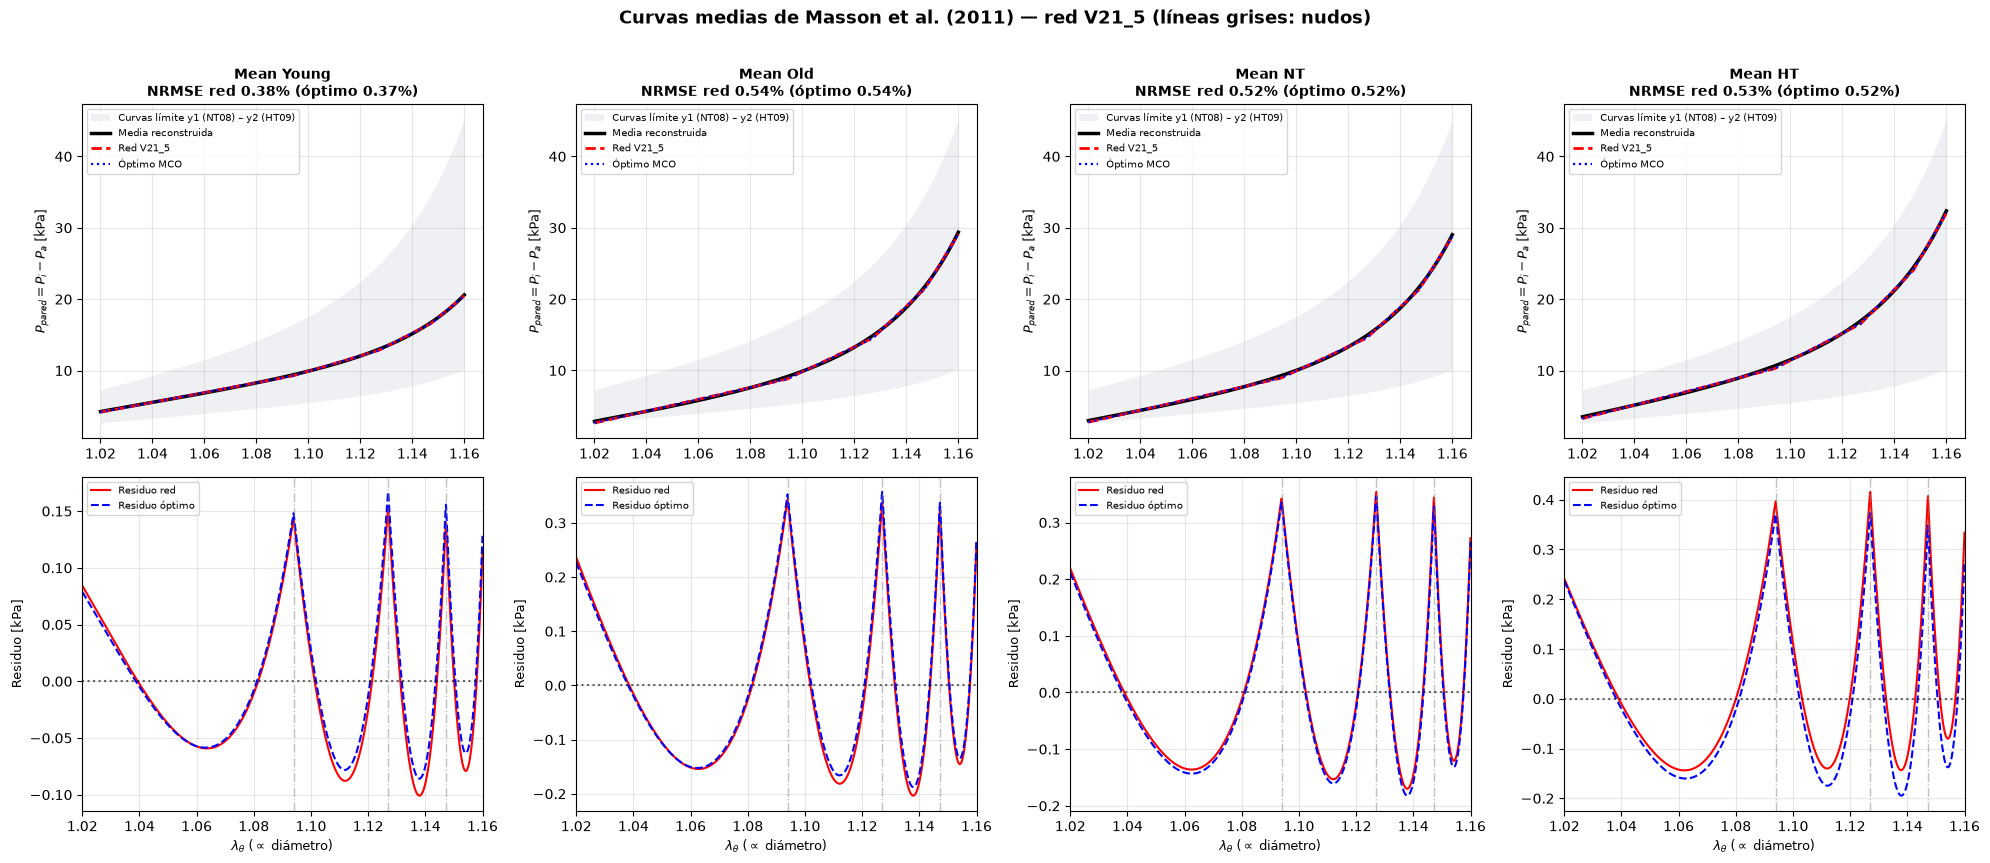

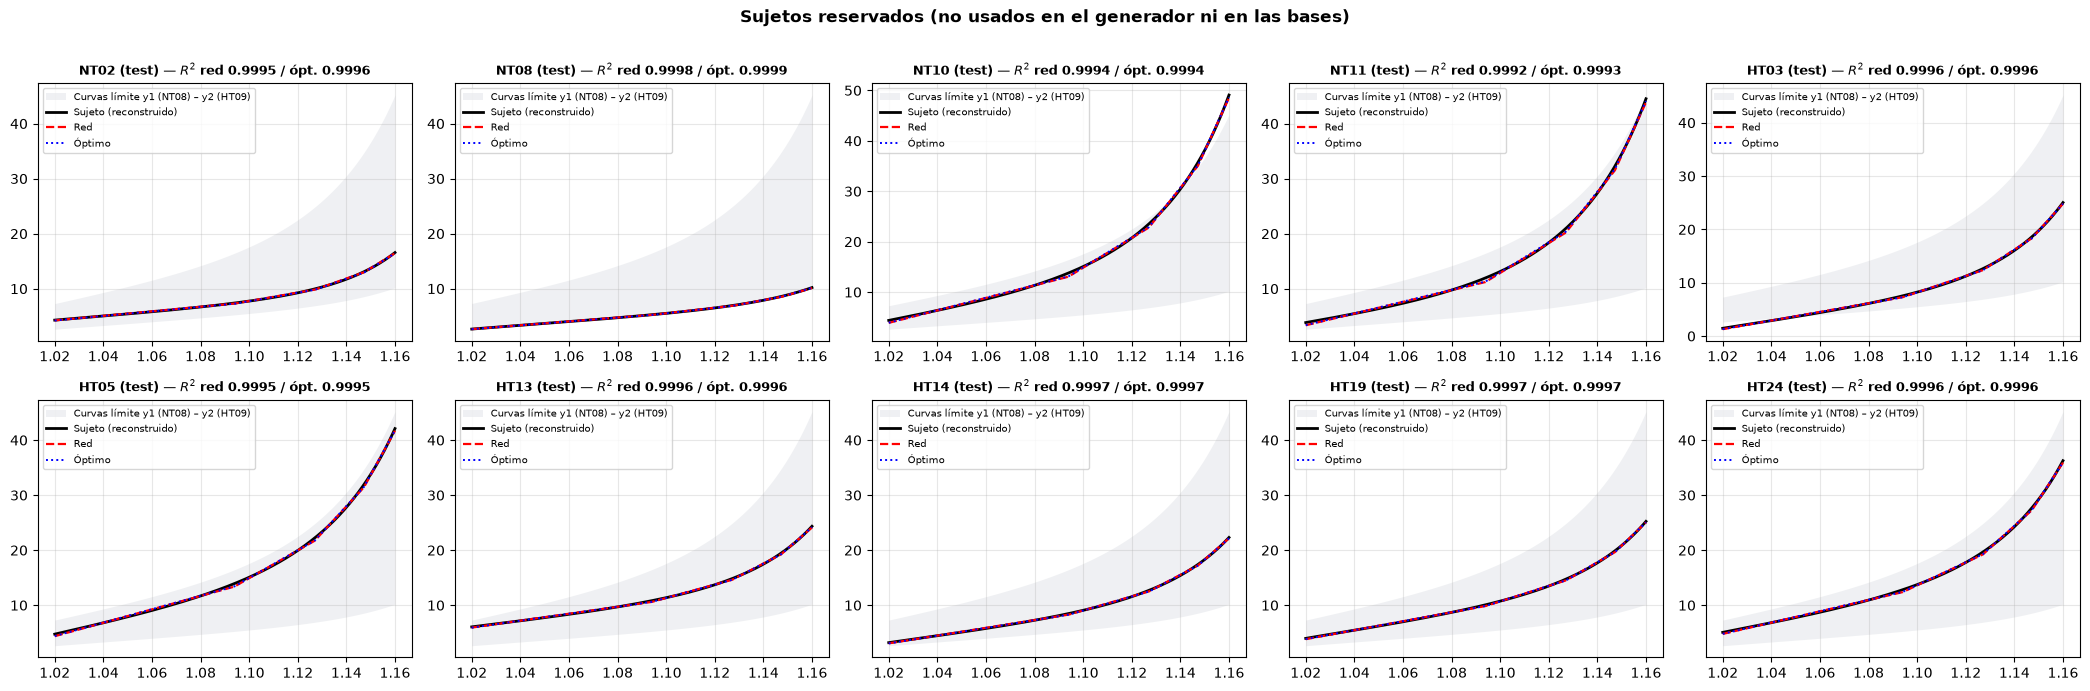

In [17]:
# ==============================================================================
# CÉLULA 11: FIGURAS DE VALIDACIÓN — CURVAS MEDIAS Y SUJETOS RESERVADOS PARA TEST
# ==============================================================================
"""
Figura 1: las 4 curvas medias de P_pared (entrada reconstruida, red y óptimo) con sus residuos; las líneas grises marcan los nudos de las rampas.
Figura 2: los sujetos reservados para test, uno por panel.
"""
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

nudos = PARAMS_BASES["knots"]
dig = None   # Desde V16: las medias digitalizadas del paper son de σθθ, no de P_pared (no se superponen)

fig, axes = plt.subplots(2, 4, figsize=(20, 8.5))
for col, (nombre, r) in enumerate(RES_MEDIAS.items()):
    ax_a, ax_r = axes[0, col], axes[1, col]
    ax_a.fill_between(X_MESH_999, BANDA_INF, BANDA_SUP, color="#e5e7eb", alpha=0.6, lw=0, label=ETQ_BANDA)
    ax_a.plot(X_MESH_999, r["y"], "k-", lw=2.5, label="Media reconstruida")
    if dig is not None and (dig["curva"] == nombre).any():
        d = dig[dig["curva"] == nombre]
        ax_a.plot(d["lambda_theta"], d["sigma_theta_kPa"], color="#f59e0b", lw=5, alpha=0.45,
                  label="Media digitalizada (paper)")
    ax_a.plot(X_MESH_999, r["b_rn"], "r--", lw=2, label=f"Red {VERSION.upper()}")
    ax_a.plot(X_MESH_999, r["b_opt"], "b:", lw=1.6, label="Óptimo MCO")
    ax_a.set_title(f"{nombre}\nNRMSE red {r['m_rn']['NRMSE']:.2f}% (óptimo {r['m_opt']['NRMSE']:.2f}%)",
                   fontsize=10, fontweight="bold")
    ax_a.set_ylabel(ETQ_Y, fontsize=9)
    ax_a.grid(True, alpha=0.3)
    ax_a.legend(fontsize=7, loc="upper left")

    ax_r.plot(X_MESH_999, r["y"] - r["b_rn"], "r-", lw=1.5, label="Residuo red")
    ax_r.plot(X_MESH_999, r["y"] - r["b_opt"], "b--", lw=1.5, label="Residuo óptimo")
    for k in nudos:
        if X_MIN_DOMINIO <= k <= X_MAX_DOMINIO:          # telas enganchadas antes del dominio: no se dibujan
            ax_r.axvline(k, color="gray", linestyle="-.", alpha=0.5, lw=1)
    ax_r.set_xlim(X_MIN_DOMINIO, X_MAX_DOMINIO)
    ax_r.axhline(0, color="black", linestyle=":", alpha=0.6)
    ax_r.set_xlabel(ETQ_X, fontsize=9)
    ax_r.set_ylabel("Residuo [kPa]", fontsize=9)
    ax_r.grid(True, alpha=0.3)
    ax_r.legend(fontsize=7)
plt.suptitle(f"Curvas medias de Masson et al. (2011) — red {VERSION.upper()} (líneas grises: nudos)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"validacion_curvas_medias_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# --- Sujetos reservados para test ---------------------------------------------------------------
idx_t = np.where(MASK_POB_TEST)[0]
n_cols = 5
n_rows = int(np.ceil(len(idx_t) / n_cols))
fig2, axes2 = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.4 * n_rows), squeeze=False)
for ax, i in zip(axes2.flatten(), idx_t):
    r = RES_SUJETOS[i]
    ax.fill_between(X_MESH_999, BANDA_INF, BANDA_SUP, color="#e5e7eb", alpha=0.6, lw=0, label=ETQ_BANDA)
    ax.plot(X_MESH_999, r["y"], "k-", lw=2, label="Sujeto (reconstruido)")
    ax.plot(X_MESH_999, r["b_rn"], "r--", lw=1.6, label="Red")
    ax.plot(X_MESH_999, r["b_opt"], "b:", lw=1.4, label="Óptimo")
    ax.set_title(f"{r['nombre']} (test) — $R^2$ red {r['m_rn']['R2']:.4f} / ópt. {r['m_opt']['R2']:.4f}",
                 fontsize=9, fontweight="bold")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7, loc="upper left")
for ax in axes2.flatten()[len(idx_t):]:
    ax.axis("off")
plt.suptitle("Sujetos reservados (no usados en el generador ni en las bases)", fontsize=12, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"validacion_sujetos_test_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

## Célula 12 — Evaluación en test: coeficientes, brecha red vs. óptimo, peores casos

📊 Evaluando la red V21_5 en el conjunto de prueba (Test)...

🎯 PRECISIÓN DE COEFICIENTES — TODAS LAS FAMILIAS (n = 6000)
Coef.    |         R² |        MAE |       RMSE |   rango etiqueta
------------------------------------------------------------------
c1       |   0.999928 |   0.008140 |   0.014082 | [-0.49,  7.80]
c2       |   0.999933 |   0.006463 |   0.012480 | [-0.20,  7.70]
c3       |   0.999853 |   0.012112 |   0.023093 | [-0.05, 11.96]
c4       |   0.999816 |   0.013760 |   0.024796 | [-0.06, 13.02]
c5       |   0.999623 |   0.018729 |   0.033781 | [-0.09, 13.81]
------------------------------------------------------------------
PROMEDIO |   0.999831 |   0.011841 |   0.021646
🎯 PRECISIÓN DE COEFICIENTES — SOLO FAMILIAS FISIOLÓGICAS (constitutivas, uniformes, exponencial y pacientes; dominio objetivo) (n = 3600)
Coef.    |         R² |        MAE |       RMSE |   rango etiqueta
------------------------------------------------------------------
c1       |   0.999900 |   0.00811

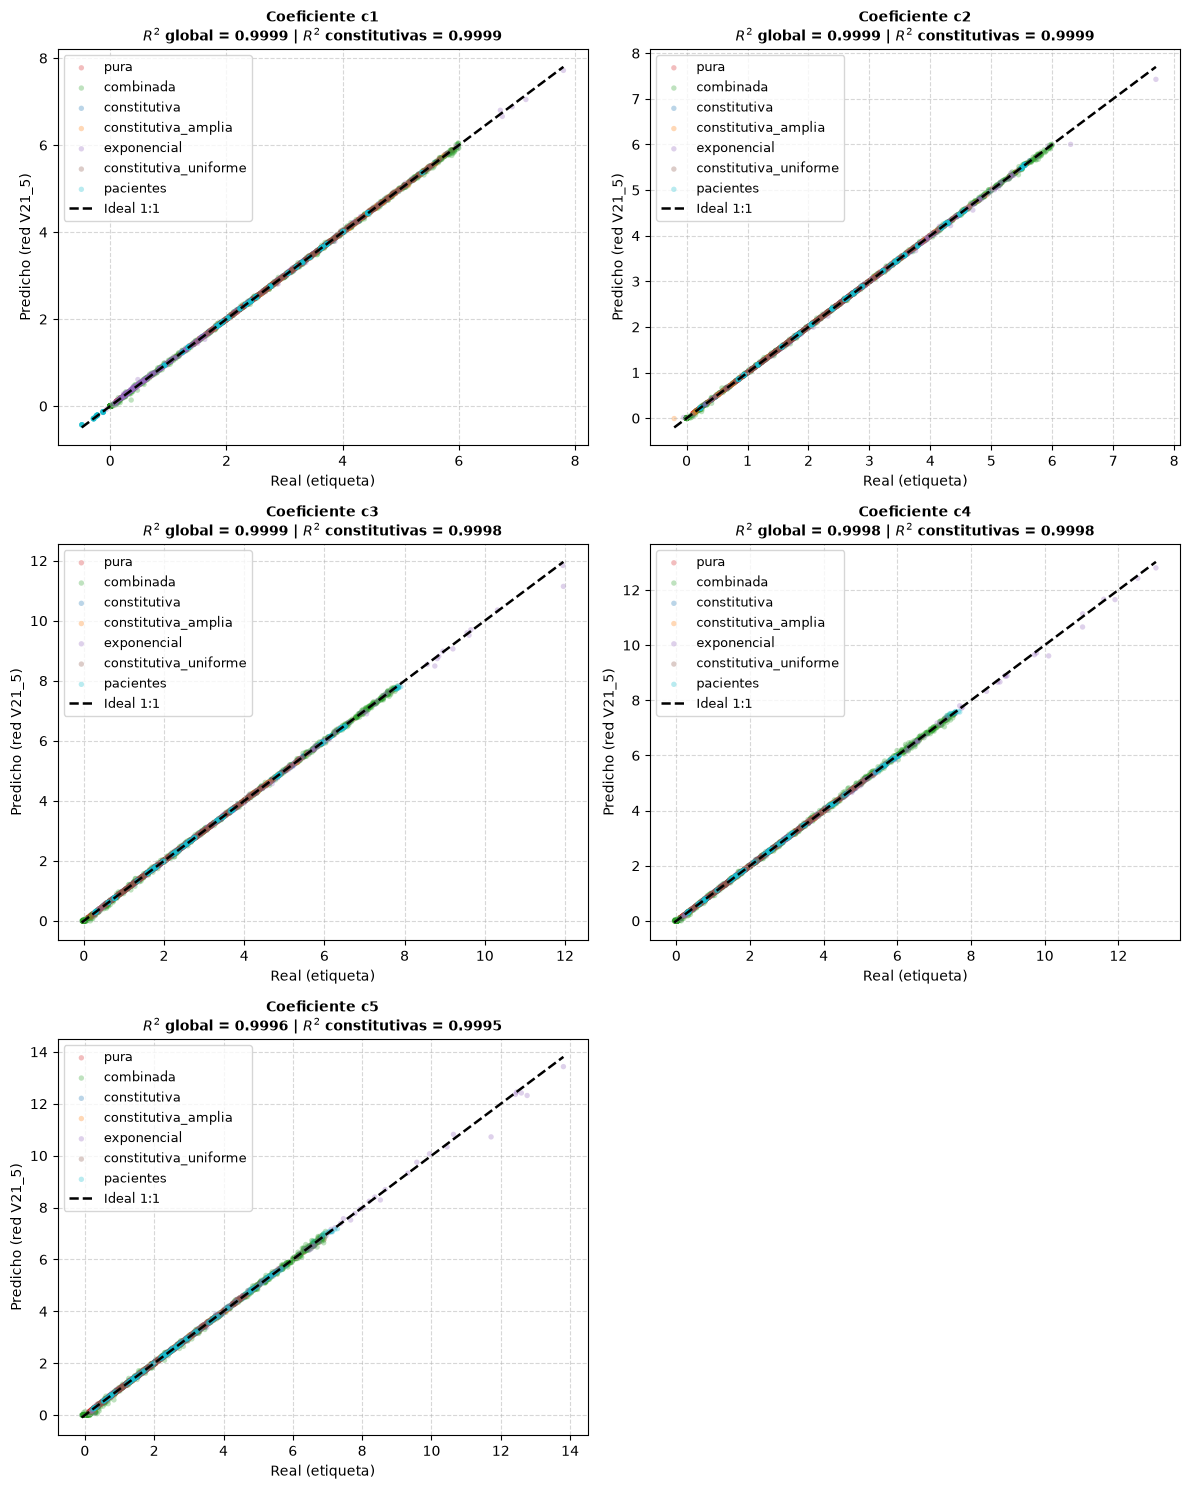

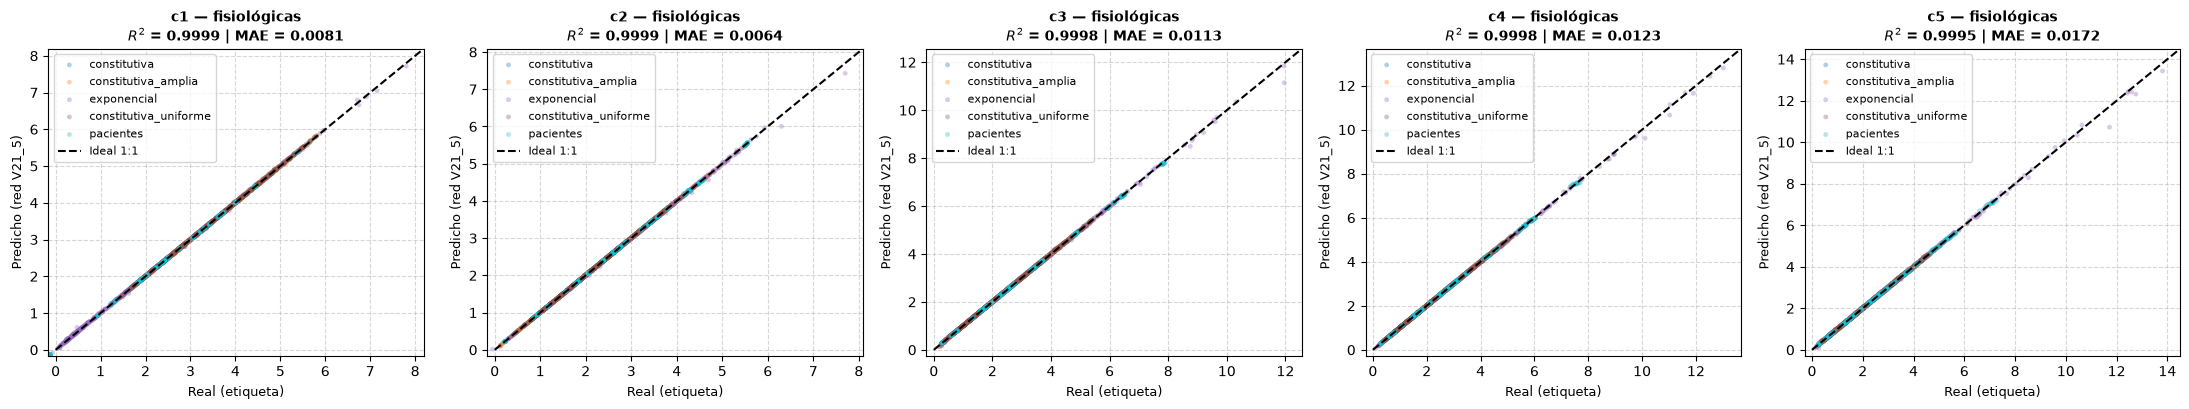

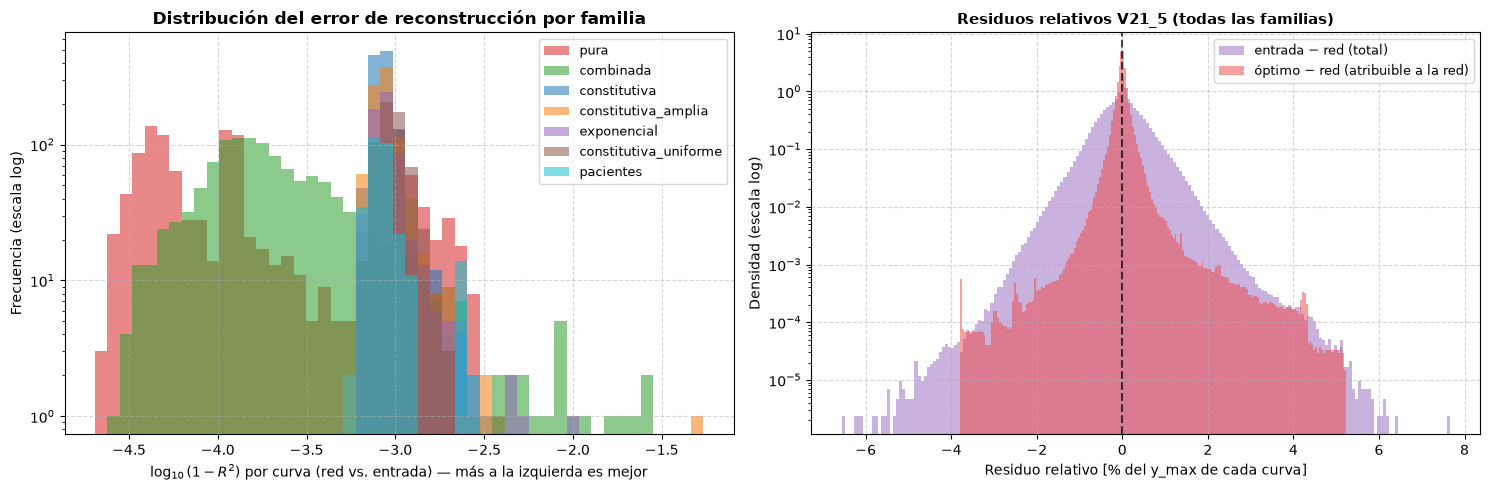


Percentiles de |residuo relativo| [% de y_max] (por punto):
Familia         | tipo         |     p50     p95     p99     máx
pura            | total        |   0.064   0.571   0.900   2.654
pura            | red−óptimo   |   0.045   0.231   0.378   1.846
combinada       | total        |   0.160   0.804   1.525   6.175
combinada       | red−óptimo   |   0.118   0.606   1.382   5.235
constitutiva    | total        |   0.385   1.260   1.810   4.033
constitutiva    | red−óptimo   |   0.040   0.157   0.242   0.742
constitutiva_amplia | total        |   0.385   1.270   1.837   6.563
constitutiva_amplia | red−óptimo   |   0.043   0.174   0.277   3.785
exponencial     | total        |   0.435   1.333   1.930   7.651
exponencial     | red−óptimo   |   0.060   0.291   0.624   4.235
constitutiva_uniforme | total        |   0.395   1.283   1.840   4.389
constitutiva_uniforme | red−óptimo   |   0.050   0.224   0.346   1.483
pacientes       | total        |   0.407   1.292   1.835   3.873
pacientes

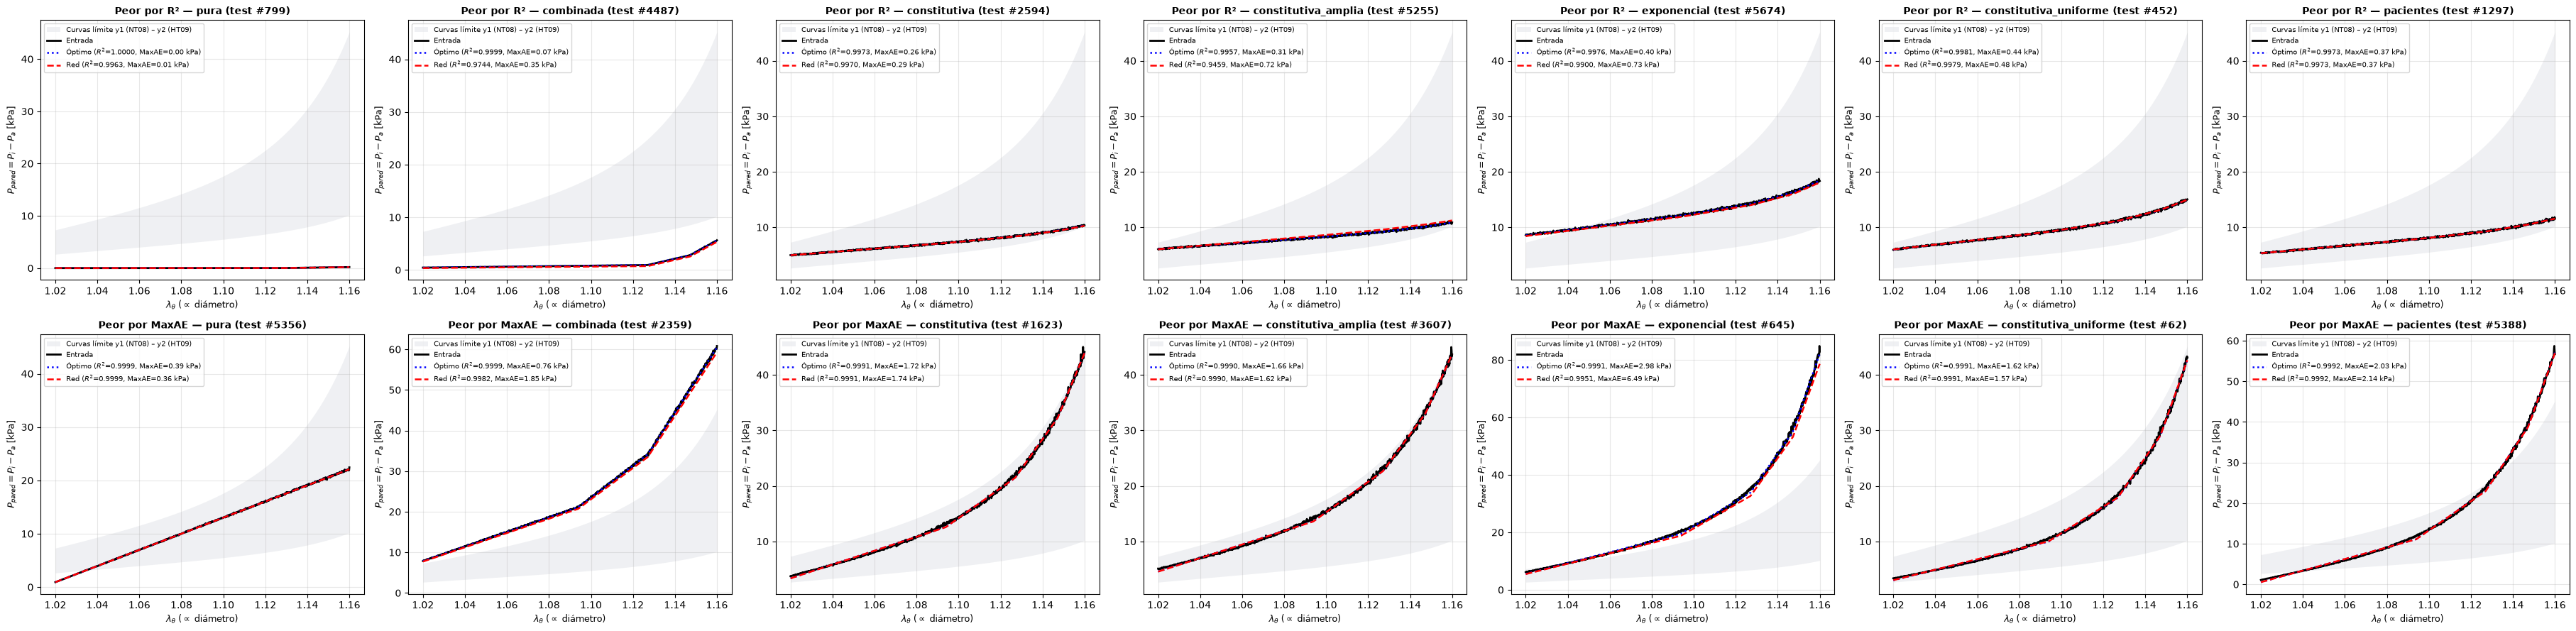

✅ Célula 12 ejecutada correctamente.


In [18]:
# ==============================================================================
# CÉLULA 12: EVALUACIÓN EN TEST — COEFICIENTES, BRECHA RED vs. ÓPTIMO, PEORES CASOS
# ==============================================================================
"""
Todas las métricas de curva comparan contra la curva de ENTRADA (la que ve la red):
  • red     : A·c_red      (coef_rn, proyectado sobre la caja)
  • óptimo  : A·c_lsq      (techo alcanzable con las bases sobre ESA curva)
La brecha red − óptimo es lo atribuible a la red; el óptimo mide el piso de las bases.
NRMSE y MaxAE_rel se calculan por curva con su propio rango (Célula 3).
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print(f"📊 Evaluando la red {VERSION.upper()} en el conjunto de prueba (Test)...\n")

c_rn, c_opt, c_crudo = EVAL["coef_rn"], EVAL["coef_opt"], EVAL["coef_crudo"]
b_in, b_rn, b_lsq = EVAL["b_in"], EVAL["b_rn"], EVAL["b_lsq"]
fam_t = EVAL["fam"]
N_COEFS = c_opt.shape[1]
M_RN = metricas_lote(b_in, b_rn)
M_OPT = metricas_lote(b_in, b_lsq)
m_env = np.isin(fam_t, FAMILIAS_OBJETIVO)      # familias fisiológicas = dominio objetivo


# --- 1. Coeficientes: global y restringido a las familias constitutivas --------------------------
def _tabla_coef(mask, titulo):
    print("=" * 80)
    print(f"🎯 PRECISIÓN DE COEFICIENTES — {titulo} (n = {mask.sum()})")
    print("=" * 80)
    print(f"{'Coef.':<8} | {'R²':>10} | {'MAE':>10} | {'RMSE':>10} | {'rango etiqueta':>16}")
    print("-" * 66)
    out = []
    for i in range(N_COEFS):
        yt, yp = c_opt[mask, i], c_rn[mask, i]
        fila = (r2_score(yt, yp), mean_absolute_error(yt, yp), np.sqrt(mean_squared_error(yt, yp)))
        out.append(fila)
        print(f"c{i+1:<7} | {fila[0]:10.6f} | {fila[1]:10.6f} | {fila[2]:10.6f} | [{yt.min():5.2f}, {yt.max():5.2f}]")
    out = np.array(out)
    print("-" * 66)
    print(f"{'PROMEDIO':<8} | {out[:, 0].mean():10.6f} | {out[:, 1].mean():10.6f} | {out[:, 2].mean():10.6f}")
    return out


COEF_GLOBAL = _tabla_coef(np.ones_like(fam_t, dtype=bool), "TODAS LAS FAMILIAS")
COEF_ENV = _tabla_coef(m_env, "SOLO FAMILIAS FISIOLÓGICAS (constitutivas, uniformes, exponencial y pacientes; dominio objetivo)")
print("   (el R² global se infla porque las familias 0 y 1 estiran el rango de las etiquetas a [0, C_GEN_MAX])")

neg = c_crudo < COEF_MIN
print(f"\n🔒 Predicciones negativas (capa no fabricable): {neg.mean():.2%} de los coeficientes "
      f"(MCO sin cotas: no se proyectan)")

# --- 2. Reconstrucción por familia: red vs. óptimo sobre la misma curva --------------------------
print("\n" + "=" * 118)
print("🧬 RECONSTRUCCIÓN POR FAMILIA (contra la curva de entrada)")
print("=" * 118)
print(f"{'Familia':<15} {'n':>5} | {'R² óptimo':>10} {'R² red':>9} {'med. red':>9} {'mín. red':>9} {'(test #)':>9} | "
      f"{'NRMSE ópt.':>10} {'NRMSE red':>10} {'p95 red':>8} | {'Exceso':>8} | {'MaxAE_rel p95':>13}")
_eps_lim = metricas_lote(EVAL["b_limpio"], b_rn)["MaxAE_rel"]     # error punto a punto de la red vs. la curva SIN ruido
_eps_lim_opt = metricas_lote(EVAL["b_limpio"], b_lsq)["MaxAE_rel"]
print("-" * 118)
RESUMEN_FAM = []
for f, nombre in FAMILIAS.items():
    m = fam_t == f
    i_peor = int(np.where(m)[0][np.nanargmin(M_RN["R2"][m])])
    i_peor_kpa = int(np.where(m)[0][np.nanargmax(M_RN["MaxAE"][m])])
    exceso = (np.nanmean(M_RN["NRMSE"][m]) / np.nanmean(M_OPT["NRMSE"][m]) - 1.0) * 100.0
    fila = dict(familia=nombre, n=int(m.sum()),
                R2_opt=np.nanmean(M_OPT["R2"][m]), R2_red=np.nanmean(M_RN["R2"][m]),
                R2_red_mediana=np.nanmedian(M_RN["R2"][m]), R2_red_min=np.nanmin(M_RN["R2"][m]),
                R2_opt_en_peor=M_OPT["R2"][i_peor], idx_peor=i_peor, idx_peor_kpa=i_peor_kpa,
                NRMSE_opt=np.nanmean(M_OPT["NRMSE"][m]), NRMSE_red=np.nanmean(M_RN["NRMSE"][m]),
                NRMSE_red_mediana=np.nanmedian(M_RN["NRMSE"][m]), NRMSE_red_p95=np.nanpercentile(M_RN["NRMSE"][m], 95),
                exceso_NRMSE_pct=exceso, MaxAE_rel_p95=np.nanpercentile(M_RN["MaxAE_rel"][m], 95),
                MaxAE_kPa_max=np.nanmax(M_RN["MaxAE"][m]),
                MAE_coef=np.abs(c_opt[m] - c_rn[m]).mean(axis=0))
    RESUMEN_FAM.append(fila)
    print(f"{nombre:<15} {fila['n']:>5} | {fila['R2_opt']:10.5f} {fila['R2_red']:9.5f} {fila['R2_red_mediana']:9.5f} "
          f"{fila['R2_red_min']:9.5f} {i_peor:>9d} | {fila['NRMSE_opt']:9.3f}% {fila['NRMSE_red']:9.3f}% "
          f"{fila['NRMSE_red_p95']:7.3f}% | {exceso:+7.1f}% | {fila['MaxAE_rel_p95']:12.3f}%")
print("-" * 118)
print("Exceso = NRMSE medio de la red / NRMSE medio del óptimo − 1 (lo que pierde la red frente al techo de las bases).")
print(f"\n🎯 Criterio error punto a punto ≤ {ERROR_MAX_PCT:g}% contra la curva SIN ruido (red | óptimo MCO de la entrada con ruido):")
for f, nombre in FAMILIAS.items():
    m = fam_t == f
    print(f"   • {nombre:<20}: red {np.mean(_eps_lim[m] <= ERROR_MAX_PCT):7.2%} (máx. {np.nanmax(_eps_lim[m]):5.2f}%) | "
          f"MCO {np.mean(_eps_lim_opt[m] <= ERROR_MAX_PCT):7.2%} (máx. {np.nanmax(_eps_lim_opt[m]):5.2f}%)")
print("\nMAE de coeficientes por familia:")
for fila in RESUMEN_FAM:
    print(f"   • {fila['familia']:<15}: {np.round(fila['MAE_coef'], 4)} | peor por R²: test #{fila['idx_peor']} "
          f"(R² red {fila['R2_red_min']:.5f} vs. óptimo {fila['R2_opt_en_peor']:.5f}) | peor por MaxAE: "
          f"test #{fila['idx_peor_kpa']} ({fila['MaxAE_kPa_max']:.2f} kPa; óptimo {M_OPT['MaxAE'][fila['idx_peor_kpa']]:.2f} kPa)")
print("   (el peor por R² tiende a ser una curva de poca amplitud; el peor por MaxAE, una de mucha amplitud)")

# --- 3. Persistencia de métricas por curva (para el artículo) ------------------------------------
DF_TEST = pd.DataFrame({"idx_test": np.arange(len(fam_t)), "idx_dataset": EVAL["idx"],
                        "familia": [FAMILIAS[int(f)] for f in fam_t]})
for k in ("R2", "NRMSE", "MaxAE", "MaxAE_rel"):
    DF_TEST[f"{k}_red"], DF_TEST[f"{k}_opt"] = M_RN[k], M_OPT[k]
for i in range(N_COEFS):
    DF_TEST[f"c{i+1}_etiqueta"], DF_TEST[f"c{i+1}_red"], DF_TEST[f"c{i+1}_crudo"] = c_opt[:, i], c_rn[:, i], c_crudo[:, i]
DF_TEST.to_csv(f"metricas_test_por_curva_{VERSION}.csv", index=False)
pd.DataFrame([{k: v for k, v in r.items() if k != "MAE_coef"} for r in RESUMEN_FAM]).to_csv(
    f"resumen_test_por_familia_{VERSION}.csv", index=False)
print(f"\n💾 'metricas_test_por_curva_{VERSION}.csv' y 'resumen_test_por_familia_{VERSION}.csv' guardados.")

# --- Figura 1: regresión 1:1 de coeficientes ------------------------------------------------------
colores = {0: "#d62728", 1: "#2ca02c", 2: "#1f77b4", 3: "#ff7f0e", 4: "#9467bd", 5: "#8c564b", 6: "#17becf"}
n_cols = 2
n_rows = int(np.ceil(N_COEFS / n_cols))
fig1, axes1 = plt.subplots(n_rows, n_cols, figsize=(12, 5 * n_rows), squeeze=False)
axes1 = axes1.flatten()
for i in range(N_COEFS):
    ax = axes1[i]
    for f, nombre in FAMILIAS.items():
        m = fam_t == f
        ax.scatter(c_opt[m, i], c_rn[m, i], alpha=0.3, color=colores[f], edgecolors="none", s=15, label=nombre)
    lims = [min(c_opt[:, i].min(), c_rn[:, i].min()), max(c_opt[:, i].max(), c_rn[:, i].max())]
    ax.plot(lims, lims, "k--", label="Ideal 1:1", linewidth=1.8)
    ax.set_title(f"Coeficiente c{i+1}\n$R^2$ global = {COEF_GLOBAL[i, 0]:.4f} | $R^2$ constitutivas = {COEF_ENV[i, 0]:.4f}",
                 fontweight="bold", fontsize=10)
    ax.set_xlabel("Real (etiqueta)", fontsize=10)
    ax.set_ylabel(f"Predicho (red {VERSION.upper()})", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left", fontsize=9)
for j in range(N_COEFS, len(axes1)):
    axes1[j].axis("off")
plt.tight_layout()
plt.savefig(f"diagnostico_coeficientes_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Figura 1b: regresión 1:1 solo en el dominio objetivo (familias constitutivas) ----------------
fig1b, axes1b = plt.subplots(1, N_COEFS, figsize=(4.4 * N_COEFS, 4.2), squeeze=False)
for i in range(N_COEFS):
    ax = axes1b[0, i]
    for f in FAMILIAS_OBJETIVO:
        m = fam_t == f
        ax.scatter(c_opt[m, i], c_rn[m, i], alpha=0.35, color=colores[f], edgecolors="none", s=12, label=FAMILIAS[f])
    hi = 1.05 * max(c_opt[m_env, i].max(), c_rn[m_env, i].max(), 1e-3)
    ax.plot([0, hi], [0, hi], "k--", linewidth=1.5, label="Ideal 1:1")
    ax.set_xlim(-0.02 * hi, hi)
    ax.set_ylim(-0.02 * hi, hi)
    ax.set_title(f"c{i+1} — fisiológicas\n$R^2$ = {COEF_ENV[i, 0]:.4f} | MAE = {COEF_ENV[i, 1]:.4f}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Real (etiqueta)", fontsize=9)
    ax.set_ylabel(f"Predicho (red {VERSION.upper()})", fontsize=9)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(f"diagnostico_coeficientes_constitutivas_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Figura 2: log10(1 − R²) por familia y residuos relativos ------------------------------------
fig2, (ax_r2, ax_res) = plt.subplots(1, 2, figsize=(15, 5))
log_err = np.log10(np.clip(1.0 - M_RN["R2"], 1e-8, None))
bins = np.linspace(np.nanmin(log_err), np.nanmax(log_err), 50)
for f, nombre in FAMILIAS.items():
    m = fam_t == f
    ax_r2.hist(log_err[m], bins=bins, alpha=0.55, color=colores[f], label=nombre)
ax_r2.set_yscale("log")
ax_r2.set_xlabel(r"$\log_{10}(1 - R^2)$ por curva (red vs. entrada) — más a la izquierda es mejor", fontsize=10)
ax_r2.set_ylabel("Frecuencia (escala log)", fontsize=10)
ax_r2.set_title("Distribución del error de reconstrucción por familia", fontweight="bold")
ax_r2.grid(True, linestyle="--", alpha=0.5)
ax_r2.legend(fontsize=9)

y_max_curva = np.maximum(b_in.max(axis=1, keepdims=True), 1.0)
res_red_rel = ((b_lsq - b_rn) / y_max_curva * 100.0)       # error atribuible a la red (% de y_max)
res_tot_rel = ((b_in - b_rn) / y_max_curva * 100.0)        # error total contra la entrada
for datos, color, etiqueta in [(res_tot_rel, "#9467bd", "entrada − red (total)"),
                               (res_red_rel, "#ef4444", "óptimo − red (atribuible a la red)")]:
    ax_res.hist(datos.flatten(), bins=200, density=True, alpha=0.5, color=color, label=etiqueta)
ax_res.set_yscale("log")
ax_res.axvline(0, color="black", linestyle="--", alpha=0.7)
ax_res.set_xlabel("Residuo relativo [% del y_max de cada curva]", fontsize=10)
ax_res.set_ylabel("Densidad (escala log)", fontsize=10)
ax_res.set_title(f"Residuos relativos {VERSION.upper()} (todas las familias)", fontsize=11, fontweight="bold")
ax_res.legend(fontsize=9)
ax_res.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(f"distribucion_residuos_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nPercentiles de |residuo relativo| [% de y_max] (por punto):")
print(f"{'Familia':<15} | {'tipo':<12} | {'p50':>7} {'p95':>7} {'p99':>7} {'máx':>7}")
for f, nombre in FAMILIAS.items():
    m = fam_t == f
    for tipo, datos in [("total", res_tot_rel), ("red−óptimo", res_red_rel)]:
        q = np.percentile(np.abs(datos[m]), [50, 95, 99, 100])
        print(f"{nombre:<15} | {tipo:<12} | {q[0]:7.3f} {q[1]:7.3f} {q[2]:7.3f} {q[3]:7.3f}")

# --- Figura 3: peor caso de cada familia ------------------------------------------------------------
fig3, axes3 = plt.subplots(2, len(FAMILIAS), figsize=(5.2 * len(FAMILIAS), 9), squeeze=False)
for col, fila in enumerate(RESUMEN_FAM):
    for row, (clave, criterio) in enumerate([("idx_peor", "R²"), ("idx_peor_kpa", "MaxAE")]):
        ax = axes3[row, col]
        s = fila[clave]
        ax.fill_between(X_MESH_999, BANDA_INF, BANDA_SUP, color="#e5e7eb", alpha=0.6, lw=0, label=ETQ_BANDA)
        ax.plot(X_MESH_999, b_in[s], "k-", lw=2, label="Entrada")
        ax.plot(X_MESH_999, b_lsq[s], "b:", lw=1.8,
                label=f"Óptimo ($R^2$={M_OPT['R2'][s]:.4f}, MaxAE={M_OPT['MaxAE'][s]:.2f} kPa)")
        ax.plot(X_MESH_999, b_rn[s], "r--", lw=1.8,
                label=f"Red ($R^2$={M_RN['R2'][s]:.4f}, MaxAE={M_RN['MaxAE'][s]:.2f} kPa)")
        ax.set_title(f"Peor por {criterio} — {fila['familia']} (test #{s})", fontsize=10, fontweight="bold")
        ax.set_xlabel(ETQ_X, fontsize=9)
        ax.set_ylabel(ETQ_Y, fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.savefig(f"peores_casos_test_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

print("✅ Célula 12 ejecutada correctamente.")

## Célula 12b — Generalización dentro de la clase (Fung) y control de clase a la entrada

In [19]:
# ==============================================================================
# CÉLULA 12b: GENERALIZACIÓN DENTRO DE LA CLASE (FUNG) Y CONTROL DE CLASE A LA ENTRADA
# ==============================================================================
"""
1) OOD dentro de la clase: curvas J de otra familia funcional, nunca vista en el entrenamiento:
       P(λ) = C + A·(exp(B·(λ − λ_min)) − 1),   A, B, C > 0   (ley exponencial tipo Fung)
   con (A, B, C) = media geométrica ponderada (Dirichlet) de los ajustes de 2–3 sujetos de entrenamiento
   + perturbación log-normal: misma región de la población, otra forma funcional.
   Métrica principal: brecha red − óptimo MCO sobre la misma curva.
2) Control de clase: curvas fuera de la clase (sujetos de test modulados con una oscilación, no
   monótonas o no convexas desde X_INICIO_CONVEXIDAD). es_curva_J debe rechazarlas, y aceptar las curvas Fung con ruido.
   Para una curva rechazada el método devuelve el óptimo MCO (exacto para cualquier entrada).
"""
import numpy as np
from scipy.optimize import curve_fit

N_OOD = 300
RUIDO_OOD = 0.01
rng_ood = np.random.default_rng(SEED_DATASET + 1)
t_ood = X_MESH_999 - X_MIN_DOMINIO


def fung(x, A, B, C):
    return C + A * (np.exp(B * (x - X_MIN_DOMINIO)) - 1.0)


# --- 1. Ajuste Fung a los sujetos de entrenamiento → rango de parámetros ------------------------
P_FUNG = []
for y in POB_Y[MASK_POB_TRAIN]:
    p, _ = curve_fit(fung, X_MESH_999, y, p0=(5.0, 20.0, max(float(y[0]), 0.01)), bounds=([1e-6, 1e-3, 0.0], [1e4, 200.0, 1e3]),
                     maxfev=20000)
    P_FUNG.append(p)
P_FUNG = np.array(P_FUNG)
lo_p, hi_p = P_FUNG.min(axis=0), P_FUNG.max(axis=0)
r2_fung = [1 - np.sum((y - fung(X_MESH_999, *p)) ** 2) / np.sum((y - y.mean()) ** 2)
           for y, p in zip(POB_Y[MASK_POB_TRAIN], P_FUNG)]
print(f"📐 Ajuste Fung a {len(P_FUNG)} sujetos de entrenamiento (R² mín. {min(r2_fung):.4f}): "
      f"A ∈ [{lo_p[0]:.2f}, {hi_p[0]:.2f}] kPa | B ∈ [{lo_p[1]:.1f}, {hi_p[1]:.1f}] | C ∈ [{lo_p[2]:.1f}, {hi_p[2]:.1f}] kPa")

SD_LOG_FUNG = 0.10
Y_fung = []
while len(Y_fung) < N_OOD:
    k = rng_ood.integers(2, 4)
    idx = rng_ood.choice(len(P_FUNG), size=k, replace=False)
    logp = rng_ood.dirichlet(np.ones(k)) @ np.log(P_FUNG[idx]) + rng_ood.normal(0.0, SD_LOG_FUNG, size=3)
    y0 = fung(X_MESH_999, *np.exp(logp))
    if y0.min() > 0 and y0.max() <= SIGMA_MAX_KPA:          # Fung no es la ley de Masson: no se acota por y1–y2
        Y_fung.append(y0)
Y_fung = np.array(Y_fung)
fuera_banda = np.mean((Y_fung < BANDA_INF - 1e-9) | (Y_fung > BANDA_SUP + 1e-9))
d_fung = np.array([np.min(np.sqrt(np.mean((POB_Y[MASK_POB_TRAIN] - y) ** 2, axis=1))) / y.max() for y in Y_fung])
print(f"   Curvas Fung: puntos fuera de [y1, y2] {fuera_banda:.1%} | distancia relativa al sujeto "
      f"más cercano: mediana {np.median(d_fung):.2%}")
Y_fung_r = np.maximum(Y_fung + rng_ood.normal(0.0, RUIDO_OOD, size=Y_fung.shape) * np.abs(Y_fung), TENSION_MIN_KPA)

c_opt = np.array([optimo_mc(A_base, y) for y in Y_fung_r])
c_rn = np.clip(sy.inverse_transform(model.predict(sx.transform(safe_log_transform(Y_fung_r)), verbose=0)),
               COTA_INF, COTA_SUP)
M_rn, M_opt = metricas_lote(Y_fung_r, c_rn @ A_base.T), metricas_lote(Y_fung_r, c_opt @ A_base.T)
exc = (np.nanmean(M_rn["NRMSE"]) / np.nanmean(M_opt["NRMSE"]) - 1) * 100
i_p = int(np.nanargmin(M_rn["R2"]))
RES_OOD = dict(M_rn=M_rn, M_opt=M_opt, exceso_NRMSE_pct=exc)
print("\n🧪 OOD dentro de la clase (ley tipo Fung, con ruido 1 %)")
print(f"   R² red {np.nanmean(M_rn['R2']):.5f} | óptimo {np.nanmean(M_opt['R2']):.5f} | "
      f"NRMSE red {np.nanmean(M_rn['NRMSE']):.3f}% | óptimo {np.nanmean(M_opt['NRMSE']):.3f}% | exceso {exc:+.1f}%")
print(f"   Peor caso: R² red {M_rn['R2'][i_p]:.5f} (óptimo en esa curva {M_opt['R2'][i_p]:.5f}) | "
      f"p95 NRMSE red {np.nanpercentile(M_rn['NRMSE'], 95):.3f}%")
_c_crudo_ood = sy.inverse_transform(model.predict(sx.transform(safe_log_transform(Y_fung_r)), verbose=0))
_pul_ood = [pulir(A_base, y, c)[1] for y, c in zip(Y_fung_r, _c_crudo_ood)]
print(f"   Red + pulido (MCO): óptimo exacto en {np.mean(_pul_ood):.1%} de las curvas Fung | MCO fabricable (c ≥ 0) en "
      f"{np.mean(np.all(c_opt >= COEF_MIN - 1e-9, axis=1)):.1%}")

# --- 2. Control de clase -------------------------------------------------------------------------
Y_fuera = []
for y in POB_Y[MASK_POB_TEST]:
    for _ in range(max(1, N_OOD // (4 * MASK_POB_TEST.sum()))):
        f = rng_ood.uniform(1.0, 3.0)
        amp = rng_ood.uniform(0.10, 0.30)
        mod = 1.0 + amp * np.sin(2 * np.pi * f * t_ood / t_ood[-1] + rng_ood.uniform(0, 2 * np.pi))
        Y_fuera.append(y * mod)
Y_fuera = np.array(Y_fuera)
Y_fuera_r = np.maximum(Y_fuera + rng_ood.normal(0.0, RUIDO_OOD, size=Y_fuera.shape) * np.abs(Y_fuera), TENSION_MIN_KPA)
fuera_de_clase = np.array([not all(diagnostico_forma(y)) for y in Y_fuera])      # verdad (curva limpia)

dist_fung = np.array([distancia_a_clase_J(y) for y in Y_fung_r])
dist_fuera = np.array([distancia_a_clase_J(y) for y in Y_fuera_r])
dist_suj = np.array([distancia_a_clase_J(y) for y in POB_Y])
acept_fung, acept_fuera, acept_suj = (dist_fung <= TOL_CLASE_NRMSE, dist_fuera <= TOL_CLASE_NRMSE,
                                      dist_suj <= TOL_CLASE_NRMSE)
print(f"\n🛂 Control de clase es_curva_J (tolerancia {TOL_CLASE_NRMSE}%; distancias mediana [máx])")
print(f"   distancias: Fung con ruido {np.median(dist_fung):.2f}% [{dist_fung.max():.2f}%] | sujetos "
      f"{np.median(dist_suj):.2f}% [{dist_suj.max():.2f}%] | moduladas fuera de clase "
      f"{np.median(dist_fuera[fuera_de_clase]):.2f}% [mín. {dist_fuera[fuera_de_clase].min():.2f}%]")
print(f"   • Curvas Fung (en clase)           : aceptadas {acept_fung.mean():.1%}")
print(f"   • Sujetos reales (en clase)        : aceptados {acept_suj.mean():.1%}")
print(f"   • Moduladas fuera de la clase (n={fuera_de_clase.sum()}): rechazadas {(~acept_fuera[fuera_de_clase]).mean():.1%}")
if (~fuera_de_clase).any():
    print(f"   • Moduladas que siguieron siendo J (n={(~fuera_de_clase).sum()}): aceptadas {acept_fuera[~fuera_de_clase].mean():.1%}")
print("   Para una curva rechazada, la salida del método es el óptimo MCO (exacto) en lugar de la red.")

📐 Ajuste Fung a 31 sujetos de entrenamiento (R² mín. 0.9947): A ∈ [0.92, 5.54] kPa | B ∈ [7.2, 25.4] | C ∈ [1.2, 8.4] kPa
   Curvas Fung: puntos fuera de [y1, y2] 7.8% | distancia relativa al sujeto más cercano: mediana 3.19%

🧪 OOD dentro de la clase (ley tipo Fung, con ruido 1 %)
   R² red 0.99818 | óptimo 0.99832 | NRMSE red 1.159% | óptimo 1.117% | exceso +3.7%
   Peor caso: R² red 0.99602 (óptimo en esa curva 0.99712) | p95 NRMSE red 1.315%
   Red + pulido (MCO): óptimo exacto en 100.0% de las curvas Fung | MCO fabricable (c ≥ 0) en 99.7%

🛂 Control de clase es_curva_J (tolerancia 2.0%; distancias mediana [máx])
   distancias: Fung con ruido 0.54% [1.43%] | sujetos 0.06% [0.08%] | moduladas fuera de clase 4.51% [mín. 1.35%]
   • Curvas Fung (en clase)           : aceptadas 100.0%
   • Sujetos reales (en clase)        : aceptados 100.0%
   • Moduladas fuera de la clase (n=47): rechazadas 95.7%
   • Moduladas que siguieron siendo J (n=23): aceptadas 73.9%
   Para una curva rechazada

## Célula 13 — Reconstrucción de muestras aleatorias (escala por panel)

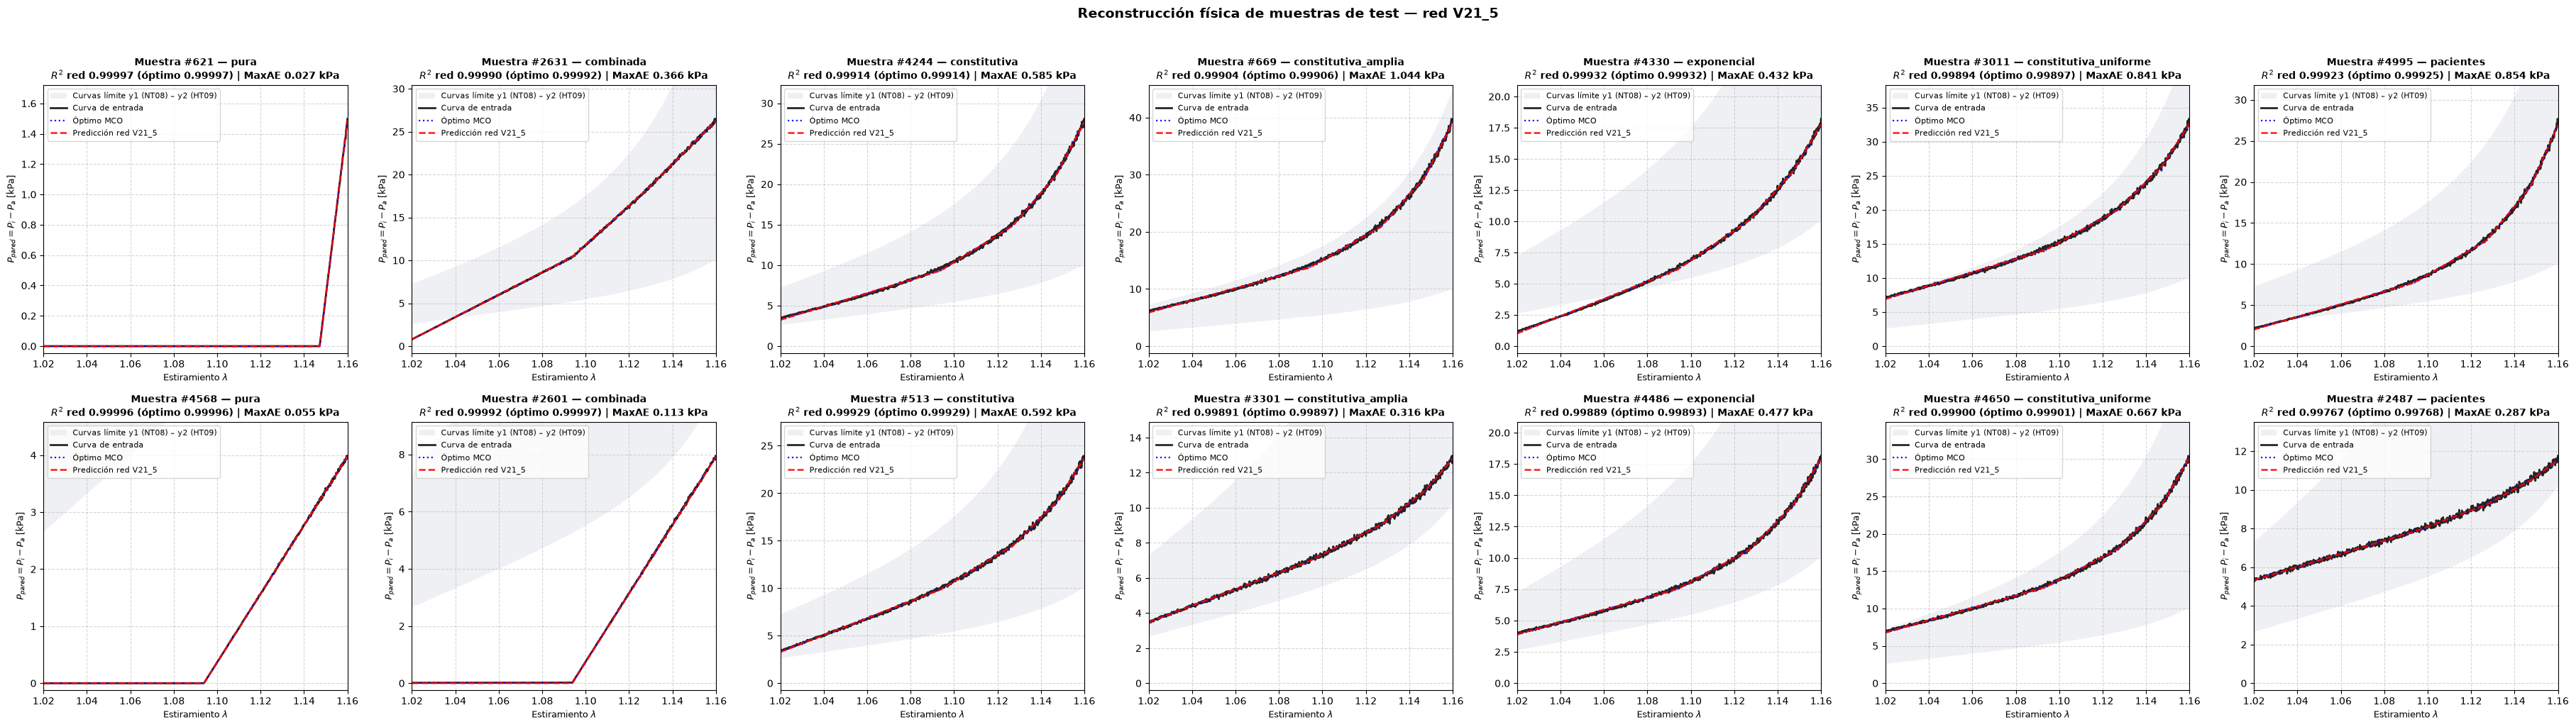

✅ Célula 13 ejecutada. Ventana: λ ∈ [1.02, 1.16] | escala vertical por panel.


In [20]:
# ==============================================================================
# CÉLULA 13: RECONSTRUCCIÓN FÍSICA DE MUESTRAS ALEATORIAS (2 POR FAMILIA)
# ==============================================================================
"""
Escala vertical por panel.
Los peores casos de cada familia están en la Figura 3 de la Célula 12.
"""
import numpy as np
import matplotlib.pyplot as plt

rng_plot = np.random.default_rng(SEED)
indices_muestras = []
for f in sorted(FAMILIAS):
    cand = np.where(EVAL["fam"] == f)[0]
    indices_muestras += [int(i) for i in rng_plot.choice(cand, size=min(2, len(cand)), replace=False)]

n_cols = len(FAMILIAS)
fig, axes = plt.subplots(2, n_cols, figsize=(5.2 * n_cols, 10), squeeze=False)
indices_muestras = [indices_muestras[2 * j + r] for r in range(2) for j in range(n_cols)]   # fila = muestra, columna = familia
for ax, s in zip(axes.flatten(), indices_muestras):
    b_in, b_pred, b_lsq = EVAL["b_in"][s], EVAL["b_rn"][s], EVAL["b_lsq"][s]
    m_rn, m_lsq = metricas_curva(b_in, b_pred), metricas_curva(b_in, b_lsq)
    ax.fill_between(X_MESH_999, BANDA_INF, BANDA_SUP, color="#e5e7eb", alpha=0.6, lw=0, label=ETQ_BANDA)
    ax.plot(X_MESH_999, b_in, "k-", linewidth=2.0, label="Curva de entrada", alpha=0.85)
    ax.plot(X_MESH_999, b_lsq, "b:", linewidth=1.6, label="Óptimo MCO", alpha=0.9)
    ax.plot(X_MESH_999, b_pred, "r--", linewidth=1.8, label=f"Predicción red {VERSION.upper()}", alpha=0.9)
    ax.set_title(f"Muestra #{s} — {FAMILIAS[int(EVAL['fam'][s])]}\n"
                 f"$R^2$ red {m_rn['R2']:.5f} (óptimo {m_lsq['R2']:.5f}) | MaxAE {m_rn['MaxAE']:.3f} kPa",
                 fontweight="bold", fontsize=10)
    ax.set_xlabel(r"Estiramiento $\lambda$", fontsize=9)
    ax.set_ylabel(ETQ_Y, fontsize=9)
    ax.set_xlim(X_MIN_DOMINIO, X_MAX_DOMINIO)
    ax.set_ylim(-0.03 * max(b_in.max(), 1.0), 1.15 * max(b_in.max(), 1.0))
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left", fontsize=8)

plt.suptitle(f"Reconstrucción física de muestras de test — red {VERSION.upper()}",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"reconstruccion_ejemplos_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ Célula 13 ejecutada. Ventana: λ ∈ [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}] | escala vertical por panel.")

## Célula 14 — Diseñador de injerto: curva presión–diámetro → cantidad de cada capa (red + pulido = óptimo MCO exacto; láminas de cada material)

📂 Cargando base funcional (malla unificada)...
   • Malla: 999 puntos en [1.020, 1.160] | Bases: 5
✅ Sistema cargado (v21_5) | OFFSET_LOG = 5.0000
🫀 Curva de Masson et al.: Mean HT (media reconstruida)
   Control de clase (curva realizable con telas): ✅ dentro

🎯 COEFICIENTES (N_BASES = 5)
Material | Láminas Óptimo MCO     | Láminas red  | Diferencia 
------------------------------------------------------------------------------------
1        | 2.345222               | 2.343108     | 0.002114   
2        | 3.058752               | 3.048181     | 0.010571   
3        | 3.422546               | 3.414922     | 0.007623   
4        | 3.189297               | 3.183439     | 0.005857   
5        | 2.856292               | 2.867749     | -0.011457  
Total de láminas: MCO 14.872 | red 14.857 (C_LAM = 6 láminas máx. por material en el espacio de trabajo)

📊 MÉTRICAS EN [1.02, 1.16]
Métrica      | Óptimo MCO             | Red V21_5
---------------------------------------------------------------

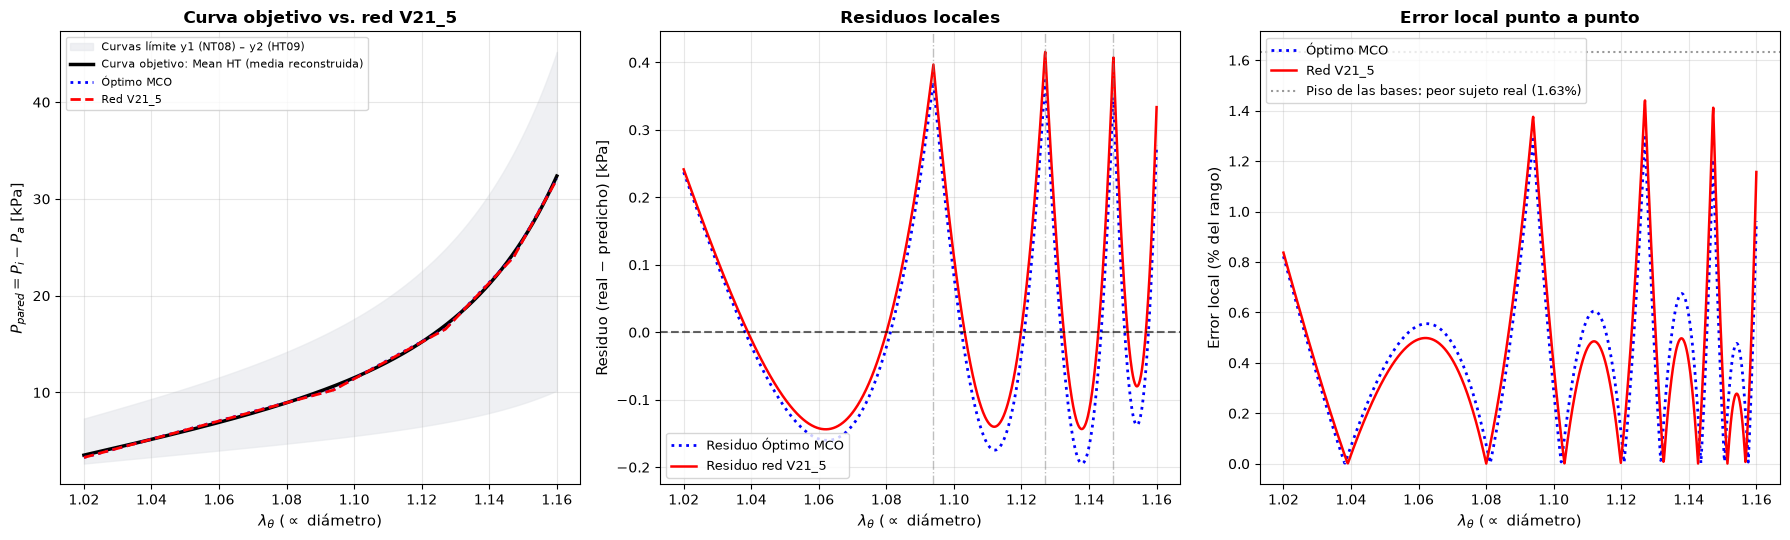

In [21]:
# ==============================================================================
# CÉLULA 14: EVALUADOR / DISEÑADOR DE INJERTO (curva presión–diámetro → láminas de cada material)
# ==============================================================================
"""
Requiere las Células G, M, 2 y 3, y el modelo guardado (Célula 8). Usa los MISMOS archivos, C_LAM y
OFFSET_LOG que el entrenamiento. No hace relleno ni recorte silencioso de features: si hay
incompatibilidad, falla.

Modos de entrada:
  'masson' : un sujeto reconstruido de Masson et al. (SUJETO_EVAL, p. ej. "HT07") o una curva media
             ("Mean Young", "Mean Old", "Mean NT", "Mean HT").
  'excel'  : columnas (λθ, P_pared [kPa]) en ARCHIVO_EXCEL_CURVA_J (P en kPa; 1 mmHg = 0,1333 kPa).
  'puntos' : lista PUNTOS_USUARIO interpolada (lineal o PCHIP).
Resultado: el método devuelve SIEMPRE el óptimo de MÍNIMOS CUADRADOS ORDINARIOS (MCO, sin cotas) exacto.
  • Curva dentro de la clase J: red → pulido (en MCO, un paso de mínimos cuadrados: ecuaciones normales).
  • Curva fuera de la clase: MCO directo.
La red sola (sin pulido) se muestra como comparación. Al final, tabla de diseño del injerto (capa, enganche,
número de láminas c, rigidez de la lámina) y si el injerto es fabricable (c ≥ 0); y el criterio de error punto a punto.
"""
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from tensorflow.keras.models import load_model

for _req in ("POB", "MEDIAS_RECONSTRUIDAS", "safe_log_transform", "metricas_curva", "optimo_mc", "es_curva_J", "C_LAM"):
    if _req not in globals():
        raise RuntimeError(f"Falta '{_req}': ejecutá primero las Células G, M, 2 y 3.")

# ── 1. CONFIGURACIÓN DEL EVALUADOR ────────────────────────────────────────────────────────────
MODO_ENTRADA = "masson"               # 'masson', 'excel' o 'puntos'
SUJETO_EVAL = "Mean HT"               # id de sujeto ("NT03", "HT12", ...) o nombre de curva media
ARCHIVO_EXCEL_CURVA_J = "Curva_J.xlsx"
TIPO_INTERPOLACION_PUNTOS = "pchip"   # 'lineal' o 'pchip'
COL_OPT = "Óptimo MCO"

PUNTOS_USUARIO = [(1.07, 7.0), (1.10, 12.0), (1.13, 20.0), (1.16, 36.0)]   # (λθ, P_pared [kPa])


# ── 2. CARGA DE ARCHIVOS ──────────────────────────────────────────────────────────────────────
def cargar_archivos_sistema():
    print("📂 Cargando base funcional (malla unificada)...")
    if not os.path.exists(ARCHIVO_BASES):
        raise FileNotFoundError(f"No se encontró '{ARCHIVO_BASES}'.")
    df_base = pd.read_excel(ARCHIVO_BASES, header=None)
    x_base = df_base.iloc[:, 0].values.astype(np.float64)
    A_base_ev = df_base.iloc[:, 1:].values.astype(np.float64)
    print(f"   • Malla: {len(x_base)} puntos en [{x_base[0]:.3f}, {x_base[-1]:.3f}] | Bases: {A_base_ev.shape[1]}")
    for f in (ARCHIVO_MODELO, ARCHIVO_SCALERS):
        if not os.path.exists(f):
            raise FileNotFoundError(f"No se encontró '{f}'. Ejecutá la Célula 8 (guarda ambos archivos).")
    modelo = load_model(ARCHIVO_MODELO, compile=False)
    with open(ARCHIVO_SCALERS, "rb") as f:
        meta = pickle.load(f)
    sx_l, sy_l, offset_l = meta["scaler_x"], meta["scaler_y"], meta["offset_log"]
    if modelo.input_shape[-1] != len(x_base) or sx_l.n_features_in_ != len(x_base):
        raise ValueError(f"Incompatibilidad: modelo espera {modelo.input_shape[-1]} features, "
                         f"escalador {sx_l.n_features_in_}, malla de bases {len(x_base)}.")
    if modelo.output_shape[-1] != A_base_ev.shape[1]:
        raise ValueError(f"Incompatibilidad: el modelo predice {modelo.output_shape[-1]} coeficientes "
                         f"y las bases son {A_base_ev.shape[1]}.")
    print(f"✅ Sistema cargado ({meta.get('version', '?')}) | OFFSET_LOG = {offset_l:.4f}")
    return x_base, A_base_ev, modelo, sx_l, sy_l, offset_l


def predecir_coeficientes(modelo, sx_l, sy_l, offset_l, Y):
    """Coeficientes de la red para una o varias curvas (V20, MCO: sin proyección sobre cotas)."""
    Y = np.atleast_2d(Y)
    crudo = sy_l.inverse_transform(modelo.predict(sx_l.transform(safe_log_transform(Y, offset=offset_l)), verbose=0))
    return crudo, np.clip(crudo, COTA_INF, COTA_SUP)


# ── 3. CURVA OBJETIVO ──────────────────────────────────────────────────────────────────────────
def generar_curva_objetivo(x_base):
    puntos_ctrl = None
    if MODO_ENTRADA == "masson":
        if SUJETO_EVAL in MEDIAS_RECONSTRUIDAS:
            y = np.interp(x_base, X_MESH_999, MEDIAS_RECONSTRUIDAS[SUJETO_EVAL])
            etiqueta = f"{SUJETO_EVAL} (media reconstruida)"
        else:
            fila = POB[POB["id"] == SUJETO_EVAL]
            if fila.empty:
                raise ValueError(f"SUJETO_EVAL '{SUJETO_EVAL}' no existe. Opciones: {list(POB['id'])} o "
                                 f"{list(MEDIAS_RECONSTRUIDAS)}")
            y = curva_objetivo(x_base, fila.iloc[0])
            etiqueta = f"{SUJETO_EVAL} ({'test' if bool(fila.iloc[0]['test']) else 'entrenamiento'})"
        print(f"🫀 Curva de Masson et al.: {etiqueta}")
        return y, puntos_ctrl, etiqueta
    if MODO_ENTRADA == "excel":
        print(f"📖 Cargando curva desde '{ARCHIVO_EXCEL_CURVA_J}'...")
        if not os.path.exists(ARCHIVO_EXCEL_CURVA_J):
            raise FileNotFoundError(f"No se encontró '{ARCHIVO_EXCEL_CURVA_J}'.")
        d = pd.read_excel(ARCHIVO_EXCEL_CURVA_J, header=None)
        x_u, y_u = d.iloc[:, 0].to_numpy(float), d.iloc[:, 1].to_numpy(float)
        etiqueta = ARCHIVO_EXCEL_CURVA_J
    else:
        print(f"✏️ Generando curva desde puntos manuales ({TIPO_INTERPOLACION_PUNTOS})...")
        pts = sorted(PUNTOS_USUARIO, key=lambda p: p[0])
        x_u, y_u = np.array([p[0] for p in pts], float), np.array([p[1] for p in pts], float)
        etiqueta = "puntos manuales"
    orden = np.argsort(x_u)
    x_u, y_u = x_u[orden], y_u[orden]
    if TIPO_INTERPOLACION_PUNTOS == "pchip" and MODO_ENTRADA == "puntos":
        y = PchipInterpolator(x_u, y_u)(x_base)
    else:
        y = np.interp(x_base, x_u, y_u, left=y_u[0], right=y_u[-1])
    if x_u.min() > x_base.min() + 1e-9 or x_u.max() < x_base.max() - 1e-9:
        print(f"⚠️ La curva cubre λ ∈ [{x_u.min():.3f}, {x_u.max():.3f}] y el dominio es "
              f"[{x_base.min():.3f}, {x_base.max():.3f}]: los extremos se completan con el valor del borde.")
    puntos_ctrl = list(zip(x_u, y_u))
    return y, puntos_ctrl, etiqueta


# ── 4. GRÁFICOS ────────────────────────────────────────────────────────────────────────────────
def graficar_resultados(x, b_real, b_rn, b_opt, pts_ctrl, etiqueta):
    rango_y = b_real.max() - b_real.min()
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    axes[0].fill_between(x, envolvente_inferior(x), envolvente_superior(x), color="#e5e7eb", alpha=0.6,
                         label=ETQ_BANDA)
    axes[0].plot(x, b_real, "k-", linewidth=2.5, label=f"Curva objetivo: {etiqueta}")
    axes[0].plot(x, b_opt, "b:", linewidth=2.0, label=COL_OPT)
    axes[0].plot(x, b_rn, "r--", linewidth=2.0, label=f"Red {VERSION.upper()}")
    pts = [p for p in (pts_ctrl or []) if x.min() <= p[0] <= x.max()]
    if pts and len(pts) <= 60:
        px, py = zip(*pts)
        axes[0].scatter(px, py, color="black", zorder=5, s=25, label="Puntos de control")
    axes[0].set_xlabel(ETQ_X, fontsize=11)
    axes[0].set_ylabel(ETQ_Y, fontsize=11)
    axes[0].set_title(f"Curva objetivo vs. red {VERSION.upper()}", fontsize=12, fontweight="bold")
    axes[0].legend(fontsize=8, loc="upper left")
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(x, b_real - b_opt, "b:", linewidth=2.0, label=f"Residuo {COL_OPT}")
    axes[1].plot(x, b_real - b_rn, "r-", linewidth=1.8, label=f"Residuo red {VERSION.upper()}")
    for k in PARAMS_BASES.get("knots", []) if "PARAMS_BASES" in globals() else []:
        if x.min() <= k <= x.max():
            axes[1].axvline(k, color="gray", linestyle="-.", alpha=0.5, lw=1)
    axes[1].axhline(0, color="black", linestyle="--", alpha=0.6)
    axes[1].set_xlabel(ETQ_X, fontsize=11)
    axes[1].set_ylabel("Residuo (real − predicho) [kPa]", fontsize=11)
    axes[1].set_title("Residuos locales", fontsize=12, fontweight="bold")
    axes[1].legend(fontsize=9, loc="lower left")
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(x, np.abs(b_real - b_opt) / rango_y * 100.0, "b:", linewidth=2.0, label=COL_OPT)
    axes[2].plot(x, np.abs(b_real - b_rn) / rango_y * 100.0, "r-", linewidth=1.8, label=f"Red {VERSION.upper()}")
    if "PISO_MAXAE_REL_MAX" in globals():
        axes[2].axhline(PISO_MAXAE_REL_MAX, color="gray", linestyle=":", alpha=0.8,
                        label=f"Piso de las bases: peor sujeto real ({PISO_MAXAE_REL_MAX:.2f}%)")
    axes[2].set_xlabel(ETQ_X, fontsize=11)
    axes[2].set_ylabel("Error local (% del rango)", fontsize=11)
    axes[2].set_title("Error local punto a punto", fontsize=12, fontweight="bold")
    axes[2].legend(fontsize=9, loc="upper left")
    axes[2].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"evaluacion_inferencia_curva_j_{VERSION}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


# ── 5. PIPELINE ─────────────────────────────────────────────────────────────────────────────────
def ejecutar_pipeline_evaluacion():
    x_base, A_ev, modelo, sx_l, sy_l, offset_l = cargar_archivos_sistema()
    y_t, pts_ctrl, etiqueta = generar_curva_objetivo(x_base)

    en_clase = es_curva_J(y_t, x_base)
    debajo, encima = y_t < envolvente_inferior(x_base) - 1e-9, y_t > envolvente_superior(x_base) + 1e-9
    print(f"   Control de clase (curva realizable con telas): {'✅ dentro' if en_clase else '⛔ FUERA'}")
    if debajo.any() or encima.any():
        print(f"   Fuera de la franja y1–y2 en {np.mean(debajo | encima):.1%} de los puntos "
              f"(fuera del espacio de trabajo, aunque la curva sea J).")

    c_opt = optimo_mc(A_ev, y_t)
    mco_fab = bool(np.all(c_opt >= COEF_MIN - 1e-9))         # fabricable: ninguna capa con cantidad negativa
    c_crudo, c_rn = predecir_coeficientes(modelo, sx_l, sy_l, offset_l, y_t)
    c_crudo, c_rn = c_crudo[0], c_rn[0]
    y_opt, y_rn = A_ev @ c_opt, A_ev @ c_rn

    print("\n" + "=" * 84)
    print(f"🎯 COEFICIENTES (N_BASES = {A_ev.shape[1]})")
    print("=" * 84)
    print(f"Material | {'Láminas ' + COL_OPT:<22} | {'Láminas red':<12} | {'Diferencia':<11}")
    print("-" * 84)
    for m in range(A_ev.shape[1]):
        print(f"{m+1:<8} | {c_opt[m]:<22.6f} | {c_rn[m]:<12.6f} | {c_opt[m] - c_rn[m]:<11.6f}")
    print(f"Total de láminas: MCO {c_opt.sum():.3f} | red {c_rn.sum():.3f} (C_LAM = {C_LAM:g} láminas máx. por material "
          f"en el espacio de trabajo)")

    m_opt, m_rn = metricas_curva(y_t, y_opt), metricas_curva(y_t, y_rn)
    print("\n" + "=" * 84)
    print(f"📊 MÉTRICAS EN [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}]")
    print("=" * 84)
    print(f"Métrica      | {COL_OPT:<22} | Red {VERSION.upper()}")
    print("-" * 84)
    for k in ["R2", "RMSE", "MAE", "MaxAE", "NRMSE", "MaxAE_rel"]:
        suf = "%" if k in ("NRMSE", "MaxAE_rel") else ""
        print(f"{k:<12} | {m_opt[k]:<22.6f}{suf} | {m_rn[k]:<22.6f}{suf}")
    if m_opt["NRMSE"] > 1e-4:
        print(f"Exceso de RMSE de la red sobre el óptimo: {(m_rn['RMSE'] / m_opt['RMSE'] - 1.0) * 100:+.1f}%")
    else:
        print(f"El óptimo reproduce la curva exactamente (NRMSE ≈ 0): la red queda a {m_rn['RMSE']:.4f} kPa de RMSE.")
    if en_clase:
        c_final, exacto = pulir(A_ev, y_t, c_crudo)
        via = ("red + pulido (ecuaciones normales: resultado = óptimo exacto de MCO)" if exacto
               else "MCO directo (el pulido no verificó las ecuaciones normales)")
    else:
        c_final, via = c_opt, "MCO directo (curva fuera de la clase J)"
    print(f"\n🧮 MCO (sin cotas): c = {np.round(c_opt, 6)} → "
          + ("injerto fabricable (todas las láminas ≥ 0)" if mco_fab
             else f"NO fabricable: material(es) {list(np.where(c_opt < COEF_MIN - 1e-9)[0] + 1)} con láminas negativas "
                  "(la curva cae por debajo de lo realizable con capas de fibras)"))
    print(f"\n➡️ Resultado del método: {via}")
    print(f"   c = {np.round(c_final, 6)} | |c − c_óptimo| máx. = {np.abs(c_final - c_opt).max():.1e}")
    tabla_diseno_injerto(x_base, A_ev, c_final)
    graficar_resultados(x_base, y_t, y_rn, y_opt, pts_ctrl, etiqueta)


# ── 6. TABLA DE DISEÑO DEL INJERTO ──────────────────────────────────────────────────────────────
ESPESOR_CAPA_REF_MM = 0.10   # espesor de referencia para traducir K [N/m] a un módulo E equivalente [MPa]


def radio_referencia_mm():
    """Radio medio de referencia R_ref = Θ0·R_m/π (el radio que corresponde a λθ = 1) [mm]:
    del sujeto evaluado si es un sujeto de Masson; si no, la mediana poblacional."""
    if MODO_ENTRADA == "masson" and SUJETO_EVAL in set(POB["id"]):
        f = POB[POB["id"] == SUJETO_EVAL].iloc[0]
        return float(np.deg2rad(f["Theta0_deg"]) * f["Rm_mm"] / np.pi), f"del sujeto {SUJETO_EVAL}"
    return float(np.median(np.deg2rad(POB["Theta0_deg"]) * POB["Rm_mm"] / np.pi)), "mediana poblacional"


def tabla_diseno_injerto(x, A_ev, c):
    """Receta del injerto como ESPECIFICACIÓN DE MATERIAL. Para cada capa:
      • enganche en λ de la arteria y respecto del reposo del injerto (λ_g = λ/s_g; holgura de fibra = λ_g − 1);
      • número de láminas c, rigidez de UNA lámina y aporte de presión;
      • deformación máxima de la capa en el dominio (lo que el material debe soportar elásticamente, por ciclos);
      • rigidez de membrana K [N/m] y módulo equivalente E = K / t para un espesor de referencia t.
    Telas, ley "laplace" (V16): T = K·(λ − k)/k  ⇒  K = c·A_max·R_ref·λ_max·k/(λ_max − k).
    Telas, ley "lineal" (V17, P = c·A_max·(λ−k)/(λ_max−k)): T = P·λ·R_ref; rigidez al engancharse
      K = k·dT/dλ|_(λ=k) = c·A_max·R_ref·k²/(λ_max − k).
    Matriz neo-Hookeana delgada (deformación plana): T = μ·t0·(λ_m − λ_m⁻³), λ_m = λ/s  ⇒
      μ·t0 = c·A_max·s·R_ref / (1 − (λ_max/s)⁻⁴);  rigidez inicial equivalente K0 = 4·μ·t0."""
    nombres = PARAMS_BASES.get("nombres", [f"base {j+1}" for j in range(A_ev.shape[1])])
    s_mat = PARAMS_BASES.get("s_matriz")
    enganches = ([s_mat] if s_mat is not None else []) + list(PARAMS_BASES.get("knots", []))
    s_g = S_REPOSO_INJERTO
    R_ref, origen_R = radio_referencia_mm()
    xm = float(x.max())
    i_med = int(np.argmin(np.abs(x - 0.5 * (x[0] + x[-1]))))
    filas = []
    for j, nom in enumerate(nombres):
        k = enganches[j] if j < len(enganches) else np.nan
        A_max = float(A_ev[:, j].max())                        # = S_j·(λ_max − k_j) [kPa]: valor de la capa j en λ_max
        es_matriz = s_mat is not None and j == 0
        if es_matriz:
            mu_t = c[j] * A_max * k * R_ref / (1.0 - (xm / k) ** -4)    # kPa·mm = N/m
            K = 4.0 * mu_t
        else:
            K_lam = (A_max * R_ref * k * k / (xm - k) if LEY_TELA == "lineal"
                     else A_max * R_ref * xm * k / (xm - k))           # rigidez de UNA lámina [N/m]
            K = c[j] * K_lam                                            # rigidez total de la capa [N/m]
        filas.append({"capa": nom,
                      "enganche λ (arteria)": k,
                      "holgura de fibra λ_g−1 [%]": (k / s_g - 1.0) * 100.0,
                      "láminas c": c[j],
                      "K de 1 lámina [N/m]": K_lam if not es_matriz else np.nan,
                      f"E de la lámina t={ESPESOR_CAPA_REF_MM:g} mm [MPa]": (K_lam / ESPESOR_CAPA_REF_MM * 1e-3) if not es_matriz else np.nan,
                      f"aporte P λ={x[i_med]:.3f} [kPa]": c[j] * A_ev[i_med, j],
                      f"aporte P λ={xm:.3f} [kPa]": c[j] * A_ev[-1, j],
                      "deform. máx. de la capa [%]": (xm / k - 1.0) * 100.0,
                      "ley": "neo-Hookeana (K = 4μt₀)" if es_matriz else ("línea truncada" if LEY_TELA == "lineal" else "lineal (Laplace)"),
                      "K total [N/m]": K})
    df = pd.DataFrame(filas)
    print("\n" + "=" * 130)
    print(f"🧵 DISEÑO DEL INJERTO ({DISENO}) — radio de reposo del injerto = {s_g:.4f}·R_ref = {s_g * R_ref:.2f} mm "
          f"(R_ref = Θ0·R_m/π = {R_ref:.2f} mm, {origen_R}); ninguna capa pretensada")
    print("=" * 130)
    print(df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print(f"Capas activas (c > 1e-6): {int((c > 1e-6).sum())} de {len(c)} | P total en λ={xm:.3f}: "
          f"{(A_ev[-1] @ c):.2f} kPa ({(A_ev[-1] @ c) / 0.133322:.0f} mmHg)")
    print("Lectura de material (orden de magnitud): deformación máxima > ~3 % ⇒ la capa necesita un material ELÁSTICO (elastano, PU, silicona,")
    print("electrohilado elastomérico); <= ~3 % ⇒ admite fibras rígidas (PET, PTFE) con holgura (ondulación) controlada.")
    print(f"E de la lámina = K de 1 lámina / t con t = {ESPESOR_CAPA_REF_MM:g} mm (ESPESOR_CAPA_REF_MM); K total = láminas × K de 1 lámina.")
    print("Referencia arterial: elastina E1 ≈ 0,15 MPa × pared ≈ 0,5 mm ⇒ K ≈ 75 N/m (Khamdaeng et al. 2012).")
    df.to_csv(f"diseno_injerto_{VERSION}.csv", index=False)
    return df


ejecutar_pipeline_evaluacion()

## Célula 14b — Prueba de reproducción de las bases (N bases × 4 amplitudes)

📂 Cargando base funcional (malla unificada)...
   • Malla: 999 puntos en [1.020, 1.160] | Bases: 5
✅ Sistema cargado (v21_5) | OFFSET_LOG = 5.0000

🧱 REPRODUCCIÓN DE BASES PURAS (respuesta exacta: c = a·e_j)
 base  amplitud  R2_red  NRMSE_red_pct  MaxAE_red_kPa  MaxAE_rel_nivel_pct  err_c_activo  err_rel_c_activo_pct  max_c_inactivo  min_c_crudo
    1   0.25000 0.99978        0.42403        0.00134              0.25687       0.00066               0.26212         0.00016     -0.00008
    1   0.50000 0.99982        0.38700        0.00202              0.19385      -0.00118              -0.23668         0.00010     -0.00011
    1   1.00000 0.99999        0.10411        0.00128              0.06143      -0.00028              -0.02844         0.00030     -0.00027
    1   2.00000 1.00000        0.03300        0.00140              0.03364      -0.00012              -0.00603         0.00031     -0.00048
    1   4.00000 1.00000        0.02118        0.00157              0.01883      -0.00145    

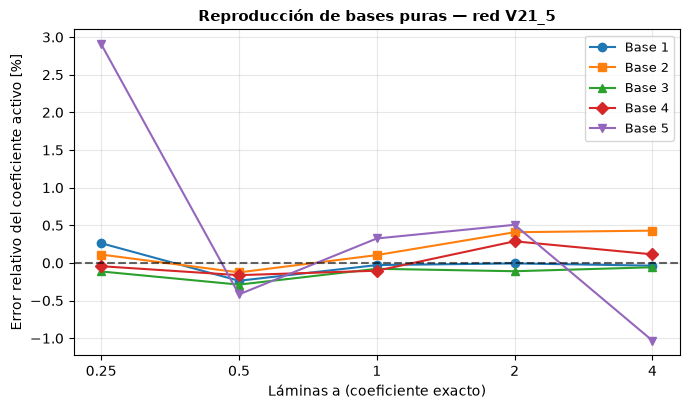

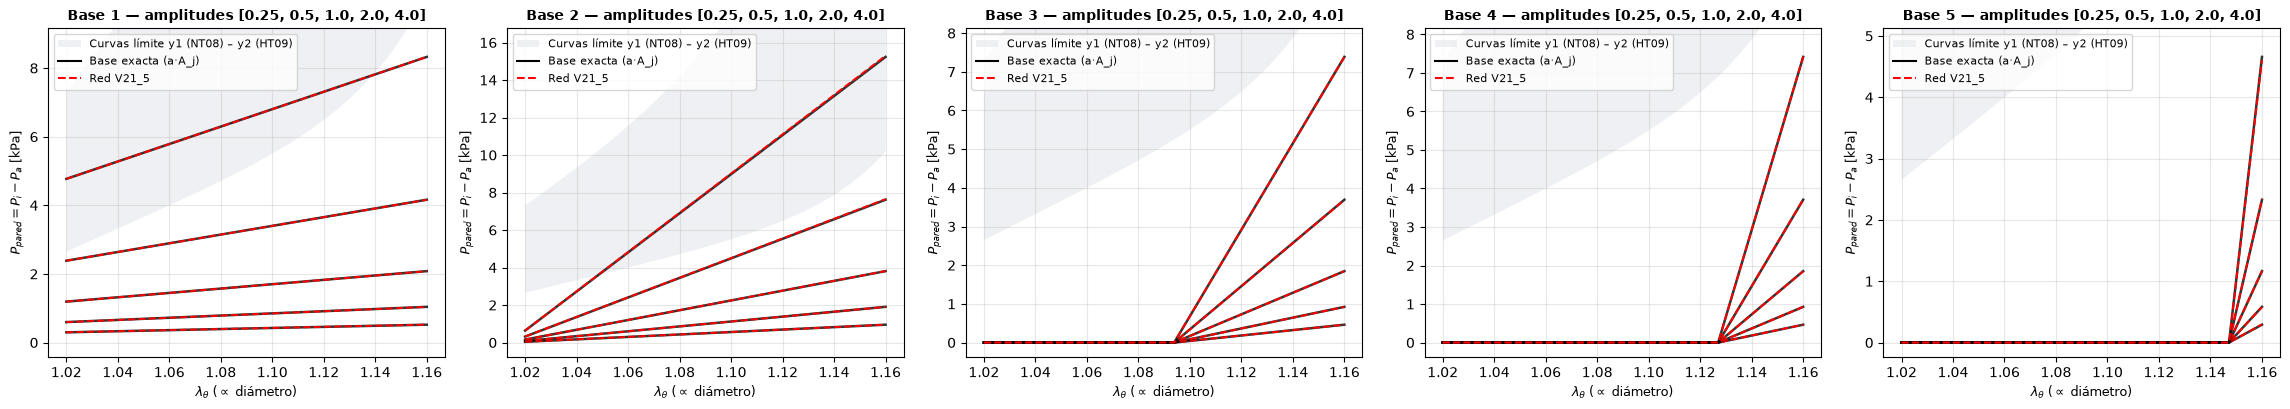

In [22]:
# ==============================================================================
# CÉLULA 14b: PRUEBA DE REPRODUCCIÓN DE LAS BASES (N bases × 4 amplitudes)
# ==============================================================================
"""
Entrada: y = a · A_j (una sola base, amplitud a).
Respuesta exacta: c = a · e_j. Se compara la red con el valor exacto y con el óptimo MCO.
V21: a = número de láminas. Todas las amplitudes quedan dentro del rango de la familia 'pura'
(láminas log-uniformes en [C_MIN_PURA_LAM = 0,1; C_GEN_MAX_j ≥ C_LAM]).
Las bases puras no son curvas fisiológicas; la familia 'pura' del dataset las cubre con ruido.
Para la base constante el R² no está definido (curva plana): se informa NaN y vale el error del coeficiente.
Requiere la Célula 14 (usa cargar_archivos_sistema y predecir_coeficientes).
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AMPLITUDES_TEST = [0.25, 0.5, 1.0, 2.0, 4.0]
RUIDO_REL_TEST_BASES = 0.0      # 0 = prueba limpia; p. ej. 0.005 = mismo ruido que la familia 'pura'
rng_bases = np.random.default_rng(SEED + 7)

x_b, A_b, modelo_b, sx_b, sy_b, off_b = cargar_archivos_sistema()
n_b = A_b.shape[1]

filas, curvas = [], []
for j in range(n_b):
    for a in AMPLITUDES_TEST:
        c_exacto = np.zeros(n_b)
        c_exacto[j] = a
        y = A_b @ c_exacto
        if RUIDO_REL_TEST_BASES > 0:
            y = np.maximum(y + rng_bases.normal(0.0, RUIDO_REL_TEST_BASES, size=y.shape) * np.abs(y), 0.0)
        c_crudo, c_rn = predecir_coeficientes(modelo_b, sx_b, sy_b, off_b, y)
        c_crudo, c_rn = c_crudo[0], c_rn[0]
        c_lsq = optimo_mc(A_b, y)
        m_rn, m_lsq = metricas_curva(y, A_b @ c_rn), metricas_curva(y, A_b @ c_lsq)
        fila = {"base": j + 1, "amplitud": a, "R2_red": m_rn["R2"], "NRMSE_red_pct": m_rn["NRMSE"],
                "MaxAE_red_kPa": m_rn["MaxAE"], "R2_opt": m_lsq["R2"],
                # error máximo relativo al NIVEL de la curva: definido también para la base constante,
                # donde R² y NRMSE no existen (varianza y rango nulos)
                "MaxAE_rel_nivel_pct": m_rn["MaxAE"] / max(float(np.abs(y).max()), 1e-12) * 100.0,
                "err_c_activo": c_rn[j] - a, "err_rel_c_activo_pct": (c_rn[j] - a) / a * 100.0,
                "max_c_inactivo": float(np.delete(c_rn, j).max()),
                "min_c_crudo": float(c_crudo.min())}
        for i in range(n_b):
            fila[f"c{i+1}_red"] = c_rn[i]
        filas.append(fila)
        curvas.append((j, a, y, A_b @ c_rn))

DF_BASES = pd.DataFrame(filas)
pd.set_option("display.width", 160)
print("\n" + "=" * 110)
print("🧱 REPRODUCCIÓN DE BASES PURAS (respuesta exacta: c = a·e_j)")
print("=" * 110)
print(DF_BASES[["base", "amplitud", "R2_red", "NRMSE_red_pct", "MaxAE_red_kPa", "MaxAE_rel_nivel_pct", "err_c_activo",
                "err_rel_c_activo_pct", "max_c_inactivo", "min_c_crudo"]].to_string(index=False, float_format=lambda v: f"{v:.5f}"))
print("-" * 110)
if np.isnan(DF_BASES["R2_red"]).any():
    print("(R² y NRMSE no están definidos para una base constante: curva sin variación; usar MaxAE_rel_nivel_pct)")
print(f"Peor R² red: {DF_BASES['R2_red'].min():.6f} | peor MaxAE relativo al nivel: "
      f"{DF_BASES['MaxAE_rel_nivel_pct'].max():.2f}% | peor |error relativo| en el coeficiente activo: "
      f"{DF_BASES['err_rel_c_activo_pct'].abs().max():.3f}% | máximo crosstalk: {DF_BASES['max_c_inactivo'].max():.5f}")
DF_BASES.to_csv(f"test_reproduccion_bases_{VERSION}.csv", index=False)
print(f"💾 'test_reproduccion_bases_{VERSION}.csv' guardado.")

# --- Error relativo del coeficiente activo vs. amplitud (la figura informativa para el artículo) ---
fig_e, ax_e = plt.subplots(figsize=(7, 4.2))
marcadores = ["o", "s", "^", "D", "v", "P"]
for j in range(n_b):
    d = DF_BASES[DF_BASES["base"] == j + 1]
    ax_e.plot(d["amplitud"], d["err_rel_c_activo_pct"], marker=marcadores[j % len(marcadores)], lw=1.5,
              label=f"Base {j+1}")
ax_e.axhline(0, color="black", linestyle="--", alpha=0.6)
ax_e.set_xscale("log")
ax_e.minorticks_off()
ax_e.set_xticks(AMPLITUDES_TEST)
ax_e.set_xticklabels([f"{a:g}" for a in AMPLITUDES_TEST])
ax_e.set_xlabel("Láminas a (coeficiente exacto)", fontsize=10)
ax_e.set_ylabel("Error relativo del coeficiente activo [%]", fontsize=10)
ax_e.set_title(f"Reproducción de bases puras — red {VERSION.upper()}", fontsize=11, fontweight="bold")
ax_e.grid(True, alpha=0.3)
ax_e.legend(fontsize=9)
plt.tight_layout()
plt.savefig(f"test_reproduccion_bases_error_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, n_b, figsize=(4.6 * n_b, 4.2), squeeze=False)
for j in range(n_b):
    ax = axes[0, j]
    for (jj, a, y, y_rn) in curvas:
        if jj != j:
            continue
        ax.plot(x_b, y, "k-", lw=1.8, alpha=0.8)
        ax.plot(x_b, y_rn, "r--", lw=1.4)
    ax.fill_between(x_b, np.interp(x_b, X_MESH_999, BANDA_INF), np.interp(x_b, X_MESH_999, BANDA_SUP), color="#e5e7eb", alpha=0.6, lw=0, label=ETQ_BANDA, zorder=0)
    _ymax_j = max(c[2].max() for c in curvas if c[0] == j)
    ax.set_ylim(-0.05 * _ymax_j, 1.1 * _ymax_j)
    ax.plot([], [], "k-", label="Base exacta (a·A_j)")
    ax.plot([], [], "r--", label=f"Red {VERSION.upper()}")
    ax.set_title(f"Base {j+1} — amplitudes {AMPLITUDES_TEST}", fontsize=10, fontweight="bold")
    ax.set_xlabel(ETQ_X, fontsize=9)
    ax.set_ylabel(ETQ_Y, fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(f"test_reproduccion_bases_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Célula 15 — Visualización de las bases (una lámina de cada material) con su fórmula (0,80 ≤ λ ≤ 1,16)

✅ Fórmulas verificadas contra el archivo de bases: |diferencia| máx. = 8.9e-16 kPa
   Pendientes S_j = pendiente máxima del espacio de trabajo / C_LAM (C_LAM = 6): cada curva es UNA lámina
   A_1(λ) = 6,35 max(0, λ - 0,8322)
   A_2(λ) = 26,07 max(0, λ - 1,0139)
   A_3(λ) = 27,93 max(0, λ - 1,0939)
   A_4(λ) = 56,18 max(0, λ - 1,1270)
   A_5(λ) = 90,98 max(0, λ - 1,1472)


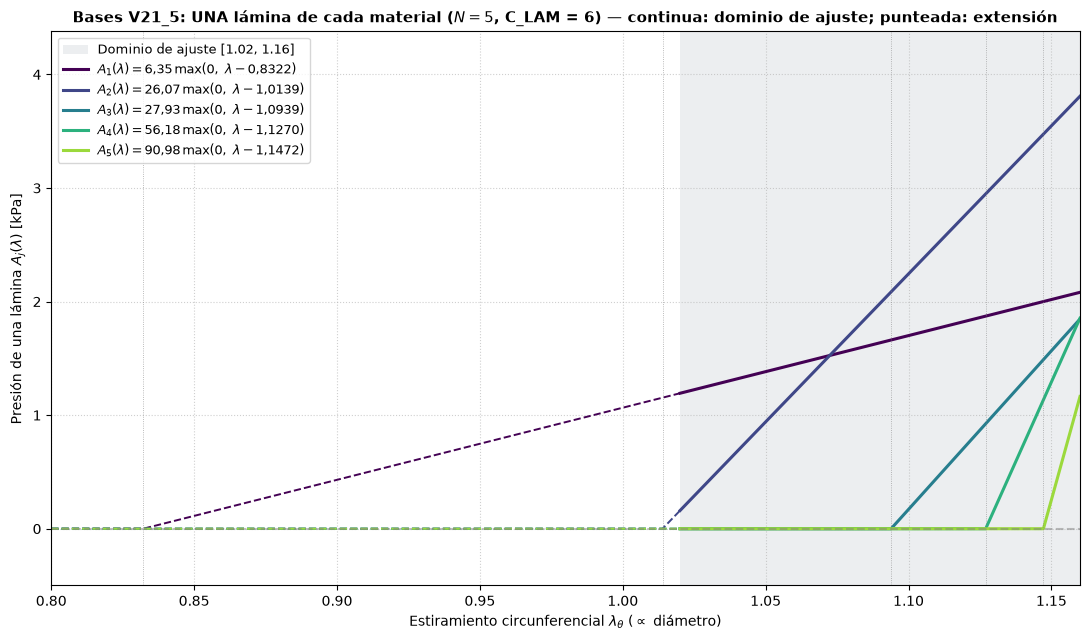

In [23]:
# ==============================================================================
# CÉLULA 15: VISUALIZACIÓN DE LAS BASES (fórmula de cada capa, dominio 0,80 <= λ <= 1,16)
# ==============================================================================
"""
Cada base se evalúa con su FÓRMULA (no con la malla de entrenamiento), en λ ∈ [LAMBDA_MIN_GRAF, LAMBDA_MAX_GRAF].
Línea continua: dominio medido y usado en el ajuste [X_MIN_DOMINIO, X_MAX_DOMINIO] (franja gris).
Línea punteada: fuera de ese dominio (la misma fórmula, extendida).
"""
import numpy as np
import matplotlib.pyplot as plt

LAMBDA_MIN_GRAF, LAMBDA_MAX_GRAF = 0.80, 1.16
lam = np.linspace(LAMBDA_MIN_GRAF, LAMBDA_MAX_GRAF, 2401)
s_mat = PARAMS_BASES.get("s_matriz")
nudos = list(PARAMS_BASES["knots"])
xm = X_MAX_DOMINIO


def _num(v, d=4):
    return f"{v:.{d}f}".replace(".", "{,}")


bases = []    # (función, etiqueta con la fórmula)
if s_mat is not None:
    C = float(A_base[:, 0].max()) / (1.0 - (s_mat / xm) ** 4)
    bases.append((lambda x, s=s_mat, C=C: C * np.maximum(0.0, 1.0 - (s / np.maximum(x, 1e-9)) ** 4) * (x >= s),
                  rf"$A_{{{len(bases)+1}}}(\lambda) = {_num(C, 3)}\,\left[1-\left(\frac{{{_num(s, 3)}}}{{\lambda}}\right)^{{4}}\right]$  (matriz, λ ≥ {s_mat:g})"))
for k in nudos:
    j = len(bases) + 1
    A_max_j = float(A_base[:, j - 1].max())       # valor de la capa en λ_max (columna del archivo de bases)
    if LEY_TELA == "lineal":
        C = A_max_j / (xm - k)                    # = S_j
        f = lambda x, k=k, C=C: C * np.maximum(0.0, x - k)
        etq = rf"$A_{{{j}}}(\lambda) = {_num(C, 2)}\,\max(0,\ \lambda - {_num(k)})$"
    else:
        C = A_max_j * xm / (xm - k)
        f = lambda x, k=k, C=C: C * np.maximum(0.0, x - k) / np.maximum(x, 1e-9)
        etq = rf"$A_{{{j}}}(\lambda) = {_num(C, 2)}\,\max(0,\ \lambda - {_num(k)})/\lambda$"
    bases.append((f, etq))

# Verificación: la fórmula coincide con la base exportada en la malla de entrenamiento
err_max = max(float(np.abs(f(X_MESH_999) - A_base[:, j]).max()) for j, (f, _) in enumerate(bases))
print(f"✅ Fórmulas verificadas contra el archivo de bases: |diferencia| máx. = {err_max:.1e} kPa")
print(f"   Pendientes S_j = pendiente máxima del espacio de trabajo / C_LAM (C_LAM = {C_LAM:g}): cada curva es UNA lámina")
for _, etq in bases:
    print("   " + etq.replace("$", "").replace("\\,", " ").replace("\\max", "max").replace("{,}", ",")
          .replace("\\lambda", "λ").replace("\\ ", " ").replace("\\left", "").replace("\\right", "")
          .replace("\\frac{", "(").replace("}{", ")/(").replace("{", "").replace("}", ""))

colores = plt.cm.viridis(np.linspace(0.0, 0.85, len(bases)))
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.axvspan(X_MIN_DOMINIO, X_MAX_DOMINIO, color="#e5e7eb", alpha=0.7, lw=0,
           label=f"Dominio de ajuste [{X_MIN_DOMINIO}, {X_MAX_DOMINIO}]")
dentro = (lam >= X_MIN_DOMINIO) & (lam <= X_MAX_DOMINIO)
for (f, etq), col in zip(bases, colores):
    y = f(lam)
    ax.plot(lam, np.where(dentro, y, np.nan), color=col, lw=2.2, label=etq)
    ax.plot(lam, np.where(dentro, np.nan, y), color=col, lw=1.4, ls="--")
for k in nudos:
    ax.axvline(k, color="gray", lw=0.6, ls=":", alpha=0.7)
ax.set_xlim(LAMBDA_MIN_GRAF, LAMBDA_MAX_GRAF)
ax.set_ylim(-0.5, 1.15 * max(float(f(np.array([LAMBDA_MAX_GRAF]))[0]) for f, _ in bases))
ax.set_xlabel(r"Estiramiento circunferencial $\lambda_\theta$ ($\propto$ diámetro)", fontsize=10)
ax.set_ylabel(r"Presión de una lámina $A_j(\lambda)$ [kPa]", fontsize=10)
ax.set_title(rf"Bases {VERSION.upper()}: UNA lámina de cada material ($N = {len(bases)}$, C_LAM = {C_LAM:g}) — "
             "continua: dominio de ajuste; punteada: extensión", fontsize=11, fontweight="bold")
ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig(f"bases_funcionales_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()